In [1]:
rm(list = ls())
options(stringsAsFactors = FALSE)
getwd()

[1] "/Users/luye/Library/Mobile Documents/com~apple~CloudDocs/Projects/Ongoing/202504ZL"

In [3]:
library(tidyverse)
library(data.table)
library(ggplot2)
library(dplyr)
library(readr)

# **Data preparation**

## **sample info**

In [4]:
# 定义 RNA-seq 数据文件路径
folder_path <- "./0-Data/final" 
sample_info_files <- list.files(path = folder_path, pattern = "_sample.*\\.csv$", full.names = TRUE)
# 打印结果
print(sample_info_files)

 [1] "./0-Data/final/2012Andersen_sample_info.csv"
 [2] "./0-Data/final/2013Sia_sample_info.csv"     
 [3] "./0-Data/final/2017Jusakual_sample_info.csv"
 [4] "./0-Data/final/2019Ahn_sample_info.csv"     
 [5] "./0-Data/final/2020Job_sample_info.csv"     
 [6] "./0-Data/final/2022Dong_sample_info.csv"    
 [7] "./0-Data/final/2023Deng_sample_info.csv"    
 [8] "./0-Data/final/2023Jeon_sample_info.csv"    
 [9] "./0-Data/final/2023Lee_sample_info.csv"     
[10] "./0-Data/final/2024Fan_sample_info.csv"     
[11] "./0-Data/final/TCGA-CHOL_sample_info.csv"   
[12] "./0-Data/final/TIGER-LC_sample_info.csv"    


In [11]:
# 初始化空列表存储样本信息
sample_info_list <- list()

for (file in sample_info_files) {
  data <- fread(file, data.table = FALSE)
  sample_info_list[[file]] <- data
}

# 使用rbind.fill合并
merged_sample_info <- plyr::rbind.fill(sample_info_list)
dim(merged_sample_info)
head(merged_sample_info)

[1] 1092   32

,SampleID,Study,Disease state,Race,Type,Platform,Subclass,Sex,Age at surgery,HBV,...,RNA_seq,RNA,T,N,M,Grade,ajcc_pathologic_n,ajcc_pathologic_t,ajcc_pathologic_m,Differentiation
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,GSM653074,2012Andersen,Cholangiocarcinoma Tumor,White,w/o,microarray,NA,NA,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
2,GSM653075,2012Andersen,Cholangiocarcinoma Tumor,White,w/o,microarray,NA,NA,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
3,GSM653076,2012Andersen,Cholangiocarcinoma Tumor,White,w/o,microarray,NA,NA,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
4,GSM653077,2012Andersen,Cholangiocarcinoma Tumor,White,w/o,microarray,NA,NA,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
5,GSM653078,2012Andersen,Cholangiocarcinoma Tumor,White,w/o,microarray,NA,NA,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
6,GSM653079,2012Andersen,Cholangiocarcinoma Tumor,White,w/o,microarray,NA,NA,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [14]:
# 保存样本信息
write.csv(merged_sample_info, "./sample_information.csv", row.names = FALSE)

In [8]:
sample_info <- readxl::read_excel("./sample_information.xlsx")
dim(sample_info)
head(sample_info)

[1] 1092   34

SampleID,Study,Platform,Sex,Age,Country,Race,iCCA classification,Subclass,Subclass-add,⋯,"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling,RNA
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
111,2022Dong,RNAseq (Illumina),Male,49,China,Asian,w/o,NA,IG2,⋯,8.4,36,5147,2.5,25.2,18,80,YES,NO,NA
113,2022Dong,RNAseq (Illumina),Male,59,China,Asian,w/o,NA,IG2,⋯,9.2,38,1.8,2.8,35,18,40,YES,NO,NA
115,2022Dong,RNAseq (Illumina),Male,74,China,Asian,w/o,S4,IG3,⋯,7.9,39,42.7,2.0,8.1999999999999993,11,29,YES,YES,NA
117,2022Dong,RNAseq (Illumina),Female,64,China,Asian,w/o,S3,IG3,⋯,14.1,47,2.8,1.0,7.9,17,27,YES,YES,NA
121,2022Dong,RNAseq (Illumina),Female,71,China,Asian,w/o,S4,IG3,⋯,8.6,42,215.1,1.4,24.9,10,23,YES,YES,NA
123,2022Dong,RNAseq (Illumina),Male,55,China,Asian,w/o,S3,IG2,⋯,17.8,44,2.1,0.8,30.4,89,384,YES,YES,NA


In [6]:
# 创建交叉表并添加边际总和
result_table <- addmargins(table(sample_info$Study, sample_info$Platform))

# 打印结果
print(result_table)

              
               Microarray (Affymetrix) Microarray (Illumina) RNAseq (Illumina)
  2012Andersen                       0                   104                 0
  2013Sia                            0                   149                 0
  2017Jusakual                       0                    83                 0
  2019Ahn                            0                     0                30
  2020Job                           78                     0                 0
  2022Dong                           0                     0               255
  2023Deng                           0                     0                84
  2023Jeon                           0                     0                59
  2023Lee                            0                     0                13
  2024Fan                            0                     0               114
  TCGA-CHOL                          0                     0                31
  TIGER-LC                          9

In [7]:
# 创建交叉表并添加边际总和
result_table <- addmargins(table(sample_info$Study, sample_info$Race))

# 打印结果
print(result_table)

              
               Asian Black Mixed White  Sum
  2012Andersen     0     0     0   104  104
  2013Sia          0     0     0   149  149
  2017Jusakual    57     0     2    24   83
  2019Ahn         30     0     0     0   30
  2020Job          0     0     0    78   78
  2022Dong       255     0     0     0  255
  2023Deng        84     0     0     0   84
  2023Jeon        59     0     0     0   59
  2023Lee         13     0     0     0   13
  2024Fan        114     0     0     0  114
  TCGA-CHOL        3     2     0    26   31
  TIGER-LC        92     0     0     0   92
  Sum            707     2     2   381 1092


In [8]:
table(sample_info$`iCCA classification`)


large duct type small duct type             w/o 
             29              86             977 

## **RNA data**

In [4]:
# 定义 RNA-seq 数据文件路径
folder_path <- "./0-Data/final" 
rna_seq_files <- list.files(path = folder_path, pattern = "_rnaseq.*\\.csv$", full.names = TRUE)
# 打印结果
print(rna_seq_files)

 [1] "./0-Data/final/2012Andersen_rnaseq.csv" 
 [2] "./0-Data/final/2013Sia_rnaseq.csv"      
 [3] "./0-Data/final/2017Jusakual_rnaseq1.csv"
 [4] "./0-Data/final/2017Jusakual_rnaseq2.csv"
 [5] "./0-Data/final/2019Ahn_rnaseq.csv"      
 [6] "./0-Data/final/2020Job_rnaseq.csv"      
 [7] "./0-Data/final/2022Dong_rnaseq.csv"     
 [8] "./0-Data/final/2023Deng_rnaseq.csv"     
 [9] "./0-Data/final/2023Jeon_rnaseq.csv"     
[10] "./0-Data/final/2023Lee_rnaseq.csv"      
[11] "./0-Data/final/2024Fan_rnaseq.csv"      
[12] "./0-Data/final/TCGA-CHOL_rnaseq.csv"    
[13] "./0-Data/final/TIGER-LC_rnaseq.csv"     


### *RNAseq (Illumina)*

In [58]:
# 读取TPM矩阵
tpm_2019Ahn <- read.csv(rna_seq_files[5])

In [59]:
tpm_data <- tpm_2019Ahn
# 查看数据基本情况
dim(tpm_data)
head(tpm_data)

[1] 39376    31

,X...Gene,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,...,GSM2883948,GSM2883949,GSM2883950,GSM2883951,GSM2883952,GSM2883953,GSM2883954,GSM2883955,GSM2883956,GSM2883957
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,DDX11L1,0.05688,0.09963,0.1509,0.1255,0.5005,0.2791,0.05611,0.0574,0.3103,...,0.2887,0.3094,0.4356,0.1529,1.4500,0.24550,0.3571,0.1216,0.5394,0.2938
2,WASH7P,16.47000,17.86000,12.9200,56.6200,34.4700,12.5600,14.72000,19.2500,27.0500,...,19.1900,20.6900,11.6200,24.8800,30.5400,37.83000,33.2100,13.4400,23.7800,20.3400
3,MIR6859-1,5.52800,7.26100,4.8870,32.0200,30.4000,3.3910,5.45300,8.3680,4.1110,...,11.2200,8.4550,4.5350,5.5730,22.9000,15.51000,18.5900,0.9847,9.1730,0.7931
4,MIR1302-2HG,0.00000,0.00000,0.0000,0.0000,0.0000,0.0000,0.00000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.2227,0.00000,0.1566,0.0000,0.3312,0.0000
5,MIR1302-2,0.00000,0.00000,0.0000,0.0000,0.0000,0.0000,0.00000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.00000,0.0000,0.0000,0.0000,0.0000
6,FAM138A,0.00000,0.00000,0.0000,0.0000,0.0000,0.0000,0.00000,0.0000,0.0000,...,0.0844,0.0000,0.0000,0.0000,0.0000,0.07178,0.0000,0.0000,0.0000,0.0000


In [60]:
######* 去除重复基因，得到最终表达矩阵 ######
# 计算行平均值，按降序排列
expression_cols <- setdiff(names(tpm_data), c("X...Gene","Gene"))
index <- order(rowMeans(tpm_data[, expression_cols]), decreasing = TRUE)
# 调整表达谱的基因顺序
tpm_data_ordered <- tpm_data[index,]
#对于有重复的基因，保留第一次出现的那个，即行平均值大的那个
keep <- !duplicated(tpm_data_ordered$X...Gene)
#得到最后处理之后的表达谱矩阵
tpm_data_nodup <- tpm_data_ordered[keep,]
rownames(tpm_data_nodup) <- NULL
tpm_data_nodup <- column_to_rownames(tpm_data_nodup,var = "X...Gene")
dim(tpm_data_nodup)
head(tpm_data_nodup)

[1] 39374    30

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,GSM2883948,GSM2883949,GSM2883950,GSM2883951,GSM2883952,GSM2883953,GSM2883954,GSM2883955,GSM2883956,GSM2883957
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
COX3,21900,31300,24800,9622,13900,44600,23100,53900,37700,15900,...,39600,38700,13900,29200,14800,25700,42700,29500,13700,16900
COX2,60900,20300,13700,12700,12900,53500,18100,27800,33500,16100,...,23600,39200,7730,24700,9038,17000,49600,41600,21600,13200
COX1,38800,27900,16300,9092,10000,11000,18600,38600,9690,15400,...,36200,14100,13400,30400,12500,7046,18700,30400,9268,6908
ATP6,16000,18200,15000,9129,9609,19700,22600,33100,16900,8535,...,25000,25200,7147,18800,8920,16200,31700,23900,10400,6702
RNR2,31500,14300,11200,4098,8023,12500,12100,20900,17200,13400,...,33200,13100,9261,15200,5919,12600,23300,40100,6908,9107
MIR10393,19700,7370,9844,19700,37800,13300,12800,8142,5318,16300,...,10400,15800,7996,15900,6934,19000,6127,11800,15600,17900


In [17]:
samples <- sample_info$SampleID[sample_info$Study =="2024Fan"]
# 移除列名中的"X"前缀
colnames(tpm_data_nodup) <- sub("^X", "", colnames(tpm_data_nodup))
tpm_data_nodup <- tpm_data_nodup[,colnames(tpm_data_nodup) %in% samples]
dim(tpm_data_nodup)

[1] 55880   114

In [40]:
samples <- sample_info$RNA[sample_info$Study =="2023Deng"]
colnames(tpm_data_nodup) <- gsub("\\.", "_", colnames(tpm_data_nodup))
tpm_data_nodup <- tpm_data_nodup[,colnames(tpm_data_nodup) %in% samples]
dim(tpm_data_nodup)

[1] 12667    84

In [53]:
colnames(tpm_data_nodup) <- sub("^X", "", colnames(tpm_data_nodup))

In [61]:
# 检查缺失值
sum(is.na(tpm_data_nodup))

# 如有必要，处理缺失值
if(sum(is.na(tpm_data_nodup)) > 0) {
  # 可以用0填充或使用其他方法
  tpm_data_nodup[is.na(tpm_data_nodup)] <- 0
}

[1] 0

In [62]:
# 计算在多少样本中表达量大于阈值(例如TPM>1)
expressed_samples <- rowSums(tpm_data_nodup > 1)

# 保留在至少20%样本中表达的基因
min_samples <- ncol(tpm_data_nodup) * 0.2
filtered_tpm <- tpm_data_nodup[expressed_samples >= min_samples, ]
cat("Original number of genes:", nrow(tpm_data_nodup), "\n")
cat("number of genes after filtering:", nrow(filtered_tpm), "\n")

Original number of genes: 39374 
number of genes after filtering: 18128 


In [43]:
# 函数：将FPKM转换为TPM
fpkm_to_tpm <- function(fpkm_matrix) {
  # 对每个样本进行转换
  tpm_matrix <- apply(fpkm_matrix, 2, function(x) {
    # TPM = (FPKM / sum(FPKM)) * 1e6
    return((x / sum(x)) * 1e6)
  })
  
  # 确保行名保持不变
  rownames(tpm_matrix) <- rownames(fpkm_matrix)
  
  return(tpm_matrix)
}
# 转换为TPM
filtered_tpm <- fpkm_to_tpm(filtered_tpm)
filtered_tpm <- as.data.frame(filtered_tpm)

In [63]:
log2_tpm <- log2(filtered_tpm + 1)

In [13]:
tpm_tcga <- filtered_tpm
log2tpm_tcga <- log2_tpm
# 将矩阵/数据框的列名中的点替换为下划线
colnames(tpm_tcga) <- gsub("\\.", "-", colnames(tpm_tcga))
colnames(log2tpm_tcga) <- gsub("\\.", "-", colnames(log2tpm_tcga))
dim(tpm_tcga)
head(tpm_tcga)
dim(log2tpm_tcga)
head(log2tpm_tcga)
all(colnames(tpm_tcga) %in% sample_info$SampleID[sample_info$Study =="TCGA-CHOL"]) # 应为 TRUE

[1] 20013    31

,TCGA-W5-AA30-01A,TCGA-ZH-A8Y2-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2Z-01A,TCGA-W5-AA33-01A,TCGA-3X-AAV9-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y5-01A,TCGA-4G-AAZO-01A,TCGA-W5-AA36-01A,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MT-CO3,38873.52,19218.005,43143.57,23555.03,36752.67,28315.59,26104.929,15979.489,27781.14,47394.67,...,25317.45,40384.67,44329.43,43933.06,22510.99,17765.914,35982.42,25016.151,47653.76,30913.79
MT-CO2,37699.86,17934.094,39496.16,12853.30,33202.08,17283.13,23431.800,21207.088,26632.27,53401.24,...,35949.26,23083.17,32392.85,33294.50,22920.13,15886.302,22555.49,24891.412,27402.51,25028.60
MT-CO1,31035.62,11983.558,38929.71,17496.44,26640.99,27580.93,32998.658,7588.208,38411.00,31275.25,...,29021.36,13443.80,41661.87,29895.83,23243.51,10681.192,27197.03,18479.365,14724.84,35030.48
MT-ND4,40103.43,17929.045,46477.45,10780.57,26750.11,14289.32,22125.357,18884.011,29812.62,26431.60,...,50642.23,20736.36,49026.78,20544.81,20246.01,14482.201,15444.81,18013.070,19055.46,25886.36
MT-RNR2,10921.70,11844.246,35365.89,10140.21,22828.05,10080.43,9838.143,3419.421,19835.21,89668.29,...,11348.90,11041.59,42741.60,28016.50,10495.90,5669.124,13447.96,8800.471,19999.87,17083.85
MT-CYB,28020.27,8384.658,15698.10,11243.76,23602.11,12379.30,14271.376,16461.552,17760.86,17019.23,...,19503.38,15550.59,10952.75,15628.47,11976.97,7618.282,9737.06,12395.062,12839.20,13383.81


[1] 20013    31

,TCGA-W5-AA30-01A,TCGA-ZH-A8Y2-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2Z-01A,TCGA-W5-AA33-01A,TCGA-3X-AAV9-01A,TCGA-ZH-A8Y6-01A,TCGA-ZH-A8Y5-01A,TCGA-4G-AAZO-01A,TCGA-W5-AA36-01A,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MT-CO3,15.24654,14.23025,15.39689,14.52381,15.16560,14.78936,14.67209,13.96402,14.76187,15.53247,...,14.62790,15.30156,15.43601,15.42305,14.45841,14.11691,15.13504,14.61063,15.54033,14.91601
MT-CO2,15.20231,14.13050,15.26946,13.64996,15.01903,14.07716,14.51624,14.37233,14.70094,15.70461,...,15.13371,14.49462,14.98343,15.02304,14.48439,13.95559,14.46125,14.60342,14.74207,14.61135
MT-CO1,14.92168,13.54889,15.24862,14.09486,14.70141,14.75144,15.01016,12.88973,15.22927,14.93278,...,14.82488,13.71476,15.34647,14.86770,14.50460,13.38292,14.73121,14.17371,13.84606,15.09636
MT-ND4,15.29147,14.13009,15.50427,13.39628,14.70731,13.80275,14.43348,14.20495,14.86368,14.69003,...,15.62808,14.33994,15.58131,14.32656,14.30542,13.82209,13.91493,14.13684,14.21799,14.65996
MT-RNR2,13.41504,13.53202,15.11011,13.30794,14.47858,13.29941,13.26432,11.73996,14.27585,16.45233,...,13.47039,13.43079,15.38339,14.77404,13.35768,12.46916,13.71521,13.10353,14.28778,14.06043
MT-CYB,14.77423,13.03371,13.93839,13.45696,14.52669,13.59576,13.80094,14.00690,14.11649,14.05496,...,14.25151,13.92477,13.41914,13.93198,13.54810,12.89544,13.24942,13.59759,13.64838,13.70831


[1] TRUE

In [21]:
tpm_2024Fan <- filtered_tpm
log2tpm_2024Fan <- log2_tpm
dim(tpm_2024Fan)
head(tpm_2024Fan)
dim(log2tpm_2024Fan)
head(log2tpm_2024Fan)
all(colnames(tpm_2024Fan) %in% sample_info$SampleID[sample_info$Study =="2024Fan"]) # 应为 TRUE

[1] 20992   114

,219016260FR,219019500FR,219013111FR,219013176FR,219016236FR,219016241FR,219013115FR,219013123FR,219016253FR,219013142FR,...,219013172FR,219016268FR,219016247FR,219013127FR,219013170FR,219013118FR,219013757FR,219013144FR,219013119FR,219013102FR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MT-ND4L,631115.69,704387.44,419735.50,378112.12,572887.750,519809.62,457055.19,586220.12,588358.88,598862.000,...,516912.66,698321.750,522513.19,628632.12,654343.94,508636.78,723484.375,576886.94,396741.91,476662.69
MT-TC,33859.79,41627.04,73885.13,110799.98,94602.492,61101.90,36856.23,40730.31,61660.99,51328.273,...,38278.00,78767.875,55751.34,61985.00,63655.04,62507.05,57824.746,120926.15,162087.16,81487.85
MT-ATP8,45879.68,52954.37,40758.25,30444.48,40971.801,31875.33,39053.07,50828.21,47778.23,44389.301,...,39781.47,46699.984,34123.81,51242.63,57587.73,45281.57,42741.047,41628.96,24425.77,38225.20
RN7SL1,22760.50,23796.18,72236.27,47031.55,3540.955,16316.22,59849.71,37703.25,14454.65,8134.869,...,71367.68,25214.000,35485.44,30053.32,21959.92,67971.60,5836.704,26016.09,64510.65,95908.48
RN7SL2,22580.24,17214.30,57315.73,44376.86,4370.270,18605.51,53069.46,32441.65,13835.08,6171.634,...,54917.46,21733.240,26453.53,25583.85,19869.71,49541.64,4970.857,22282.13,55888.84,83648.15
RN7SK,16289.85,12684.87,40625.66,27874.86,18018.521,23963.05,36364.71,18757.61,29423.92,12461.071,...,21927.74,9826.166,28942.78,15984.39,10219.36,16798.86,19284.146,16744.01,31423.00,14036.92


[1] 20992   114

,219016260FR,219019500FR,219013111FR,219013176FR,219016236FR,219016241FR,219013115FR,219013123FR,219016253FR,219013142FR,...,219013172FR,219016268FR,219016247FR,219013127FR,219013170FR,219013118FR,219013757FR,219013144FR,219013119FR,219013102FR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MT-ND4L,19.26755,19.42601,18.67912,18.52846,19.12790,18.98763,18.80201,19.16109,19.16634,19.19187,...,18.97956,19.41353,18.99511,19.26186,19.31969,18.95628,19.46460,19.13793,18.59784,18.86261
MT-TC,15.04733,15.34527,16.17302,16.75761,16.52961,15.89895,15.16966,15.31385,15.91209,15.64749,...,15.22427,16.26534,15.76674,15.91965,15.95801,15.93175,15.81942,16.88378,17.30642,16.31432
MT-ATP8,15.48560,15.69249,15.31484,14.89394,15.32238,14.96020,15.25319,15.63337,15.54410,15.43796,...,15.27985,15.51117,15.05853,15.64509,15.81350,15.46667,15.38337,15.34533,14.57618,15.22227
RN7SL1,14.47431,14.53850,16.14046,15.52137,11.79033,13.99411,15.86908,15.20244,13.81935,12.99008,...,16.12300,14.62199,15.11498,14.87528,14.42265,16.05267,12.51119,14.66717,15.97727,16.54939
RN7SL2,14.46284,14.07140,15.80667,15.43755,12.09384,14.18352,15.69562,14.98560,13.75615,12.59167,...,15.74500,14.40768,14.69123,14.64300,14.27836,15.59638,12.27957,14.44366,15.77030,16.35206
RN7SK,13.99177,13.63093,15.31014,14.76673,14.13727,14.54858,15.15029,14.19527,14.84475,13.60526,...,14.42054,13.26256,14.82097,13.96447,13.31916,14.03616,14.23520,14.03144,14.93958,13.77704


[1] TRUE

In [29]:
tpm_2023Lee <- filtered_tpm
log2tpm_2023Lee <- log2_tpm
dim(tpm_2023Lee)
head(tpm_2023Lee)
dim(log2tpm_2023Lee)
head(log2tpm_2023Lee)
all(colnames(tpm_2023Lee) %in% sample_info$SampleID[sample_info$Study =="2023Lee"]) # 应为 TRUE

[1] 17611    13

,GSM6654037,GSM6654038,GSM6654039,GSM6654040,GSM6654041,GSM6654042,GSM6654043,GSM6654044,GSM6654045,GSM6654046,GSM6654047,GSM6654048,GSM6654049
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
COX1,48100,86000,20500,37200,28300,38500,28500,43100,51100,42300.000,4.690e+04,25900,69900.000
COX3,27800,60700,14000,30100,21000,24800,20100,27400,32700,27100.000,3.470e+04,20500,50700.000
COX2,34800,34900,12100,38200,17900,25900,16400,25000,36600,26000.000,5.590e+04,19600,45800.000
ND4,23600,25700,8948,37300,23300,31700,15900,31300,27200,23100.000,3.100e+04,11500,31500.000
ATP6,24800,44600,6378,31400,18500,23700,11600,31400,20900,13100.000,2.570e+04,11600,29100.000
APOA2,31600,3908,75400,56400,11500,16300,68600,16100,0,1.031,3.621e-01,0,1.907


[1] 17611    13

,GSM6654037,GSM6654038,GSM6654039,GSM6654040,GSM6654041,GSM6654042,GSM6654043,GSM6654044,GSM6654045,GSM6654046,GSM6654047,GSM6654048,GSM6654049
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
COX1,15.55378,16.39207,14.32341,15.18305,14.78857,15.23261,14.79872,15.39543,15.64106,15.36840,15.5173311,14.66072,16.093025
COX3,14.76285,15.88943,13.77324,14.87752,14.35817,14.59811,14.29498,14.74194,14.99705,14.72606,15.0826896,14.32341,15.629727
COX2,15.08684,15.09098,13.56284,15.22132,14.12775,14.66072,14.00150,14.60970,15.15960,14.66628,15.7705865,14.25864,15.483091
ND4,14.52656,14.64954,13.12751,15.18693,14.50810,14.95224,13.95683,14.93392,14.73137,14.49567,14.9200271,13.48947,14.943110
ATP6,14.59811,15.44479,12.63911,14.93852,14.17532,14.53266,13.50196,14.93852,14.35128,13.67739,14.6495369,13.50196,14.828781
APOA2,14.94768,11.93258,16.20230,15.78343,13.48947,13.99267,16.06594,13.97486,0.00000,1.02219,0.4458326,0.00000,1.539531


[1] TRUE

In [36]:
tpm_2023Jeon <- filtered_tpm
log2tpm_2023Jeon <- log2_tpm
dim(tpm_2023Jeon)
head(tpm_2023Jeon)
dim(log2tpm_2023Jeon)
head(log2tpm_2023Jeon)
all(colnames(tpm_2023Jeon) %in% sample_info$SampleID[sample_info$Study =="2023Jeon"]) # 应为 TRUE

[1] 18345    59

,GSM5418226,GSM5418227,GSM5418228,GSM5418229,GSM5418230,GSM5418231,GSM5418232,GSM5418233,GSM5418234,GSM5418235,...,GSM5418275,GSM5418276,GSM5418277,GSM5418278,GSM5418279,GSM5418280,GSM5418281,GSM5418282,GSM5418283,GSM5418284
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
COX3,19300,37400,18100,31300,28000,48500,16000,36100,53400,19300,...,25300,48200,27000,37400,53900,13000,30200,14600,43900,25700
COX2,27000,24300,36400,41700,25600,41500,18700,23500,69700,23900,...,16300,53000,24700,32400,29600,14200,24300,16700,38700,22100
ATP6,27500,18900,11000,28800,19500,33900,15400,20800,58500,13600,...,19500,65500,28800,29500,40800,11300,23700,16000,42800,20200
COX1,29100,14300,21400,16000,30100,55600,18600,22400,32600,13900,...,25300,77800,29400,33300,23800,12500,20500,7909,50800,25400
ND4,18300,17800,9737,26300,18000,30800,14000,23100,51500,9213,...,18600,54100,24200,37700,36400,13200,19600,13900,34800,26200
ATP8,21700,12300,5178,20100,16200,23500,11600,16100,49900,10900,...,17600,56800,19800,23900,30800,8825,17100,11400,32800,17300


[1] 18345    59

,GSM5418226,GSM5418227,GSM5418228,GSM5418229,GSM5418230,GSM5418231,GSM5418232,GSM5418233,GSM5418234,GSM5418235,...,GSM5418275,GSM5418276,GSM5418277,GSM5418278,GSM5418279,GSM5418280,GSM5418281,GSM5418282,GSM5418283,GSM5418284
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
COX3,14.23639,15.19079,14.14378,14.93392,14.77319,15.56573,13.96587,15.13975,15.70458,14.23639,...,14.62691,15.55678,14.72073,15.19079,15.71802,13.66633,14.88231,13.83378,15.42197,14.64954
COX2,14.72073,14.56873,15.15169,15.34779,14.64391,15.34086,14.19083,14.52043,16.08889,14.54478,...,13.99267,15.69373,14.59228,14.98375,14.85336,13.79370,14.56873,14.02765,15.24008,14.43182
ATP6,14.74720,14.20617,13.42535,14.81383,14.25126,15.04904,13.91074,14.34437,15.83617,13.73143,...,14.25126,15.99923,14.81383,14.84848,15.31632,13.46416,14.53266,13.96587,15.38536,14.30214
COX1,14.82878,13.80383,14.38539,13.96587,14.87752,15.76282,14.18309,14.45128,14.99263,13.76290,...,14.62691,16.24750,14.84358,15.02328,14.53873,13.60976,14.32341,12.94946,15.63257,14.63260
ND4,14.15963,14.11967,13.24941,14.68283,14.13579,14.91069,13.77324,14.49567,15.65231,13.16961,...,14.18309,15.72337,14.56278,15.20232,15.15169,13.68836,14.25864,13.76290,15.08684,14.67733
ATP8,14.40547,13.58649,12.33846,14.29498,13.98380,14.52043,13.50196,13.97486,15.60678,13.41217,...,14.10337,15.79363,14.27329,14.54478,14.91069,13.10754,14.06179,13.47687,15.00145,14.07857


[1] TRUE

In [ ]:
# 基本替换函数
replace_colnames_with_sampleID <- function(expr_matrix, sample_info, current_id_col = "RNA", target_id_col = "SampleID") {
  # 获取当前列名
  current_colnames <- colnames(expr_matrix)
  
  # 创建映射字典
  id_mapping <- setNames(sample_info[[target_id_col]], sample_info[[current_id_col]])
  
  # 替换列名 (只替换能找到映射的列名)
  new_colnames <- current_colnames
  matched_indices <- which(current_colnames %in% names(id_mapping))
  
  if(length(matched_indices) > 0) {
    new_colnames[matched_indices] <- id_mapping[current_colnames[matched_indices]]
  }
  
  # 应用新列名
  colnames(expr_matrix) <- new_colnames
  
  # 返回结果和匹配信息
  return(list(
    matrix = expr_matrix,
    total_cols = length(current_colnames),
    matched_cols = length(matched_indices),
    match_percent = round(length(matched_indices) / length(current_colnames) * 100, 2)
  ))
}

In [46]:
filtered_tpm <- replace_colnames_with_sampleID(filtered_tpm, sample_info)
log2_tpm <- replace_colnames_with_sampleID(log2_tpm, sample_info)

In [49]:
tpm_2023Deng <- filtered_tpm[[1]]
log2tpm_2023Deng <- log2_tpm[[1]]
dim(tpm_2023Deng)
head(tpm_2023Deng)
dim(log2tpm_2023Deng)
head(log2tpm_2023Deng)
all(colnames(tpm_2023Deng) %in% sample_info$SampleID[sample_info$Study =="2023Deng"]) # 应为 TRUE

[1] 12666    84

,CCA#101,CCA#32,CCA#33,CCA#34,CCA#36,CCA#37,CCA#38,CCA#46,CCA#47,CCA#50,...,CCA#150,CCA#152,CCA#155,CCA#169,CCA#174,CCA#30,CCA#35,CCA#56,CCA#177,CCA#179
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MIR3648-2,47942.29,122122.62,32033.18,23076.78,41493.46,35817.20,67378.68,28065.51,32448.31,0.00000,...,284395.424,84498.38,26549.22,91519.39,72249.73,39549.47,46645.50,48878.32,129394.06,36542.04
RNU1-3,15060.36,25746.11,22651.27,31654.64,29504.62,22259.43,30207.82,28008.51,31161.93,40.33183,...,10267.017,11966.23,18756.64,16665.42,20862.51,17920.71,23127.42,17001.42,17826.73,16834.32
RNU1-4,15052.05,25714.73,22194.55,31667.67,29558.83,22216.07,30135.33,27998.93,30747.82,0.00000,...,10022.795,11906.55,18716.59,16665.40,20859.92,17938.70,23137.30,17038.16,17851.59,16788.21
RNU1-1,14992.83,25458.96,22410.38,31344.07,29261.64,22097.65,29982.69,27768.63,30846.28,23.57115,...,10211.954,11890.29,18645.41,16504.97,20729.10,17776.86,22894.74,17273.06,17636.66,16632.55
RNU1-2,14983.78,25458.21,21923.40,31342.47,29230.54,22041.75,29923.62,27803.30,30421.43,25.30820,...,9981.307,11857.97,18584.49,16494.05,20729.29,17808.53,22908.75,16973.35,17654.93,16592.18
RNVU1-7,15345.02,25095.89,22364.53,31155.21,29017.44,21927.85,30261.21,27186.04,30243.22,55.32828,...,10152.567,11985.83,18412.82,16551.98,20516.62,18150.89,22644.42,16300.24,17971.29,16403.08


[1] 12666    84

,CCA#101,CCA#32,CCA#33,CCA#34,CCA#36,CCA#37,CCA#38,CCA#46,CCA#47,CCA#50,...,CCA#150,CCA#152,CCA#155,CCA#169,CCA#174,CCA#30,CCA#35,CCA#56,CCA#177,CCA#179
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MIR3648-2,15.54904,16.89798,14.96732,14.49422,15.34063,15.12841,16.04003,14.77656,14.98590,0.000000,...,18.11754,16.36665,14.69644,16.48181,16.14072,15.27141,15.50948,15.57694,16.98142,15.15731
RNU1-3,13.87856,14.65212,14.46737,14.95017,14.84870,14.44219,14.88268,14.77363,14.92754,5.369181,...,13.32587,13.54680,14.19519,14.02466,14.34869,14.12942,14.49738,14.05345,14.12184,14.03920
RNU1-4,13.87777,14.65036,14.43798,14.95077,14.85135,14.43938,14.87922,14.77314,14.90824,0.000000,...,13.29114,13.53959,14.19211,14.02465,14.34852,14.13087,14.49800,14.05657,14.12385,14.03525
RNU1-1,13.87208,14.63594,14.45194,14.93595,14.83677,14.43167,14.87189,14.76122,14.91286,4.618893,...,13.31811,13.53762,14.18661,14.01070,14.33944,14.11779,14.48279,14.07632,14.10637,14.02181
RNU1-2,13.87121,14.63590,14.42025,14.93588,14.83524,14.42802,14.86905,14.76302,14.89285,4.717441,...,13.28516,13.53369,14.18189,14.00975,14.33945,14.12036,14.48367,14.05107,14.10787,14.01830
RNVU1-7,13.90558,14.61522,14.44899,14.92723,14.82468,14.42054,14.88523,14.73063,14.88437,5.815787,...,13.30970,13.54916,14.16850,14.01480,14.32458,14.14783,14.46693,13.99269,14.13349,14.00177


[1] TRUE

In [ ]:
tpm_2022Dong <- filtered_tpm
log2tpm_2022Dong <- log2_tpm
dim(tpm_2022Dong)
head(tpm_2022Dong)
dim(log2tpm_2022Dong)
head(log2tpm_2022Dong)
all(colnames(tpm_2022Dong) %in% sample_info$SampleID[sample_info$Study =="2022Dong"]) # 应为 TRUE

[1] 15511   255

,111,113,115,117,121,123,125,127,131,133,...,965,971,973,975,977,981,983,987,993,995
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
B2M,11036.8212,5133.102,5420.4365,5616.843,5632.773,25363.396,9761.978,24464.2989,25932.961,19376.543,...,20705.858,13259.597,10111.4789,30749.234,14869.244,13746.992,6964.870,13611.856,12693.998,9697.026
C3,20751.9300,23044.470,40202.6500,35896.600,1940.667,14892.710,5681.317,246.3534,1161.327,3547.645,...,13012.370,6350.007,26576.2600,10608.250,13506.990,14105.380,19272.450,11254.600,11115.080,4301.791
HIST1H4J,12036.4800,2560.765,16033.7000,10539.680,9117.895,7321.151,30716.260,9863.0020,12349.030,16551.960,...,8401.388,26194.540,1818.6290,11722.880,11228.150,12396.690,3029.390,13109.610,5679.962,1770.292
TMSB4X,731.2809,2694.974,1562.1850,2436.086,12370.080,8354.563,5104.185,4330.5560,13695.340,13963.900,...,2334.091,1203.415,2451.0940,6751.743,5436.649,12275.810,5068.551,6438.100,6384.777,9881.964
TPT1,9790.4050,10258.300,5181.0370,8385.359,9896.427,5908.758,9667.644,8750.7070,7173.731,9840.501,...,12414.760,4695.919,3561.1700,7785.760,8828.479,7016.145,9519.932,6127.988,11161.100,10352.270
SPP1,6612.4450,10215.710,510.0441,3754.215,9102.456,8153.239,3134.374,18740.0700,2651.144,1719.998,...,2061.053,1357.181,840.8419,15428.670,20375.740,5710.787,19398.970,13964.970,19404.410,6677.348


[1] 15511   255

,111,113,115,117,121,123,125,127,131,133,...,965,971,973,975,977,981,983,987,993,995
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
B2M,13.430168,12.32590,12.404459,12.45580,12.45989,14.63052,13.25311,14.57845,14.66255,14.24210,...,14.33782,13.69486,13.303849,14.90831,13.86014,13.74693,12.76609,13.73268,13.63197,13.24348
C3,14.341027,14.49220,15.295039,15.13160,10.92308,13.86242,12.47226,7.95043,10.18280,11.79305,...,13.66771,12.63277,14.697905,13.37304,13.72153,13.78406,14.23433,13.45836,13.44036,12.07106
HIST1H4J,13.555246,11.32292,13.968910,13.36368,13.15464,12.83805,14.90676,13.26796,13.59223,14.01480,...,13.03658,14.67703,10.829429,13.51716,13.45496,13.59778,11.56529,13.67845,12.47192,10.79059
TMSB4X,9.516253,11.39659,10.610273,11.25094,13.59468,13.02852,12.31775,12.08067,13.74150,13.76952,...,11.18926,10.23412,11.259799,12.72126,12.40877,13.58365,12.30764,12.65264,12.64065,13.27073
TPT1,13.257300,13.32464,12.339304,13.03383,13.27284,12.52888,13.23910,13.09535,12.80871,13.26466,...,13.59988,12.19750,11.798541,12.92681,13.10811,12.77667,13.21689,12.58143,13.44632,13.33780
SPP1,12.691186,13.31864,8.997304,11.87468,13.15220,12.99333,11.61442,14.19392,11.37294,10.74903,...,11.00987,10.40746,9.717406,13.91342,14.31464,12.47973,14.24377,13.76963,14.24417,12.70528


[1] TRUE

In [64]:
tpm_2019Ahn <- filtered_tpm
log2tpm_2019Ahn <- log2_tpm
dim(tpm_2019Ahn)
head(tpm_2019Ahn)
dim(log2tpm_2019Ahn)
head(log2tpm_2019Ahn)
all(colnames(tpm_2019Ahn) %in% sample_info$SampleID[sample_info$Study =="2019Ahn"]) # 应为 TRUE

[1] 18128    30

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,GSM2883948,GSM2883949,GSM2883950,GSM2883951,GSM2883952,GSM2883953,GSM2883954,GSM2883955,GSM2883956,GSM2883957
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
COX3,21900,31300,24800,9622,13900,44600,23100,53900,37700,15900,...,39600,38700,13900,29200,14800,25700,42700,29500,13700,16900
COX2,60900,20300,13700,12700,12900,53500,18100,27800,33500,16100,...,23600,39200,7730,24700,9038,17000,49600,41600,21600,13200
COX1,38800,27900,16300,9092,10000,11000,18600,38600,9690,15400,...,36200,14100,13400,30400,12500,7046,18700,30400,9268,6908
ATP6,16000,18200,15000,9129,9609,19700,22600,33100,16900,8535,...,25000,25200,7147,18800,8920,16200,31700,23900,10400,6702
RNR2,31500,14300,11200,4098,8023,12500,12100,20900,17200,13400,...,33200,13100,9261,15200,5919,12600,23300,40100,6908,9107
MIR10393,19700,7370,9844,19700,37800,13300,12800,8142,5318,16300,...,10400,15800,7996,15900,6934,19000,6127,11800,15600,17900


[1] 18128    30

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,GSM2883948,GSM2883949,GSM2883950,GSM2883951,GSM2883952,GSM2883953,GSM2883954,GSM2883955,GSM2883956,GSM2883957
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
COX3,14.41871,14.93392,14.59811,13.23227,13.76290,15.44479,14.49567,15.71802,15.20232,13.95683,...,15.27325,15.24008,13.76290,14.83373,13.85341,14.64954,15.38198,14.84848,13.74199,14.04482
COX2,15.89418,14.30926,13.74199,13.63265,13.65520,15.70728,14.14378,14.76285,15.03192,13.97486,...,14.52656,15.25860,12.91644,14.59228,13.14195,14.05333,15.59808,15.34433,14.39881,13.68836
COX1,15.24381,14.76803,13.99267,13.15054,13.28786,13.42535,14.18309,15.23635,13.24243,13.91074,...,15.14374,13.78351,13.71005,14.89183,13.60976,12.78279,14.19083,14.89183,13.17820,12.75426
ATP6,13.96587,14.15173,13.87277,13.15640,13.23032,14.26598,14.46410,15.01459,14.04482,13.05934,...,14.60970,14.62119,12.80332,14.19852,13.12299,13.98380,14.95224,14.54478,13.34443,12.71059
RNR2,14.94311,13.80383,13.45134,12.00106,12.97011,13.60976,13.56284,14.35128,14.07020,13.71005,...,15.01894,13.67739,13.17711,13.89188,12.53138,13.62125,14.50810,15.29135,12.75426,13.15292
MIR10393,14.26598,12.84764,13.26518,14.26598,15.20614,13.69925,13.64397,12.99134,12.37694,13.99267,...,13.34443,13.94773,12.96524,13.95683,12.75968,14.21379,12.58120,13.52662,13.92935,14.12775


[1] TRUE

In [66]:
save(log2tpm_2019Ahn,log2tpm_2022Dong,log2tpm_2023Deng,log2tpm_2023Jeon,log2tpm_2023Lee,log2tpm_2024Fan,log2tpm_tcga,
     tpm_2019Ahn,tpm_2022Dong,tpm_2023Deng,tpm_2023Jeon,tpm_2023Lee,tpm_2024Fan,tpm_tcga, sample_info,
     file = "0-Data-rnaseq.Rdata")

### *Microarray (Illumina)*

In [33]:
matrix <- read.csv(rna_seq_files[2])
# 查看数据基本情况
dim(matrix)
head(matrix)

[1] 24526   150

,Gene,CCBCN001,CCBCN002,CCBCN003,CCBCN004,CCBCN005,CCBCN006,CCBCN011,CCBCN012,CCBCN013,⋯,CCNY060,CCNY061,CCNY062,CCNY063,CCNY064,CCNY17,CCNY18,CCNY19,CCNY20,CCNY21
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7A5,89.07800,91.89053,100.36490,128.88750,88.39191,74.38201,75.82692,79.94177,84.13735,⋯,1152.7190,592.6451,1658.2840,379.5782,1140.6740,630.4044,751.9648,555.7433,191.69050,535.1936
2,A1BG,160.25380,162.57180,189.84650,193.51180,150.60270,179.48120,193.13330,212.98240,250.91880,⋯,255.2218,287.5407,202.3628,214.2270,268.2658,339.2206,311.8025,685.4136,189.90790,381.7010
3,A1CF,371.18680,571.79380,159.23990,241.32010,377.91660,254.15290,755.15620,428.09660,766.44250,⋯,3146.3100,2856.4320,1293.6340,555.1960,1055.0100,231.0100,1126.1760,874.2702,330.82630,514.4650
4,A1CF,176.07330,196.32620,132.92000,125.16420,125.02130,115.39820,189.33650,106.70900,261.28550,⋯,3158.5750,2231.0010,1160.0300,761.9692,1683.7840,413.2639,1132.0980,973.6967,326.15680,841.6470
5,A1CF,317.67400,341.37660,89.58852,158.07510,276.71810,210.05660,445.10420,323.67470,285.05350,⋯,1161.4990,1316.2590,326.2738,181.1236,943.6140,534.8721,234.6021,125.5875,226.60430,1348.6470
6,A26A1,79.65336,82.92897,85.76279,86.07105,72.26984,75.78949,75.52969,76.64635,77.07095,⋯,166.1991,159.3952,154.5193,126.1620,179.9799,120.8009,147.2586,111.1038,97.55062,142.0103


In [34]:
######* 去除重复基因，得到最终表达矩阵 ######
# 计算行平均值，按降序排列
expression_cols <- setdiff(names(matrix), c("X...Gene","Gene"))
index <- order(rowMeans(matrix[, expression_cols]), decreasing = TRUE)
# 调整表达谱的基因顺序
matrix_ordered <- matrix[index,]
#对于有重复的基因，保留第一次出现的那个，即行平均值大的那个
keep <- !duplicated(matrix_ordered$Gene)
#得到最后处理之后的表达谱矩阵
matrix_nodup <- matrix_ordered[keep,]
rownames(matrix_nodup) <- NULL
matrix_nodup <- column_to_rownames(matrix_nodup,var = "Gene")
dim(matrix_nodup)
head(matrix_nodup)

[1] 18402   149

,CCBCN001,CCBCN002,CCBCN003,CCBCN004,CCBCN005,CCBCN006,CCBCN011,CCBCN012,CCBCN013,CCBCN014,⋯,CCNY060,CCNY061,CCNY062,CCNY063,CCNY064,CCNY17,CCNY18,CCNY19,CCNY20,CCNY21
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ACTN1,8974.958,12482.220,12691.530,12316.040,6370.419,9493.767,6994.026,8259.768,8453.965,6530.565,⋯,18781.21,18510.58,17562.790,19566.88,20756.78,22633.64,24474.09,24821.93,16889.35,27365.66
CIB1,9409.169,9225.416,10647.790,8595.846,5589.733,6508.550,6084.334,6736.955,6651.063,6264.285,⋯,17217.83,14254.57,14299.150,13069.84,15561.61,19925.71,18327.60,20427.95,13243.79,18681.63
CXCR4,9785.483,11727.610,11012.820,10643.960,6588.417,7968.417,8379.409,7942.015,8053.211,7318.529,⋯,14305.24,13830.68,12896.620,12914.82,13757.09,17149.35,18499.17,19699.33,10988.93,18532.78
F2R,8002.351,10681.450,11067.830,9723.056,6359.242,6417.305,6510.231,6326.889,6669.356,6487.474,⋯,15247.89,13629.93,11960.230,13453.90,13137.09,17224.72,16889.87,17629.19,10645.75,18040.17
AKR1D1,8318.574,8453.233,8983.235,7618.806,5854.130,6423.664,6605.900,6354.700,6758.593,4441.030,⋯,11079.04,10776.21,9936.679,10314.50,10296.80,15670.65,14763.82,14064.98,12306.20,15412.71
SNHG10,8731.002,8251.656,8469.714,7591.864,5159.257,5867.126,5847.719,6547.527,6618.236,5801.211,⋯,11760.44,11251.48,10083.150,10804.27,11116.38,14800.04,14102.42,15054.13,14711.55,17097.88


In [35]:
samples <- sample_info$SampleID[sample_info$Study =="2013Sia"]
matrix_nodup <- matrix_nodup[,colnames(matrix_nodup) %in% samples]
dim(matrix_nodup)

[1] 18402   149

In [36]:
min(matrix_nodup)

[1] 60.83841

In [37]:
log2_dat <- log2(matrix_nodup)

In [38]:
log2_dat <- limma::normalizeBetweenArrays(log2_dat, method = "quantile")

In [32]:
dat_2012Andersen <- matrix_nodup
log2dat_2012Andersen <- log2_dat
dim(dat_2012Andersen)
head(dat_2012Andersen)
dim(log2dat_2012Andersen)
head(log2dat_2012Andersen)
all(colnames(dat_2012Andersen) %in% sample_info$SampleID[sample_info$Study =="2012Andersen"]) # 应为 TRUE

[1] 18190   104

,GSM653074,GSM653075,GSM653076,GSM653077,GSM653078,GSM653079,GSM653080,GSM653081,GSM653082,GSM653083,⋯,GSM653168,GSM653169,GSM653170,GSM653171,GSM653172,GSM653173,GSM653174,GSM653175,GSM653176,GSM653177
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
EEF1A1,19731.80,20962.25,21663.62,23947.70,21242.02,22416.46,21008.64,21627.13,24408.66,22631.98,⋯,31025.56,28856.03,34147.97,47754.82,46006.34,43968.25,25769.76,31042.54,38629.97,35871.36
TMSB4X,18705.36,18982.40,20588.17,20132.44,19967.33,22783.77,21210.59,20150.89,22660.08,22394.05,⋯,28739.89,27746.07,31433.39,44431.04,43954.52,40887.63,25139.17,29911.46,35067.64,29881.13
ACTB,16760.47,17824.36,18665.78,18520.66,17466.16,18818.28,19304.61,18020.61,19167.74,18712.33,⋯,25420.30,27378.59,27324.29,42889.66,43931.94,41148.68,22256.58,33174.21,34215.24,30556.40
FTL,18506.79,19695.27,21707.23,21773.33,21153.49,19534.73,18560.54,19830.45,26281.86,21975.70,⋯,25535.96,31670.79,25476.27,34720.71,15678.18,22399.17,27432.10,35654.74,31654.51,24141.33
RPS16,15890.27,14503.78,19526.47,19799.29,14957.69,17885.78,18613.72,18265.96,17718.76,20247.39,⋯,30855.97,30880.96,33759.99,35312.14,24735.50,43532.44,26103.05,33772.36,29014.57,32037.05
GNB2L1,17458.10,12078.83,15369.72,18963.33,14875.04,16393.09,15593.54,15398.20,18737.83,18050.74,⋯,29135.47,27251.47,32359.23,41305.06,24760.61,35094.69,25332.79,33266.43,28466.42,33715.66


[1] 18190   104

,GSM653074,GSM653075,GSM653076,GSM653077,GSM653078,GSM653079,GSM653080,GSM653081,GSM653082,GSM653083,⋯,GSM653168,GSM653169,GSM653170,GSM653171,GSM653172,GSM653173,GSM653174,GSM653175,GSM653176,GSM653177
EEF1A1,14.75194,14.63357,14.63357,14.75194,14.63357,14.68324,14.63357,14.75194,14.63357,14.75194,⋯,14.48784,14.37804,14.68324,14.68324,14.75194,14.68324,14.25680,14.17171,14.68324,14.75194
TMSB4X,14.58849,14.37804,14.43585,14.55060,14.46258,14.75194,14.68324,14.68324,14.55060,14.68324,⋯,14.23992,14.27729,14.48784,14.58849,14.68324,14.48784,14.17171,14.03533,14.46258,14.39558
ACTB,14.39558,14.20439,14.22325,14.29672,14.23992,14.48784,14.48784,14.46258,14.27729,14.43585,⋯,13.86704,14.20439,14.15315,14.43585,14.63357,14.51549,13.78096,14.35912,14.41796,14.41796
FTL,14.55060,14.48784,14.68324,14.63357,14.58849,14.55060,14.41796,14.58849,14.75194,14.63357,⋯,13.91424,14.68324,14.04842,14.10141,13.92629,13.72447,14.43585,14.58849,14.35912,14.17171
RPS16,14.31688,13.89592,14.31688,14.46258,14.01909,14.33634,14.43585,14.48784,14.01909,14.51549,⋯,14.41796,14.58849,14.63357,14.13651,14.46258,14.55060,14.33634,14.51549,14.29672,14.46258
GNB2L1,14.51549,13.70025,13.83640,14.33634,14.00512,14.10141,14.13651,14.29672,14.15315,14.37804,⋯,14.29672,14.19070,14.55060,14.35912,14.48784,14.20439,14.20439,14.39558,14.23992,14.68324


[1] TRUE

In [39]:
dat_2013Sia <- matrix_nodup
log2dat_2013Sia <- log2_dat
dim(dat_2013Sia)
head(dat_2013Sia)
dim(log2dat_2013Sia)
head(log2dat_2013Sia)
all(colnames(dat_2013Sia) %in% sample_info$SampleID[sample_info$Study =="2013Sia"]) # 应为 TRUE

[1] 18402   149

,CCBCN001,CCBCN002,CCBCN003,CCBCN004,CCBCN005,CCBCN006,CCBCN011,CCBCN012,CCBCN013,CCBCN014,⋯,CCNY060,CCNY061,CCNY062,CCNY063,CCNY064,CCNY17,CCNY18,CCNY19,CCNY20,CCNY21
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ACTN1,8974.958,12482.220,12691.530,12316.040,6370.419,9493.767,6994.026,8259.768,8453.965,6530.565,⋯,18781.21,18510.58,17562.790,19566.88,20756.78,22633.64,24474.09,24821.93,16889.35,27365.66
CIB1,9409.169,9225.416,10647.790,8595.846,5589.733,6508.550,6084.334,6736.955,6651.063,6264.285,⋯,17217.83,14254.57,14299.150,13069.84,15561.61,19925.71,18327.60,20427.95,13243.79,18681.63
CXCR4,9785.483,11727.610,11012.820,10643.960,6588.417,7968.417,8379.409,7942.015,8053.211,7318.529,⋯,14305.24,13830.68,12896.620,12914.82,13757.09,17149.35,18499.17,19699.33,10988.93,18532.78
F2R,8002.351,10681.450,11067.830,9723.056,6359.242,6417.305,6510.231,6326.889,6669.356,6487.474,⋯,15247.89,13629.93,11960.230,13453.90,13137.09,17224.72,16889.87,17629.19,10645.75,18040.17
AKR1D1,8318.574,8453.233,8983.235,7618.806,5854.130,6423.664,6605.900,6354.700,6758.593,4441.030,⋯,11079.04,10776.21,9936.679,10314.50,10296.80,15670.65,14763.82,14064.98,12306.20,15412.71
SNHG10,8731.002,8251.656,8469.714,7591.864,5159.257,5867.126,5847.719,6547.527,6618.236,5801.211,⋯,11760.44,11251.48,10083.150,10804.27,11116.38,14800.04,14102.42,15054.13,14711.55,17097.88


[1] 18402   149

,CCBCN001,CCBCN002,CCBCN003,CCBCN004,CCBCN005,CCBCN006,CCBCN011,CCBCN012,CCBCN013,CCBCN014,⋯,CCNY060,CCNY061,CCNY062,CCNY063,CCNY064,CCNY17,CCNY18,CCNY19,CCNY20,CCNY21
ACTN1,13.40977,13.77710,13.77710,13.77710,13.57605,13.77710,13.48556,13.57605,13.57605,13.40977,⋯,13.77710,13.77710,13.77710,13.77710,13.77710,13.77710,13.77710,13.77710,13.77710,13.77710
CIB1,13.57605,13.40977,13.40977,13.40977,13.29268,13.34540,13.24790,13.40977,13.24790,13.24790,⋯,13.57605,13.57605,13.57605,13.40977,13.57605,13.57605,13.48556,13.57605,13.40977,13.57605
CXCR4,13.77710,13.57605,13.48556,13.57605,13.77710,13.57605,13.77710,13.48556,13.48556,13.57605,⋯,13.40977,13.40977,13.40977,13.29268,13.40977,13.40977,13.57605,13.48556,13.12839,13.48556
F2R,13.09760,13.48556,13.57605,13.48556,13.48556,13.24790,13.34540,13.24790,13.29268,13.34540,⋯,13.48556,13.34540,13.34540,13.48556,13.34540,13.48556,13.40977,13.40977,13.09760,13.40977
AKR1D1,13.24790,13.29268,13.24790,13.20183,13.40977,13.29268,13.40977,13.29268,13.34540,12.88238,⋯,12.93518,12.86977,12.98454,12.88238,12.84584,13.16055,13.24790,13.09760,13.29268,13.09760
SNHG10,13.29268,13.20183,13.20183,13.16055,13.16055,13.16055,13.16055,13.34540,13.20183,13.12839,⋯,13.04945,13.04945,13.02716,12.96580,13.07337,13.09760,13.09760,13.20183,13.57605,13.34540


[1] TRUE

In [16]:
dat_2017Jusakual1 <- matrix_nodup
log2dat_2017Jusakual1 <- log2_dat
dim(dat_2017Jusakual1)
head(dat_2017Jusakual1)
dim(log2dat_2017Jusakual1)
head(log2dat_2017Jusakual1)
all(colnames(dat_2017Jusakual1) %in% sample_info$SampleID[sample_info$Study =="2017Jusakual"]) # 应为 TRUE

[1] 34660    34

,CCA_SG_20,CCA_TH_9,CCA_TH_17,CCA_TH_18,CCA_TH_19,CCA_TH_1,CCA_TH_6,CCA_TH_8,CCA_TH_10,CCA_TH_11,⋯,CCA_SG_19,CCA_RO_4,CCA_RO_5,CCA_RO_6,CCA_SG_1,CCA_SG_2,CCA_SG_3,CCA_SG_4,CCA_SG_5,CCA_SG_6
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
EEF1A1,39629.70,34477.43,29922.43,45227.61,38042.75,43298.20,41743.59,38227.20,44695.92,45558.64,⋯,47683.77,46718.23,44682.02,50743.88,47837.85,44029.21,46580.95,48215.94,44535.27,47905.31
TPT1,40814.52,37074.15,34861.20,35914.06,36624.63,44272.93,39569.43,37683.22,58369.36,44993.44,⋯,33498.59,49898.68,40174.39,51769.32,42628.57,34698.25,40977.80,47876.36,40414.81,45653.25
RPL41,45600.28,29848.67,18462.31,38408.98,36871.80,41787.48,32117.51,30674.96,44649.26,39941.35,⋯,46548.21,41223.81,46992.82,49397.66,44556.25,37193.42,42002.56,47693.85,45728.52,44111.29
TMSB4X,39003.45,33882.14,45189.94,40488.55,33396.82,36284.87,37417.97,38322.07,39024.23,38251.40,⋯,48613.23,44337.49,44480.86,46058.16,38726.60,34467.47,40490.08,34536.88,39316.84,43327.14
UBC,39661.94,37049.29,30921.48,43630.94,31331.13,41536.04,36846.96,40643.95,32337.99,44649.23,⋯,37342.34,40680.95,40608.09,45536.52,43417.23,26043.38,46150.27,44213.77,49408.83,39229.73
F2R,37300.25,31328.80,40292.03,35308.60,32534.94,32534.40,33097.33,32987.36,37978.16,37836.63,⋯,40038.64,43959.10,40781.11,42699.11,44101.68,37732.98,39945.85,42398.91,38610.09,39539.97


[1] 34660    34

,CCA_SG_20,CCA_TH_9,CCA_TH_17,CCA_TH_18,CCA_TH_19,CCA_TH_1,CCA_TH_6,CCA_TH_8,CCA_TH_10,CCA_TH_11,⋯,CCA_SG_19,CCA_RO_4,CCA_RO_5,CCA_RO_6,CCA_SG_1,CCA_SG_2,CCA_SG_3,CCA_SG_4,CCA_SG_5,CCA_SG_6
EEF1A1,15.31363,15.35197,14.97373,15.48388,15.48388,15.37494,15.42234,15.32990,15.37494,15.48388,⋯,15.35197,15.31363,15.37494,15.42234,15.48388,15.48388,15.48388,15.42234,15.35197,15.48388
TPT1,15.37494,15.48388,15.09827,15.26339,15.35197,15.42234,15.35197,15.29223,15.48388,15.37494,⋯,14.96783,15.42234,15.12892,15.48388,15.29223,15.17725,15.31363,15.35197,15.25162,15.42234
RPL41,15.48388,15.07373,14.55933,15.35197,15.37494,15.35197,15.07960,14.86739,15.35197,15.16200,⋯,15.31363,15.17725,15.42234,15.35197,15.37494,15.27779,15.37494,15.32990,15.37494,15.35197
TMSB4X,15.27779,15.32990,15.48388,15.37494,15.27779,15.16989,15.26339,15.35197,15.12892,15.10344,⋯,15.37494,15.27779,15.35197,15.26339,15.17725,15.16200,15.29223,14.95717,15.23155,15.32990
UBC,15.32990,15.42234,15.00080,15.42234,15.11352,15.32990,15.24206,15.48388,14.63360,15.35197,⋯,15.11352,15.14905,15.14905,15.24206,15.31363,14.88812,15.42234,15.26339,15.48388,15.21924
F2R,15.23155,15.16989,15.37494,15.20238,15.20996,14.95151,15.11920,15.04730,15.02502,15.08636,⋯,15.16989,15.26339,15.18590,15.20996,15.35197,15.32990,15.27779,15.19439,15.19439,15.23155


[1] TRUE

In [23]:
dat_2017Jusakual2 <- matrix_nodup
log2dat_2017Jusakual2 <- log2_dat
dim(dat_2017Jusakual2)
head(dat_2017Jusakual2)
dim(log2dat_2017Jusakual2)
head(log2dat_2017Jusakual2)
all(colnames(dat_2017Jusakual2) %in% sample_info$SampleID[sample_info$Study =="2017Jusakual"]) # 应为 TRUE

[1] 34648    49

,CCA_FR_1,CCA_FR_15,CCA_FR_16,CCA_FR_14,CCA_KR_2,CCA_RO_43,CCA_RO_38,CCA_RO_35,CCA_TH_75,CCA_TH_76,⋯,CCA_FR_4,CCA_FR_8,CCA_FR_7,CCA_FR_2,CCA_SG_29,CCA_SG_25,CCA_SG_51,CCA_TH_27,CCA_TH_28,CCA_TH_31
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
EEF1A1,37249.26,32356.97,32519.60,30440.93,37772.04,33166.77,38253.68,36690.57,28491.25,30429.21,⋯,35794.19,33218.77,35630.60,35838.11,35452.31,32374.30,37007.31,26641.48,34153.94,34277.80
TMSB4X,36333.13,29877.82,33208.32,35049.13,35966.61,34241.06,36764.00,38348.63,28362.91,30696.81,⋯,31726.77,32607.11,31780.49,32394.65,33541.70,32773.51,31663.88,32370.84,34423.73,32059.71
TPT1,30372.90,24865.29,31002.48,31013.40,38787.26,35075.86,38688.83,36412.09,28664.97,24985.67,⋯,34147.29,29604.60,35220.17,35842.41,28386.25,30179.35,32778.68,31200.38,34697.51,31422.98
RPL41,32638.36,32889.11,34877.86,29346.15,37052.28,33684.06,37884.59,35696.09,25717.41,22470.40,⋯,32402.38,34166.39,34853.56,32974.74,33793.43,33329.46,30553.71,24821.79,32729.14,36791.72
RPLP2,32666.39,30865.21,33112.94,30207.68,32641.98,31132.24,33774.71,35356.32,25681.79,28296.03,⋯,28715.62,33576.50,30937.91,32298.44,33200.00,29639.20,30284.33,28268.63,28984.80,31584.73
UBC,30012.69,32074.88,32278.72,30361.76,33729.64,35273.08,30386.80,35264.03,23392.07,29252.50,⋯,30970.10,36889.64,32247.69,30016.62,30590.72,28532.20,33106.80,25599.67,25541.44,29681.86


[1] 34648    49

,CCA_FR_1,CCA_FR_15,CCA_FR_16,CCA_FR_14,CCA_KR_2,CCA_RO_43,CCA_RO_38,CCA_RO_35,CCA_TH_75,CCA_TH_76,⋯,CCA_FR_4,CCA_FR_8,CCA_FR_7,CCA_FR_2,CCA_SG_29,CCA_SG_25,CCA_SG_51,CCA_TH_27,CCA_TH_28,CCA_TH_31
EEF1A1,15.07909,14.98995,14.91971,14.88904,14.91971,14.93949,14.98995,14.98995,14.96211,14.98995,⋯,15.07909,14.93949,14.90519,15.02859,14.98995,14.93949,15.07909,14.77911,14.93949,14.98995
TMSB4X,15.02859,14.86189,14.96211,14.98995,14.84049,14.98995,14.88904,15.02859,14.93949,15.02859,⋯,14.84875,14.91971,14.63603,14.87287,14.90519,14.98995,14.86189,14.96211,14.96211,14.84049
TPT1,14.73838,14.57180,14.83152,14.91971,14.98995,15.02859,15.02859,14.96211,15.02859,14.72393,⋯,14.96211,14.74449,14.88904,15.07909,14.66568,14.81101,14.91971,14.90519,14.98995,14.79377
RPL41,14.86189,15.02859,15.07909,14.80290,14.87287,14.96211,14.96211,14.93949,14.86189,14.57724,⋯,14.87287,14.98995,14.87287,14.90519,14.91971,15.07909,14.81101,14.69464,14.84875,15.07909
RPLP2,14.87287,14.90519,14.93949,14.84049,14.70107,14.90519,14.81101,14.91971,14.84875,14.88904,⋯,14.62853,14.96211,14.57724,14.86189,14.87287,14.79377,14.79377,14.83152,14.64076,14.81101
UBC,14.72393,14.93949,14.90519,14.86189,14.77168,15.07909,14.58118,14.90519,14.77168,14.93949,⋯,14.77911,15.07909,14.68472,14.73341,14.77168,14.72888,14.93949,14.73341,14.47006,14.70683


[1] TRUE

In [40]:
ls()

[1] "dat_2012Andersen"      "dat_2013Sia"           "dat_2017Jusakual1"    
 [4] "dat_2017Jusakual2"     "expression_cols"       "folder_path"          
 [7] "index"                 "keep"                  "log2_dat"             
[10] "log2dat_2012Andersen"  "log2dat_2013Sia"       "log2dat_2017Jusakual1"
[13] "log2dat_2017Jusakual2" "matrix"                "matrix_nodup"         
[16] "matrix_ordered"        "rna_seq_files"         "sample_info"          
[19] "samples"

In [41]:
save(log2dat_2012Andersen,log2dat_2013Sia,log2dat_2017Jusakual1,log2dat_2017Jusakual2,
     dat_2012Andersen,dat_2013Sia,dat_2017Jusakual1,dat_2017Jusakual2,sample_info,
     file = "0-Data-rnaseq-microarray1.Rdata")

### *Microarray (Affymetrix)*

In [49]:
# 读取矩阵
matrix <- read.csv(rna_seq_files[13])
# 查看数据基本情况
dim(matrix)
head(matrix)

[1] 70524    93

,Gene,GSM1979486,GSM1979488,GSM1979490,GSM1979492,GSM1979494,GSM1979496,GSM1979499,GSM1979501,GSM1979503,...,GSM1979651,GSM1979653,GSM1979655,GSM1979657,GSM1979659,GSM1979661,GSM1979663,GSM1979665,GSM1979667,GSM1979669
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,---,12.7863,13.4961,13.0573,12.8715,13.2755,12.8056,12.5876,12.66120,12.6606,...,12.6851,12.7848,12.1725,12.1373,12.4892,12.7226,12.6018,12.8493,12.4893,12.4249
2,---,11.8036,12.9293,12.2444,11.7741,12.5588,12.0436,11.6233,11.58990,11.9626,...,11.6881,12.1552,11.8057,11.2592,11.7997,11.8645,11.5999,12.1045,11.6123,11.6119
3,---,12.0412,12.7039,12.1806,12.3039,12.4727,12.2187,12.2640,11.93040,12.2123,...,12.0523,11.9520,11.8286,11.7656,12.0842,12.1642,12.0821,12.2538,11.8406,11.8787
4,---,12.0278,12.6389,12.0428,12.1165,12.3818,12.1965,12.1554,11.89590,12.0662,...,12.0270,11.9577,11.9217,11.7389,12.1233,12.0819,12.0797,12.1356,11.8460,11.8391
5,---,10.8263,11.6820,11.2106,11.4771,11.2356,11.1014,11.5227,10.87990,10.9862,...,10.7536,11.1176,10.5673,11.2256,11.0806,10.7480,11.3149,11.0498,11.1029,10.5680
6,---,10.3409,11.0632,10.4269,11.3963,10.7066,10.8385,11.0760,9.99706,10.5502,...,10.0212,10.1336,10.2232,10.8373,10.8541,10.5050,10.6563,10.6610,10.2002,10.0696


In [51]:
# 假设matrix是你的数据框，第一列为基因名
library(dplyr)
matrix_collapsed <- matrix %>%
  group_by(Gene) %>%             # 按基因名分组
  summarise(across(everything(), median))   # 取均值/中位数，mean/median

In [42]:
dim(matrix_collapsed)
head(matrix_collapsed)

[1] 25358    79

X...Gene,ICC018G,ICC014G,ICC013G,ICC009G,ICC008G,ICC006G,ICC003G,ICC001G,ICC120G,...,ICC016G,ICC015G,ICC012G,ICC028G,ICC022G,ICC047G,ICC046G,ICC031G,ICC024G,ICC019G
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
---,2.962296,2.952790,3.087826,3.060505,3.015007,3.033433,3.025311,3.042722,3.023812,...,3.092690,3.085372,2.944259,3.085009,3.046454,3.061403,3.009728,3.064879,3.091166,3.000049
---|---,2.472167,2.881286,3.060721,2.720485,3.144231,2.750486,2.892667,2.818973,3.015952,...,2.815751,3.033523,2.460489,2.871852,2.775522,2.825944,2.979308,3.068732,2.835462,2.637942
---|ANKRD5,6.774329,5.701138,7.143483,6.703346,6.570633,7.204999,6.330574,6.359893,5.385165,...,6.687366,6.127304,5.276791,6.381562,5.808753,6.337286,6.554259,5.967706,6.394409,7.042693
---|ARAP2,5.853771,4.448455,4.259893,5.500807,5.232191,5.305235,4.705168,5.009502,5.199316,...,2.679167,2.980224,4.177566,4.812807,4.131788,4.787942,5.032818,4.008261,5.375873,4.649412
---|CCDC33,3.896048,4.087514,3.946077,3.448311,2.999656,3.584897,3.027532,3.679299,2.854972,...,3.127177,3.356221,2.908229,2.954590,2.775131,3.331589,2.833420,3.031068,3.318941,3.808860
---|CLK3,1.748772,1.966631,2.190315,1.866457,2.351869,2.363558,2.389433,2.060965,2.381719,...,2.727415,2.035253,2.230791,2.442474,2.308204,1.769815,2.371288,2.205704,2.088253,2.250545


In [53]:
# 过滤掉含有“---”或“|---”的基因名
matrix_clean <- matrix_collapsed[!grepl("---", matrix_collapsed$Gene), ]
# 可进一步过滤只保留大写标准gene symbol
matrix_clean <- matrix_clean[grepl("^[A-Z0-9]+$", matrix_clean$Gene), ]

In [54]:
dim(matrix_clean)
head(matrix_clean)

[1] 28526    93

Gene,GSM1979486,GSM1979488,GSM1979490,GSM1979492,GSM1979494,GSM1979496,GSM1979499,GSM1979501,GSM1979503,...,GSM1979651,GSM1979653,GSM1979655,GSM1979657,GSM1979659,GSM1979661,GSM1979663,GSM1979665,GSM1979667,GSM1979669
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
45717,5.218105,5.570400,5.049465,5.00453,5.271425,5.203125,5.03707,5.289970,5.21333,...,5.518155,5.232000,5.113555,5.020610,5.073200,4.878725,5.036575,4.90424,5.25670,4.846750
45718,6.023450,5.543055,6.535675,6.52328,6.074070,5.893550,6.34189,6.682875,6.21397,...,7.068680,6.388505,6.484975,5.893605,6.624475,5.546355,6.123400,6.02148,6.43949,6.168975
45719,5.731310,6.636340,6.390060,5.95765,6.411310,5.677160,6.22137,6.194730,5.68134,...,5.936280,5.748250,6.025780,5.862820,5.478320,5.614150,5.329260,6.11859,5.58345,5.821210
45720,4.967600,4.888370,4.802410,4.81813,4.613770,4.722380,4.56023,5.014290,4.70274,...,4.764340,4.720530,4.775210,4.758910,5.033710,4.828280,4.567800,5.07858,4.70853,4.650390
45721,6.564970,7.266260,6.647120,6.97463,6.429000,6.834340,6.28971,6.407790,6.99588,...,6.379640,6.709570,6.453150,6.594670,6.854170,6.619710,6.695930,7.00307,6.83799,6.643520
45722,8.595700,8.684690,7.877540,8.74710,8.968360,8.455150,9.48444,8.097880,8.25905,...,7.891760,8.092730,7.805470,8.186120,8.757130,8.508850,8.630560,8.50763,9.28298,9.173570


In [57]:
######* 去除重复基因，得到最终表达矩阵 ######
# 计算行平均值，按降序排列
expression_cols <- setdiff(names(matrix_clean), c("X...Gene","Gene"))
index <- order(rowMeans(matrix_clean[, expression_cols]), decreasing = TRUE)
# 调整表达谱的基因顺序
matrix_ordered <- matrix_clean[index,]
#对于有重复的基因，保留第一次出现的那个，即行平均值大的那个
keep <- !duplicated(matrix_ordered$Gene)
#得到最后处理之后的表达谱矩阵
matrix_nodup <- matrix_ordered[keep,]
rownames(matrix_nodup) <- NULL
matrix_nodup <- column_to_rownames(matrix_nodup,var = "Gene")
dim(matrix_nodup)
head(matrix_nodup)

[1] 28526    92

,GSM1979486,GSM1979488,GSM1979490,GSM1979492,GSM1979494,GSM1979496,GSM1979499,GSM1979501,GSM1979503,GSM1979505,...,GSM1979651,GSM1979653,GSM1979655,GSM1979657,GSM1979659,GSM1979661,GSM1979663,GSM1979665,GSM1979667,GSM1979669
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RN7SL1,13.2820,13.0860,12.9873,13.0514,13.1480,13.4146,13.2785,13.6661,13.2095,13.3341,...,13.3779,13.3679,13.4496,13.3407,13.3507,13.3164,13.2257,13.4640,13.1685,13.2370
RN7SK,12.9823,12.7524,12.5984,12.8760,12.8947,12.9429,13.0492,13.2781,12.8820,12.9457,...,12.9293,13.0300,12.9659,13.1636,12.9538,13.0024,13.0398,12.9490,12.9381,12.9149
MIR4466,12.1104,12.8353,12.4237,12.0954,12.5595,12.6608,12.1679,12.4785,12.4621,12.4882,...,12.3050,12.1701,12.2789,12.5353,12.3558,12.5504,12.4923,12.5947,12.2420,12.1257
MIR548AD,12.4697,12.3379,12.3677,12.6036,12.3423,12.3190,12.5837,12.2330,12.3293,12.4082,...,12.0706,12.1568,12.3524,12.0841,12.3874,12.4550,12.5078,12.1833,12.4358,12.4108
MIR548D1,12.3140,12.1616,12.2182,12.5843,12.2196,12.2471,12.5160,12.2559,12.2746,12.2544,...,12.0825,12.0468,12.2089,12.1006,12.3307,12.3438,12.4251,12.0517,12.3274,12.2313
SNORD13,12.0805,11.7790,11.7088,11.7219,11.8006,12.7562,12.4905,12.5660,11.8299,11.7848,...,11.9942,12.1613,12.3728,12.1050,12.6517,12.4052,12.0846,12.0949,12.0700,11.9511


In [58]:
samples <- sample_info$SampleID[sample_info$Study =="TIGER-LC"]
matrix_nodup <- matrix_nodup[,colnames(matrix_nodup) %in% samples]
dim(matrix_nodup)

[1] 28526    92

In [48]:
log2dat_2020Job <- matrix_nodup
dim(log2dat_2020Job)
head(log2dat_2020Job)
all(colnames(log2dat_2020Job) %in% sample_info$SampleID[sample_info$Study =="2020Job"]) # 应为 TRUE

[1] 21641    78

,ICC018G,ICC014G,ICC013G,ICC009G,ICC008G,ICC006G,ICC003G,ICC001G,ICC120G,ICC086G,...,ICC016G,ICC015G,ICC012G,ICC028G,ICC022G,ICC047G,ICC046G,ICC031G,ICC024G,ICC019G
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RN7SK,12.44051,12.30923,12.65639,12.53321,13.01049,12.75419,12.53340,12.50547,12.34763,12.73170,...,12.53506,12.22878,12.76314,12.47234,12.31342,12.64327,12.65890,12.59631,12.63419,12.58514
RPS27,12.21099,12.25279,12.05312,12.38537,12.37413,11.99512,12.32500,12.26256,12.25419,12.04717,...,12.56097,12.37154,12.39443,12.35578,12.42513,12.15380,11.96206,12.25319,12.15836,12.41160
LOC100507026,12.25085,12.24582,12.17692,12.17851,12.04996,12.00305,12.11973,11.98754,12.06351,11.95976,...,12.35750,12.15846,12.09614,12.12350,12.18054,12.15248,12.08589,12.21632,12.04335,12.26718
RPS11,12.22120,12.29266,11.97904,12.06947,12.01632,12.12472,12.04527,11.99232,11.91425,12.11824,...,12.18858,12.39310,12.12335,11.89460,12.04925,12.14937,11.95881,11.91886,11.70631,12.34677
SNORA48,12.59075,12.11673,12.34861,10.75719,11.49260,11.87787,11.47777,11.47637,11.89266,12.00063,...,12.25441,12.09162,11.45120,12.20305,11.28748,12.26798,11.24765,11.94996,12.25479,12.19304
TMSB10,12.12780,12.15074,11.66087,11.81500,11.62821,11.92266,11.89377,11.93201,11.90725,11.99844,...,11.67748,12.13582,11.94411,11.35612,11.92737,11.56054,11.73697,11.21923,11.71598,12.30288


[1] TRUE

In [60]:
log2dat_TIGER <- matrix_nodup
dim(log2dat_TIGER)
head(log2dat_TIGER)
all(colnames(log2dat_TIGER) %in% sample_info$SampleID[sample_info$Study =="TIGER-LC"]) # 应为 TRUE

[1] 28526    92

,GSM1979486,GSM1979488,GSM1979490,GSM1979492,GSM1979494,GSM1979496,GSM1979499,GSM1979501,GSM1979503,GSM1979505,...,GSM1979651,GSM1979653,GSM1979655,GSM1979657,GSM1979659,GSM1979661,GSM1979663,GSM1979665,GSM1979667,GSM1979669
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RN7SL1,13.2820,13.0860,12.9873,13.0514,13.1480,13.4146,13.2785,13.6661,13.2095,13.3341,...,13.3779,13.3679,13.4496,13.3407,13.3507,13.3164,13.2257,13.4640,13.1685,13.2370
RN7SK,12.9823,12.7524,12.5984,12.8760,12.8947,12.9429,13.0492,13.2781,12.8820,12.9457,...,12.9293,13.0300,12.9659,13.1636,12.9538,13.0024,13.0398,12.9490,12.9381,12.9149
MIR4466,12.1104,12.8353,12.4237,12.0954,12.5595,12.6608,12.1679,12.4785,12.4621,12.4882,...,12.3050,12.1701,12.2789,12.5353,12.3558,12.5504,12.4923,12.5947,12.2420,12.1257
MIR548AD,12.4697,12.3379,12.3677,12.6036,12.3423,12.3190,12.5837,12.2330,12.3293,12.4082,...,12.0706,12.1568,12.3524,12.0841,12.3874,12.4550,12.5078,12.1833,12.4358,12.4108
MIR548D1,12.3140,12.1616,12.2182,12.5843,12.2196,12.2471,12.5160,12.2559,12.2746,12.2544,...,12.0825,12.0468,12.2089,12.1006,12.3307,12.3438,12.4251,12.0517,12.3274,12.2313
SNORD13,12.0805,11.7790,11.7088,11.7219,11.8006,12.7562,12.4905,12.5660,11.8299,11.7848,...,11.9942,12.1613,12.3728,12.1050,12.6517,12.4052,12.0846,12.0949,12.0700,11.9511


[1] TRUE

In [61]:
save(log2dat_2020Job, log2dat_TIGER, sample_info,
     file = "0-Data-rnaseq-microarray2.Rdata")

## **SNV data**

In [4]:
# 定义 RNA-seq 数据文件路径
folder_path <- "./0-Data/final" 
dna_seq_files <- list.files(path = folder_path, pattern = "_dna.*\\.csv$", full.names = TRUE)
# 打印结果
print(dna_seq_files)

[1] "./0-Data/final/2022Dong_dna.csv"  "./0-Data/final/2023Deng_dna.csv" 
[3] "./0-Data/final/TCGA-CHOL_dna.csv"


In [5]:
snv_tcga <- read.csv(dna_seq_files[3])
# 查看数据基本情况
dim(snv_tcga)
head(snv_tcga)

[1] 3764  140

,Hugo_Symbol,Entrez_Gene_Id,Center,NCBI_Build,Chromosome,Start_Position,End_Position,Strand,Variant_Classification,Variant_Type,...,normal_bam_uuid,case_id,GDC_FILTER,COSMIC,hotspot,RNA_Support,RNA_depth,RNA_ref_count,RNA_alt_count,callers
,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>
1,EPHA2,1969,WUGSC,GRCh38,chr1,16135156,16135156,+,Nonsense_Mutation,SNP,...,9bf83636-6ffa-476e-b6b4-a9b4c93ee4e7,cb40327b-f3ac-4f0a-bb17-7db2a281e354,NA,NA,N,Unknown,NA,NA,NA,muse;mutect2;varscan2
2,HMCN1,83872,WUGSC,GRCh38,chr1,186045803,186045803,+,Silent,SNP,...,9bf83636-6ffa-476e-b6b4-a9b4c93ee4e7,cb40327b-f3ac-4f0a-bb17-7db2a281e354,NA,COSM900995,N,Unknown,NA,NA,NA,muse;mutect2
3,ELF3,1999,WUGSC,GRCh38,chr1,202013256,202013257,+,Frame_Shift_Del,DEL,...,9bf83636-6ffa-476e-b6b4-a9b4c93ee4e7,cb40327b-f3ac-4f0a-bb17-7db2a281e354,NA,NA,N,Unknown,NA,NA,NA,mutect2;pindel;varscan2
4,NID1,4811,WUGSC,GRCh38,chr1,236045570,236045570,+,Missense_Mutation,SNP,...,9bf83636-6ffa-476e-b6b4-a9b4c93ee4e7,cb40327b-f3ac-4f0a-bb17-7db2a281e354,NA,NA,N,Unknown,NA,NA,NA,muse;varscan2
5,CAD,790,WUGSC,GRCh38,chr2,27238158,27238166,+,In_Frame_Del,DEL,...,9bf83636-6ffa-476e-b6b4-a9b4c93ee4e7,cb40327b-f3ac-4f0a-bb17-7db2a281e354,NA,NA,N,Unknown,NA,NA,NA,mutect2;pindel;varscan2
6,PCARE,388939,WUGSC,GRCh38,chr2,29072933,29072933,+,Silent,SNP,...,9bf83636-6ffa-476e-b6b4-a9b4c93ee4e7,cb40327b-f3ac-4f0a-bb17-7db2a281e354,NA,NA,N,Unknown,NA,NA,NA,muse;mutect2;varscan2


In [6]:
snv_tcga <- snv_tcga[,colnames(snv_tcga) %in% c(
    "Hugo_Symbol", 
    "Chromosome",
    "Start_Position",
    "End_Position", 
    "Reference_Allele", 
    "Tumor_Seq_Allele2",
    "Variant_Classification",
    "Variant_Type",
    "Tumor_Sample_Barcode"
    )]
snv_tcga$Tumor_Sample_Barcode <- sapply(snv_tcga$Tumor_Sample_Barcode, function(x) substr(x, 1, 12))
snv_tcga$Dataset <- "TCGA"
head(snv_tcga)

,Hugo_Symbol,Chromosome,Start_Position,End_Position,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,Tumor_Sample_Barcode,Dataset
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,EPHA2,chr1,16135156,16135156,Nonsense_Mutation,SNP,C,A,TCGA-W6-AA0T,TCGA
2,HMCN1,chr1,186045803,186045803,Silent,SNP,C,T,TCGA-W6-AA0T,TCGA
3,ELF3,chr1,202013256,202013257,Frame_Shift_Del,DEL,AA,-,TCGA-W6-AA0T,TCGA
4,NID1,chr1,236045570,236045570,Missense_Mutation,SNP,G,T,TCGA-W6-AA0T,TCGA
5,CAD,chr2,27238158,27238166,In_Frame_Del,DEL,CACATATGT,-,TCGA-W6-AA0T,TCGA
6,PCARE,chr2,29072933,29072933,Silent,SNP,G,A,TCGA-W6-AA0T,TCGA


In [7]:
snv_2023Deng <- read.csv(dna_seq_files[2])
# 查看数据基本情况
dim(snv_2023Deng)
head(snv_2023Deng)

[1] 139  33

,X...Patient.No.,Tumor..T..WES.ID,ARID1A,TP53,KMT2C,DPCR1,BAP1,MGA,KMT2A,KMT2D,...,RBM47,FGFR2,IDH2,SigA.SBS30.,SigB.SBS26.,SigC.SBS1.,SigD.SBS22.,total_perMB,log2_TMB,Proteome.subtype
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,CCA#32,CCAT10,,Missense_Mutation,,,,,,,...,,,,6.987055e+00,70.728979,131.06018,94.2237328,2.16,1.1110313,S-I
2,CCA#33,CCAT11,,,,,,,,,...,,,,1.213429e+01,8.371214,13.00132,0.4931816,0.30,-1.7369656,S-I
3,CCA#34,CCAT12,,,,,,,,,...,,,,1.578806e+01,7.475397,47.96335,2.7731909,0.38,-1.3959287,S-I
4,CCA#36,CCAT14,,Nonsense_Mutation,,,,,,,...,,,,2.120000e-11,35.536571,44.28728,279.1758759,3.04,1.6040713,S-I
5,CCA#37,CCAT15,,,,,,,,,...,,,,7.229197e+01,12.438921,100.38562,14.8834615,1.24,0.3103401,S-I
6,CCA#38,CCAT16,,,Missense_Mutation,,Frame_Shift_Ins,,,,...,,,,6.433135e+01,12.364869,61.98550,7.3182606,1.00,0.0000000,S-I


In [8]:
gene_columns <- c('ARID1A', 'TP53', 'KMT2C', 'DPCR1', 'BAP1', 'MGA', 'KMT2A', 'KMT2D', 'APC', 'IDH1', 'SMAD4', 'ATM', 'NCOR1', 'EPHA2', 'KRAS', 'PML', 'TET2', 'NF1', 'ARID2', 'MSH6', 'PBRM1', 'RBM47', 'FGFR2', 'IDH2')

In [9]:
deng_long_format <- snv_2023Deng %>%
  pivot_longer(
    cols = all_of(gene_columns), # 明确指定要转换的基因列
    names_to = "Hugo_Symbol",       # 新列，存储基因名
    values_to = "Variant_Classification" # 新列，存储突变类型
  )

In [10]:
deng_long_format_filtered <- deng_long_format %>%
  filter(!is.na(Variant_Classification))

In [11]:
# 创建一个协调后的MAF格式数据框
snv_2023Deng <- deng_long_format_filtered %>%
  mutate(
    # 添加maftools必需但当前数据缺失的列
    Chromosome = NA,
    Start_Position = NA,
    End_Position = NA,
    Reference_Allele = NA,
    Tumor_Seq_Allele2 = NA,
    # 根据Variant_Classification推断Variant_Type
    Variant_Type = case_when(
      grepl("Missense|Nonsense|Splice_Site|Nonstop", Variant_Classification, ignore.case = TRUE) ~ "SNP",
      grepl("Del|Deletion", Variant_Classification, ignore.case = TRUE) ~ "DEL",
      grepl("Ins|Insertion", Variant_Classification, ignore.case = TRUE) ~ "INS",
      grepl("Fusion", Variant_Classification, ignore.case = TRUE) ~ "Fusion",
      TRUE ~ "COMPLEX"
    ),
    Dataset = "Deng2023" # 添加来源标识
  ) %>%
  # 重命名样本ID列以匹配标准
  rename(Tumor_Sample_Barcode = X...Patient.No.) %>%
  # 选择并排序核心MAF列
  select(
    Hugo_Symbol,
    Chromosome,
    Start_Position,
    End_Position,
    Reference_Allele,
    Tumor_Seq_Allele2,
    Variant_Classification,
    Variant_Type,
    Tumor_Sample_Barcode,
    Dataset
  )

In [12]:
head(snv_2023Deng)

Hugo_Symbol,Chromosome,Start_Position,End_Position,Reference_Allele,Tumor_Seq_Allele2,Variant_Classification,Variant_Type,Tumor_Sample_Barcode,Dataset
<chr>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>
ARID1A,NA,NA,NA,NA,NA,,COMPLEX,CCA#32,Deng2023
TP53,NA,NA,NA,NA,NA,Missense_Mutation,SNP,CCA#32,Deng2023
KMT2C,NA,NA,NA,NA,NA,,COMPLEX,CCA#32,Deng2023
DPCR1,NA,NA,NA,NA,NA,,COMPLEX,CCA#32,Deng2023
BAP1,NA,NA,NA,NA,NA,,COMPLEX,CCA#32,Deng2023
MGA,NA,NA,NA,NA,NA,,COMPLEX,CCA#32,Deng2023


In [13]:
snv_2022Dong <- read.csv(dna_seq_files[1])
# 查看数据基本情况
dim(snv_2022Dong)
head(snv_2022Dong)

[1] 17005    27

,X...Sample_ID,Gene,Mutation_Type,Exon_Rank,AF,AD_wild,AD_mutant,DP,AF_Normal,AD_wild_Normal,...,ALT,Pop_Freq_max,Transcript_ID,HGVS_P,HGVS_C,F1R2,F2R1,HGVS,Description,Mutation
,<int>,<chr>,<chr>,<int>,<dbl>,<chr>,<int>,<int>,<dbl>,<int>,...,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,111,SH3D21,missense_variant,4,0.120,212,29,241,0,136,...,A,0.00e+00,NM_001162530.1,p.Cys88Tyr,c.263G>A,"107,15","103,14",NM_001162530.1(SH3D21):c.263G>A(p.Cys88Tyr),p.C88Y,SH3D21_36772804
2,111,CLCA4,synonymous_variant,11,0.083,66,6,72,0,51,...,C,0.00e+00,NM_012128.3,p.Thr640=,c.1920A>C,"33,4","33,2",NM_012128.3(CLCA4):c.1920A>C(p.Thr640=),p.T640=,CLCA4_87041251
3,111,DBT,synonymous_variant,1,0.080,366,32,398,0,234,...,T,0.00e+00,NM_001918.3,p.Arg12=,c.36G>A,"188,21","177,11",NM_001918.3(DBT):c.36G>A(p.Arg12=),p.R12=,DBT_100715341
4,111,DENND2C,synonymous_variant,19,0.138,69,11,80,0,57,...,T,0.00e+00,NM_001256404.1,p.Arg849=,c.2547G>A,"36,5","32,5",NM_001256404.1(DENND2C):c.2547G>A(p.Arg849=),p.R849=,DENND2C_115130458
5,111,TNFAIP8L2,missense_variant,2,0.165,238,47,285,0,171,...,T,0.00e+00,NM_024575.4,p.Ala85Val,c.254C>T,"114,29","123,18",NM_024575.4(TNFAIP8L2):c.254C>T(p.Ala85Val),p.A85V,TNFAIP8L2_151131427
6,111,OR10R2,missense_variant,1,0.311,62,28,90,0,68,...,A,8.26e-06,NM_001004472.1,p.Val287Glu,c.860T>A,"33,12","27,16",NM_001004472.1(OR10R2):c.860T>A(p.Val287Glu),p.V287E,OR10R2_158450527


In [14]:
# 开始协调数据格式
snv_2022Dong <- snv_2022Dong %>%
  # 1. 重命名列以匹配MAF标准
  rename(
    Tumor_Sample_Barcode = X...Sample_ID,
    Hugo_Symbol = Gene,
    Variant_Classification = Mutation_Type,
    Chromosome = CHROM,
    Start_Position = POS, # 将POS同时用作起始和终止位置
    Reference_Allele = REF,
    Tumor_Seq_Allele2 = ALT
  ) %>%
  # 2. 从重命名后的列创建其他必需列
  mutate(
    End_Position = Start_Position, # 对于SNV，起始和终止位置相同
    # 根据等位基因长度精确创建 'Variant_Type' 列
    Variant_Type = case_when(
      nchar(Reference_Allele) == 1 & nchar(Tumor_Seq_Allele2) == 1 ~ "SNP",
      nchar(Reference_Allele) > nchar(Tumor_Seq_Allele2) ~ "DEL",
      nchar(Reference_Allele) < nchar(Tumor_Seq_Allele2) ~ "INS",
      TRUE ~ "COMPLEX" # 其他复杂情况
    ),
    Dataset = "Dong2022" # 添加来源标识
  ) %>%
  # 3. 选择并排序，以确保与其它数据集格式完全一致
  select(
    Hugo_Symbol,
    Chromosome,
    Start_Position,
    End_Position,
    Reference_Allele,
    Tumor_Seq_Allele2,
    Variant_Classification,
    Variant_Type,
    Tumor_Sample_Barcode,
    Dataset
  )

In [15]:
head(snv_2022Dong)

,Hugo_Symbol,Chromosome,Start_Position,End_Position,Reference_Allele,Tumor_Seq_Allele2,Variant_Classification,Variant_Type,Tumor_Sample_Barcode,Dataset
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>
1,SH3D21,1,36772804,36772804,G,A,missense_variant,SNP,111,Dong2022
2,CLCA4,1,87041251,87041251,A,C,synonymous_variant,SNP,111,Dong2022
3,DBT,1,100715341,100715341,C,T,synonymous_variant,SNP,111,Dong2022
4,DENND2C,1,115130458,115130458,C,T,synonymous_variant,SNP,111,Dong2022
5,TNFAIP8L2,1,151131427,151131427,C,T,missense_variant,SNP,111,Dong2022
6,OR10R2,1,158450527,158450527,T,A,missense_variant,SNP,111,Dong2022


In [16]:
# 将所有数据框中的 Tumor_Sample_Barcode 转换为字符型
snv_tcga$Tumor_Sample_Barcode <- as.character(snv_tcga$Tumor_Sample_Barcode)
snv_2023Deng$Tumor_Sample_Barcode <- as.character(snv_2023Deng$Tumor_Sample_Barcode)
snv_2022Dong$Tumor_Sample_Barcode <- as.character(snv_2022Dong$Tumor_Sample_Barcode)
combined_maf_data <- bind_rows(
  snv_tcga,
  snv_2023Deng,
  snv_2022Dong
)

In [17]:
dim(combined_maf_data)
head(combined_maf_data)

[1] 24105    10

,Hugo_Symbol,Chromosome,Start_Position,End_Position,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,Tumor_Sample_Barcode,Dataset
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,EPHA2,chr1,16135156,16135156,Nonsense_Mutation,SNP,C,A,TCGA-W6-AA0T,TCGA
2,HMCN1,chr1,186045803,186045803,Silent,SNP,C,T,TCGA-W6-AA0T,TCGA
3,ELF3,chr1,202013256,202013257,Frame_Shift_Del,DEL,AA,-,TCGA-W6-AA0T,TCGA
4,NID1,chr1,236045570,236045570,Missense_Mutation,SNP,G,T,TCGA-W6-AA0T,TCGA
5,CAD,chr2,27238158,27238166,In_Frame_Del,DEL,CACATATGT,-,TCGA-W6-AA0T,TCGA
6,PCARE,chr2,29072933,29072933,Silent,SNP,G,A,TCGA-W6-AA0T,TCGA


In [18]:
# 定义所有需要过滤掉的低信息量/非功能性突变类型
filter_out_classifications <- c(
  "intron_variant", "Intron",     # 内含子突变
  "3_prime_UTR_variant", "3'UTR","3'Flank",        # 3' UTR
  "5_prime_UTR_variant", "5'UTR","5'Flank",        # 5' UTR
  "intergenic_variant",           # 基因间区
  "RNA",
  "upstream_gene_variant",        # 上游
  "downstream_gene_variant",      # 下游
  "sequence_feature"              # 其他低信息量分类
)

combined_maf_data <- combined_maf_data %>%
  # 1. 首先过滤掉低信息量/非功能性的突变类型
  filter(!Variant_Classification %in% filter_out_classifications) %>%
  filter(!is.null(Variant_Classification)) %>%
  filter(!is.na(Variant_Classification)) %>%
  # 2. 统一化所有需要映射的术语
  mutate(
    Variant_Classification_Unified = case_when(
      
      # --- 映射同义词 ---
      Variant_Classification %in% c("missense_variant", "Missense_Mutation") ~ "Missense_Mutation",
      Variant_Classification %in% c("stop_gained", "Nonsense_Mutation") ~ "Nonsense_Mutation",
      Variant_Classification %in% c("stop_lost", "Nonstop_Mutation") ~ "Nonstop_Mutation",
      Variant_Classification %in% c("start_lost", "Translation_Start_Site") ~ "Translation_Start_Site",
      Variant_Classification %in% c("splice_region_variant", "splice_donor_variant", "splice_acceptor_variant", "Splice_Site") ~ "Splice_Site",
      Variant_Classification %in% c("disruptive_inframe_deletion", "conservative_inframe_deletion", "inframe_deletion") ~ "In_Frame_Del",
      Variant_Classification %in% c("disruptive_inframe_insertion", "conservative_inframe_insertion", "inframe_insertion") ~ "In_Frame_Ins",
      Variant_Classification %in% c("synonymous_variant") ~ "Silent", ## 同义突变

      # --- 使用REF/ALT长度来精确区分Frameshift ---
      Variant_Classification == "frameshift_variant" & nchar(Reference_Allele) > nchar(Tumor_Seq_Allele2) ~ "Frame_Shift_Del",
      Variant_Classification == "frameshift_variant" & nchar(Reference_Allele) < nchar(Tumor_Seq_Allele2) ~ "Frame_Shift_Ins",
      
      # 对于已经是标准格式的术语 (如 Frame_Shift_Del, Frame_Shift_Ins)，让它们保持不变
      TRUE ~ as.character(Variant_Classification)
    )
  )

# 替换旧列，清理数据框
combined_maf_data$Variant_Classification <- combined_maf_data$Variant_Classification_Unified
combined_maf_data <- combined_maf_data %>% select(-Variant_Classification_Unified)

# 查看统一后的分类统计
print(table(combined_maf_data$Variant_Classification))


                              Frame_Shift_Del        Frame_Shift_Ins 
                  3041                    520                    134 
          In_Frame_Del           In_Frame_Ins      Missense_Mutation 
                   182                     19                  13201 
             Multi_Hit      Nonsense_Mutation       Nonstop_Mutation 
                    28                    997                     20 
                Silent          Splice_Region            Splice_Site 
                  5005                     24                    738 
Translation_Start_Site 
                    25 


In [19]:
dim(combined_maf_data)
head(combined_maf_data)

[1] 23934    10

,Hugo_Symbol,Chromosome,Start_Position,End_Position,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,Tumor_Sample_Barcode,Dataset
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,EPHA2,chr1,16135156,16135156,Nonsense_Mutation,SNP,C,A,TCGA-W6-AA0T,TCGA
2,HMCN1,chr1,186045803,186045803,Silent,SNP,C,T,TCGA-W6-AA0T,TCGA
3,ELF3,chr1,202013256,202013257,Frame_Shift_Del,DEL,AA,-,TCGA-W6-AA0T,TCGA
4,NID1,chr1,236045570,236045570,Missense_Mutation,SNP,G,T,TCGA-W6-AA0T,TCGA
5,CAD,chr2,27238158,27238166,In_Frame_Del,DEL,CACATATGT,-,TCGA-W6-AA0T,TCGA
6,PCARE,chr2,29072933,29072933,Silent,SNP,G,A,TCGA-W6-AA0T,TCGA


In [20]:
save(combined_maf_data, file = "./0-Data/0-Data-dnaseq.Rdata")
write_csv(combined_maf_data, "0-Data/combined_maf_data.csv")

## **Protein data**

In [5]:
# 定义 RNA-seq 数据文件路径
folder_path <- "./0-Data/final" 
protein_files <- list.files(path = folder_path, pattern = "_protein.*\\.csv$", full.names = TRUE)
# 打印结果
print(protein_files)

[1] "./0-Data/final/2022Dong_protein.csv" 
[2] "./0-Data/final/2023Deng_protein.csv" 
[3] "./0-Data/final/TCGA-CHOL_protein.csv"


In [6]:
pro_2022Dong <- read.csv(protein_files[1])
# 查看数据基本情况
dim(pro_2022Dong)
head(pro_2022Dong)

[1] 8320  215

,Gene,X343,X347,X427,X457,X483,X517,X565,X567,X631,...,X685,X871,X877,X921,X941,X313,X451,X477,X937,X973
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,IGLV4-69,-0.3221482,0.3104934,-0.15059923,0.38955365,-0.09716998,0.36209898,-1.3877348,2.123897,-0.8605982,...,0.5402780,0.4668257,-0.08396005,0.2880921,0.7219707,0.7083485,-0.02894984,1.651293,-0.2755917,-0.5144828
2,IGLV4-60,0.6179578,1.2767358,0.73248672,0.68471925,0.21406980,1.38657877,-0.7186400,2.076481,0.3177291,...,0.7798373,1.1234655,-1.29522192,0.3539699,-0.5188210,-0.6682629,0.22607204,1.997835,0.1941949,-2.4656308
3,IGLV2-18,1.3148433,0.5715835,-0.35549631,0.01598709,0.18144731,-0.06706609,-0.0898349,1.593035,-0.8875826,...,0.9676977,0.8572982,-0.01254942,0.4990791,0.9113504,0.4475523,0.16996575,1.674133,-0.2471551,-0.5543551
4,IGKV2-24,2.2816965,-0.1931269,0.47550433,0.27327429,-0.37676565,0.38864696,-0.8211938,2.407821,-0.5217710,...,1.6122826,1.0125153,-0.31457182,0.1237344,0.4396145,-0.9843903,0.04976537,1.349704,-0.7634694,-1.3720827
5,IGKV1-27,-1.2355182,-3.1016558,-0.14316207,1.13920123,0.10331567,-0.22771756,-1.3249530,2.100349,-1.1310337,...,0.6818078,1.2257456,0.37603841,0.5969236,0.7076984,0.9544416,0.34045388,1.803196,0.4826964,-0.5161197
6,IGHV3OR16-12,-0.1968545,-0.7347664,-0.01974435,0.82839632,-0.03245186,0.41168289,-0.5878552,2.011085,-0.8372614,...,1.5320977,2.1300179,0.71690398,0.9069839,1.9323082,1.1010041,0.05840698,2.902222,-0.3777159,-0.4973650


In [7]:
dong_long <- pro_2022Dong %>%
  rename(Protein = Gene) %>%
  pivot_longer(cols = -Protein, names_to = "Sample", values_to = "Abundance")
dim(dong_long)
head(dong_long)

[1] 1780480       3

Protein,Sample,Abundance
<chr>,<chr>,<dbl>
IGLV4-69,X343,-0.32214823
IGLV4-69,X347,0.31049342
IGLV4-69,X427,-0.15059923
IGLV4-69,X457,0.38955365
IGLV4-69,X483,-0.09716998
IGLV4-69,X517,0.36209898


In [8]:
dong_long$Sample <- str_remove(dong_long$Sample, "^X")
head(dong_long)

Protein,Sample,Abundance
<chr>,<chr>,<dbl>
IGLV4-69,343,-0.32214823
IGLV4-69,347,0.31049342
IGLV4-69,427,-0.15059923
IGLV4-69,457,0.38955365
IGLV4-69,483,-0.09716998
IGLV4-69,517,0.36209898


In [9]:
length(unique(dong_long$Sample))

[1] 214

In [10]:
pro_2023Deng <- read.csv(protein_files[2])
# 查看数据基本情况
dim(pro_2023Deng)
head(pro_2023Deng)

[1] 8314  218

,Tumor..T..proteomic.ID,X60477,X60479,X60481,X68986,X68988,X60485,X68994,X60487,X68983,...,X71299,X71302,X71305,X71307,X71309,X71303,X71311,X71314,X71316,X71318
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,SPTBN2,0.41500,0.27790,0.57010,0.8303,0.6444,1.1427,1.85680,0.54350,0.37570,...,1.2613,0.4265,1.21700,0.92290,1.77580,1.9376,0.9285,2.89280,1.03980,1.41830
2,THOC5,0.58200,0.00001,0.05760,0.1034,1.6576,0.0281,0.48350,0.21470,0.17220,...,0.2880,0.1569,0.13290,2.47870,0.82330,4.2595,3.5304,0.00001,0.18730,2.45090
3,HEXB,6.76690,2.44110,7.58290,4.6843,5.7581,3.2573,2.28300,3.12220,2.40150,...,7.4127,12.7049,3.90510,6.73790,4.40810,12.4755,7.9356,8.79060,5.16540,15.80450
4,LOC101060714,1.08790,1.42130,0.01880,0.2625,1.0172,0.2125,0.91040,1.11480,0.53220,...,0.2905,0.1287,1.56370,3.13840,1.80050,0.8930,0.3193,0.00001,0.89950,1.61940
5,NAT10,0.15340,0.08460,0.19040,0.2040,0.4115,0.3711,0.39620,0.29140,0.12520,...,0.2595,0.1401,0.53380,0.48380,0.08070,0.2565,0.5501,0.24710,0.00001,0.18090
6,SBF2,0.00001,0.05450,0.00001,0.1014,0.0266,0.0643,0.00001,0.00001,0.00001,...,0.0205,0.0119,0.00001,0.00001,0.00001,0.0764,0.0588,0.00001,0.00001,0.00001


In [11]:
deng_long <- pro_2023Deng %>%
  rename(Protein = Tumor..T..proteomic.ID) %>%
  pivot_longer(cols = -Protein, names_to = "Sample", values_to = "Abundance")
dim(deng_long)
head(deng_long)

[1] 1804138       3

Protein,Sample,Abundance
<chr>,<chr>,<dbl>
SPTBN2,X60477,0.4150
SPTBN2,X60479,0.2779
SPTBN2,X60481,0.5701
SPTBN2,X68986,0.8303
SPTBN2,X68988,0.6444
SPTBN2,X60485,1.1427


In [12]:
deng_long$Sample <- gsub("^X", "", deng_long$Sample)
deng_long <- deng_long %>%
  left_join(sample_info %>% 
              select(`Protein profiling`, SampleID), by = c("Sample" = "Protein profiling")) %>%
  # 替换Sample列为SampleID
  mutate(Sample = SampleID) %>%
  select(-SampleID)  %>%# 移除多余的SampleID列
  filter(!is.na(Sample)) # 过滤掉Sample为NA的行
dim(deng_long)
head(deng_long)

[1] 698376      3

Protein,Sample,Abundance
<chr>,<chr>,<dbl>
SPTBN2,CCA#30,1.9760
SPTBN2,CCA#31,0.7666
SPTBN2,CCA#32,0.6761
SPTBN2,CCA#33,0.2552
SPTBN2,CCA#34,0.9965
SPTBN2,CCA#35,1.1801


In [13]:
length(unique(deng_long$Sample))

[1] 84

In [28]:
pro_tcga <- read.csv(protein_files[3])
# 查看数据基本情况
dim(pro_tcga)
head(pro_tcga)

[1] 487  35

,AGID,lab_id,catalog_number,set_id,peptide_target,TCGA.W5.AA30.01A,TCGA.W5.AA2W.01A,TCGA.W5.AA2R.01A,TCGA.W6.AA0S.01A,TCGA.W5.AA2X.01A,...,TCGA.ZH.A8Y6.01A,TCGA.W5.AA36.01A,TCGA.ZH.A8Y1.01A,TCGA.W5.AA2Q.01A,TCGA.3X.AAVC.01A,TCGA.ZH.A8Y8.01A,TCGA.W5.AA2O.01A,TCGA.YR.A95A.01A,TCGA.W5.AA2G.01A,TCGA.W5.AA2H.01A
,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,AGID00100,882,sc-628,Old,1433BETA,0.0390700,0.122540,0.329920,0.038972,0.186290,...,0.359890,0.036931,0.037579,0.057811,0.074161,0.36375,0.13618,0.048993,0.198700,0.59041
2,AGID00111,913,sc-23957,Old,1433EPSILON,0.0074199,-0.034778,0.186370,-0.012536,0.093428,...,0.339020,-0.030538,-0.014761,-0.020137,0.109560,0.29217,-0.11692,0.069621,0.096523,0.23330
3,AGID00101,883,sc-1019,Old,1433ZETA,0.3949800,-0.196290,0.059413,0.270890,-0.463420,...,-0.948890,-0.187780,0.091492,-0.180310,0.618730,0.22512,-0.43064,0.340240,-0.215720,-0.15601
4,AGID00001,2,9452,Old,4EBP1,0.0601060,0.148000,0.445590,0.844080,-0.244880,...,0.067822,0.293920,0.191090,-0.043424,0.158420,0.22112,0.36369,0.884680,0.125720,-1.50400
5,AGID00002,3,9456,Old,4EBP1_pS65,0.2621600,1.066800,-0.343230,-0.272690,0.016605,...,-0.404950,0.064574,0.313000,0.381100,0.028692,-0.18718,-0.18545,0.434620,-0.088394,0.38095
6,AGID00003,6,9459,Old,4EBP1_pT37T46,-0.7054600,-0.514890,0.097048,-0.034272,-0.705180,...,-0.643790,-0.770860,-0.241720,-1.268400,-0.240110,-0.42004,-1.21530,-1.345900,-0.550550,0.35849


In [29]:
tcga_long <- pro_tcga %>%
  rename(Protein = peptide_target) %>% # 使用 peptide_target 作为蛋白ID
  select(-c(AGID, lab_id, catalog_number, set_id)) %>% # 移除其他ID列
  pivot_longer(cols = -Protein, names_to = "Sample", values_to = "Abundance")
dim(tcga_long)
head(tcga_long)

[1] 14610     3

Protein,Sample,Abundance
<chr>,<chr>,<dbl>
1433BETA,TCGA.W5.AA30.01A,0.039070
1433BETA,TCGA.W5.AA2W.01A,0.122540
1433BETA,TCGA.W5.AA2R.01A,0.329920
1433BETA,TCGA.W6.AA0S.01A,0.038972
1433BETA,TCGA.W5.AA2X.01A,0.186290
1433BETA,TCGA.3X.AAV9.01A,0.177630


In [30]:
tcga_long$Sample <- stringr::str_replace_all(tcga_long$Sample, "\\.", "-")
head(tcga_long)

Protein,Sample,Abundance
<chr>,<chr>,<dbl>
1433BETA,TCGA-W5-AA30-01A,0.039070
1433BETA,TCGA-W5-AA2W-01A,0.122540
1433BETA,TCGA-W5-AA2R-01A,0.329920
1433BETA,TCGA-W6-AA0S-01A,0.038972
1433BETA,TCGA-W5-AA2X-01A,0.186290
1433BETA,TCGA-3X-AAV9-01A,0.177630


In [14]:
# --- 合并所有长格式数据 ---
all_prot_long <- bind_rows(
  deng_long %>% mutate(Batch = "2023Deng"),
  dong_long %>% mutate(Batch = "2022Dong")
  #tcga_long %>% mutate(Batch = "TCGA")
)

In [15]:
all_prot_long <- all_prot_long %>%
  filter(!is.na(Abundance) & !is.na(Protein)) %>%
  mutate(Protein = as.character(Protein), Sample = as.character(Sample))

In [16]:
dim(all_prot_long)
head(all_prot_long)
length(unique(all_prot_long$Protein))
length(unique(all_prot_long$Sample))
length(unique(all_prot_long$Batch))

[1] 2353012       4

Protein,Sample,Abundance,Batch
<chr>,<chr>,<dbl>,<chr>
SPTBN2,CCA#30,1.9760,2023Deng
SPTBN2,CCA#31,0.7666,2023Deng
SPTBN2,CCA#32,0.6761,2023Deng
SPTBN2,CCA#33,0.2552,2023Deng
SPTBN2,CCA#34,0.9965,2023Deng
SPTBN2,CCA#35,1.1801,2023Deng


[1] 9117

[1] 298

[1] 2

In [17]:
# 处理重复的蛋白/样本对 (如果存在)，这里通过取均值来合并
all_prot_long <- all_prot_long %>%
  group_by(Protein, Sample, Batch) %>%
  summarise(Abundance = mean(Abundance, na.rm = TRUE)) %>%
  ungroup()

`summarise()` has grouped output by 'Protein', 'Sample'. You can override using
the `.groups` argument.


In [18]:
prot_to_widen <- all_prot_long %>% select(Protein, Sample, Abundance)
prot_matrix_wide <- prot_to_widen %>%
  # 确保每个 蛋白-样本 组合是唯一的 (如果之前没做，这里再做一次)
  group_by(Protein, Sample) %>%
  summarise(Abundance = mean(Abundance, na.rm = TRUE), .groups = 'drop') %>%
  pivot_wider(names_from = Sample, values_from = Abundance)

In [19]:
dim(prot_matrix_wide)
head(prot_matrix_wide)

[1] 9117  299

Protein,115,117,121,123,125,133,135,137,141,...,CCA#80,CCA#82,CCA#85,CCA#89,CCA#90,CCA#91,CCA#93,CCA#94,CCA#95,CCA#98
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1-Mar,2.2494336,0.49942979,-0.06397900,1.0116990,-0.71890622,-0.05615932,-0.97097382,-0.09190197,-0.7251615,...,0.3648,0.00001,0.0594,0.00001,0.00001,0.00001,0.00001,0.4115,0.00001,4.9455
1-Sep,-0.3942271,-0.93670472,-0.17567551,-0.1150995,-0.49045063,1.06753169,-0.78347203,-0.08414060,-0.7428127,...,0.0530,0.00001,0.5127,0.63780,0.24250,0.00001,0.00001,0.2009,2.66720,0.3141
10-Sep,-0.3939598,0.13133822,0.07579964,-0.3030838,0.04540513,-0.41685665,-0.29818289,0.31620731,-0.4387242,...,0.0918,0.84240,0.1788,2.13470,0.46260,1.28530,0.84300,0.2005,2.59530,0.8696
11-Sep,0.5649162,-0.08203969,0.35610293,-0.3732118,-0.12732157,0.48612245,0.55830523,0.14320931,0.7892544,...,3.5863,18.94210,4.8802,8.46880,16.03680,7.89680,11.79420,10.1175,13.42890,7.7307
15-Sep,-0.3615221,0.65984714,-0.16451020,0.4266227,0.06015479,-0.23923240,-0.07151597,-0.19652577,0.1428727,...,38.0203,17.74200,16.2034,14.75820,0.00001,31.02860,12.27070,6.1433,12.67920,10.1967
2-Mar,0.8053521,1.40353301,0.36333855,1.0205553,-0.64236242,-0.33642893,-0.93247281,0.07860282,-0.8607127,...,14.8189,1.54710,5.5360,3.49360,2.08100,5.07450,2.74550,12.1147,3.27050,17.2123


In [20]:
# 将蛋白名设为行名，并转换为矩阵格式
prot_matrix <- as.data.frame(prot_matrix_wide)
rownames(prot_matrix) <- prot_matrix$Protein
prot_matrix <- prot_matrix %>% select(-Protein) # 移除非数值列
prot_matrix <- as.matrix(prot_matrix)

In [21]:
dim(prot_matrix)
head(prot_matrix)

[1] 9117  298

,115,117,121,123,125,133,135,137,141,145,...,CCA#80,CCA#82,CCA#85,CCA#89,CCA#90,CCA#91,CCA#93,CCA#94,CCA#95,CCA#98
1-Mar,2.2494336,0.49942979,-0.06397900,1.0116990,-0.71890622,-0.05615932,-0.97097382,-0.09190197,-0.7251615,-0.07364556,...,0.3648,0.00001,0.0594,0.00001,0.00001,0.00001,0.00001,0.4115,0.00001,4.9455
1-Sep,-0.3942271,-0.93670472,-0.17567551,-0.1150995,-0.49045063,1.06753169,-0.78347203,-0.08414060,-0.7428127,-0.36779215,...,0.0530,0.00001,0.5127,0.63780,0.24250,0.00001,0.00001,0.2009,2.66720,0.3141
10-Sep,-0.3939598,0.13133822,0.07579964,-0.3030838,0.04540513,-0.41685665,-0.29818289,0.31620731,-0.4387242,0.07652894,...,0.0918,0.84240,0.1788,2.13470,0.46260,1.28530,0.84300,0.2005,2.59530,0.8696
11-Sep,0.5649162,-0.08203969,0.35610293,-0.3732118,-0.12732157,0.48612245,0.55830523,0.14320931,0.7892544,0.33255639,...,3.5863,18.94210,4.8802,8.46880,16.03680,7.89680,11.79420,10.1175,13.42890,7.7307
15-Sep,-0.3615221,0.65984714,-0.16451020,0.4266227,0.06015479,-0.23923240,-0.07151597,-0.19652577,0.1428727,0.10927926,...,38.0203,17.74200,16.2034,14.75820,0.00001,31.02860,12.27070,6.1433,12.67920,10.1967
2-Mar,0.8053521,1.40353301,0.36333855,1.0205553,-0.64236242,-0.33642893,-0.93247281,0.07860282,-0.8607127,0.17383632,...,14.8189,1.54710,5.5360,3.49360,2.08100,5.07450,2.74550,12.1147,3.27050,17.2123


In [ ]:
# --- 处理缺失值 (流程不变) ---
# 1. 过滤：移除在超过70%的样本中都缺失的蛋白质
na_counts <- rowSums(is.na(prot_matrix))
prot_matrix_filtered <- prot_matrix[na_counts <= ncol(prot_matrix) * 0.7, ]

# 2. 插补：使用KNN算法插补剩余的缺失值
library(impute)
prot_matrix_imputed <- impute.knn(prot_matrix_filtered)$data

cat(sprintf("修正后的数据矩阵已准备好，包含 %d 个蛋白 和 %d 个样本。\n", nrow(prot_matrix_imputed), ncol(prot_matrix_imputed)))

In [24]:
dim(prot_matrix_imputed)
head(prot_matrix_imputed)

[1] 8296  298

,115,117,121,123,125,133,135,137,141,145,...,CCA#80,CCA#82,CCA#85,CCA#89,CCA#90,CCA#91,CCA#93,CCA#94,CCA#95,CCA#98
1-Mar,2.2494336,0.49942979,-0.06397900,1.0116990,-0.71890622,-0.05615932,-0.97097382,-0.09190197,-0.7251615,-0.07364556,...,0.3648,0.00001,0.0594,0.00001,0.00001,0.00001,0.00001,0.4115,0.00001,4.9455
1-Sep,-0.3942271,-0.93670472,-0.17567551,-0.1150995,-0.49045063,1.06753169,-0.78347203,-0.08414060,-0.7428127,-0.36779215,...,0.0530,0.00001,0.5127,0.63780,0.24250,0.00001,0.00001,0.2009,2.66720,0.3141
10-Sep,-0.3939598,0.13133822,0.07579964,-0.3030838,0.04540513,-0.41685665,-0.29818289,0.31620731,-0.4387242,0.07652894,...,0.0918,0.84240,0.1788,2.13470,0.46260,1.28530,0.84300,0.2005,2.59530,0.8696
11-Sep,0.5649162,-0.08203969,0.35610293,-0.3732118,-0.12732157,0.48612245,0.55830523,0.14320931,0.7892544,0.33255639,...,3.5863,18.94210,4.8802,8.46880,16.03680,7.89680,11.79420,10.1175,13.42890,7.7307
15-Sep,-0.3615221,0.65984714,-0.16451020,0.4266227,0.06015479,-0.23923240,-0.07151597,-0.19652577,0.1428727,0.10927926,...,38.0203,17.74200,16.2034,14.75820,0.00001,31.02860,12.27070,6.1433,12.67920,10.1967
2-Mar,0.8053521,1.40353301,0.36333855,1.0205553,-0.64236242,-0.33642893,-0.93247281,0.07860282,-0.8607127,0.17383632,...,14.8189,1.54710,5.5360,3.49360,2.08100,5.07450,2.74550,12.1147,3.27050,17.2123


Loading required package: mgcv

Loading required package: nlme


Attaching package: 'nlme'


The following object is masked from 'package:dplyr':

    collapse


This is mgcv 1.9-3. For overview type 'help("mgcv-package")'.

Loading required package: genefilter


Attaching package: 'genefilter'


The following object is masked from 'package:readr':

    spec


Loading required package: BiocParallel



Found 1 genes with uniform expression within a single batch (all zeros); these will not be adjusted for batch.


Found2batches

Adjusting for0covariate(s) or covariate level(s)

Standardizing Data across genes

Fitting L/S model and finding priors

Finding parametric adjustments

Adjusting the Data




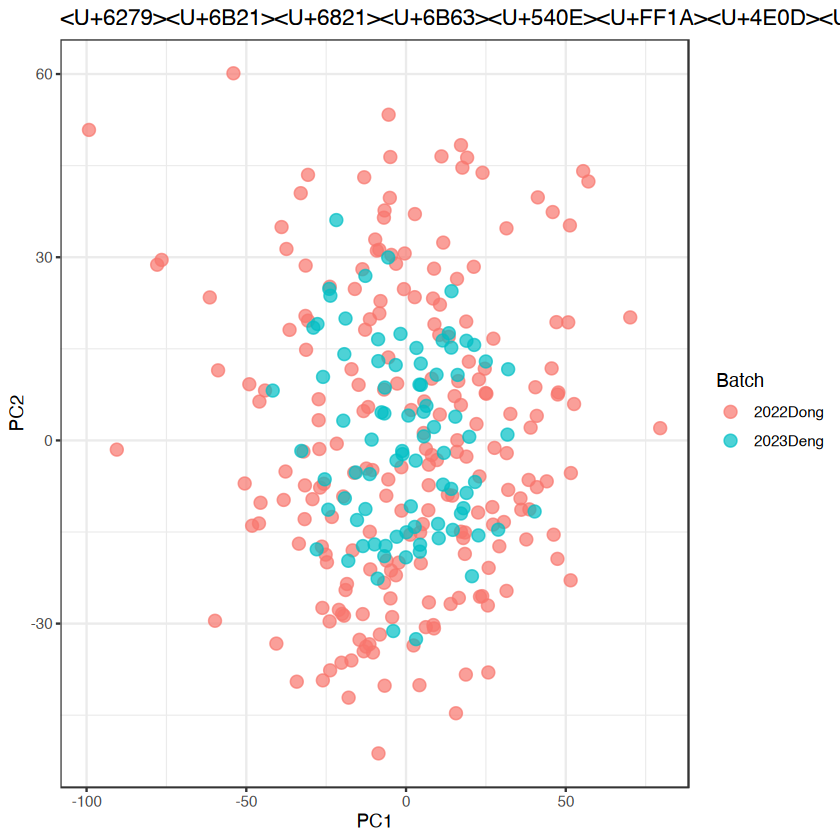

In [25]:
library(sva)
library(ggplot2)

# --- a. 准备批次信息 (这一步非常关键) ---
# 从最开始的长格式数据中提取样本和批次的对应关系
sample_info <- all_prot_long %>%
  select(Sample, Batch) %>%
  distinct()

# 确保sample_info的样本顺序与矩阵的列顺序一致
sample_info <- sample_info[match(colnames(prot_matrix_imputed), sample_info$Sample),]

# --- b. 使用ComBat进行批次校正 ---
batch_vector <- sample_info$Batch
corrected_prot_matrix <- ComBat(
  dat = prot_matrix_imputed, 
  batch = batch_vector
)

# --- c. 批次校正后的PCA验证 ---
pca_after <- prcomp(t(corrected_prot_matrix), scale. = TRUE)
pca_after_df <- as.data.frame(pca_after$x) %>%
  mutate(Batch = sample_info$Batch)

ggplot(pca_after_df, aes(x = PC1, y = PC2, color = Batch)) +
  geom_point(size = 3, alpha = 0.7) +
  labs(title = "PCA Plot After Batch Correction") +
  theme_bw() +
  ggtitle("批次校正后：不同来源的样本混合在一起")

In [26]:
dim(corrected_prot_matrix)
head(corrected_prot_matrix)

[1] 8296  298

,115,117,121,123,125,133,135,137,141,145,...,CCA#80,CCA#82,CCA#85,CCA#89,CCA#90,CCA#91,CCA#93,CCA#94,CCA#95,CCA#98
1-Mar,3.1384564,0.8706699,0.14056241,1.5345069,-0.7081415,0.1506957,-1.0347897,0.10437772,-0.7162476,0.1280358,...,-0.05748693,-0.3139260,-0.2721762,-0.3139260,-0.3139260,-0.31392597,-0.31392597,-0.0246579,-0.3139260,3.16264062
1-Sep,-0.2688108,-0.8639683,-0.02903576,0.0374228,-0.3743786,1.3348989,-0.6958552,0.07138807,-0.6512474,-0.2398088,...,-0.27107007,-0.3151318,0.1111752,0.2151971,-0.1134989,-0.31513180,-0.31513180,-0.1480897,1.9026639,-0.05396275
10-Sep,-0.3539828,1.0171749,0.87220542,-0.1167739,0.7928682,-0.4137493,-0.1039814,1.49972889,-0.4708291,0.8741091,...,-0.60604059,-0.1813856,-0.5568200,0.5497384,-0.3962590,0.06918692,-0.18104612,-0.5445431,0.8103248,-0.16599706
11-Sep,4.9194121,2.0747315,4.00125524,0.7944405,1.8756259,4.5729542,4.8903437,3.06515681,5.9058327,3.8977205,...,-0.42105606,7.9554454,0.2847590,2.2423199,6.3706208,1.93029716,4.05630668,3.1416764,4.9480262,1.83969055
15-Sep,0.6184967,6.3061826,1.71559410,5.0074285,2.9666833,1.2994895,2.2334499,1.53730941,3.4273133,3.2402421,...,17.70000414,6.7151872,5.8817229,5.0988536,-2.8957029,13.91257892,3.75136728,0.4321360,3.9726530,2.62787516
2-Mar,4.7671228,6.8301253,3.24270937,5.5093142,-0.2257457,0.8293558,-1.2262765,2.26071464,-0.9787906,2.5891553,...,6.58457094,-0.7454705,1.4576068,0.3295853,-0.4505965,1.20271948,-0.08359184,5.0910359,0.2063667,7.90645052


In [31]:
save(pro_2022Dong, pro_2023Deng, pro_tcga, corrected_prot_matrix, file = "0-Data-protein.Rdata")
write.csv(corrected_prot_matrix, "0-Data-corrected-protein.csv", row.names = TRUE)

# **Data description**

### *RNA-seq*

In [4]:
load(file = "0-Data-rnaseq.Rdata")

In [5]:
# Create a function to analyze each dataset
analyze_datasets <- function(datasets) {
  # Create results dataframe
  stats <- data.frame(
    Dataset = character(),
    Genes_Count = integer(),
    Samples_Count = integer(),
    Mean_Expression = numeric(),
    Median_Expression = numeric(),
    Non_Zero_Percent = numeric(),
    stringsAsFactors = FALSE
  )
  
  # Get the union of all genes
  all_genes <- unique(unlist(lapply(datasets, rownames)))
  cat("Total genes across all datasets:", length(all_genes), "\n")
  
  # Analyze each dataset
  for(name in names(datasets)) {
    cat("Processing dataset:", name, "\n")
    dataset <- datasets[[name]]
    
    # Check data type
    cat("  Data type:", class(dataset), "\n")
    
    # Convert to matrix to ensure correct calculations
    if(!is.matrix(dataset)) {
      dataset <- as.matrix(dataset)
    }
    
    gene_count <- nrow(dataset)
    sample_count <- ncol(dataset)
    
    # Safely calculate statistics
    mean_expr <- mean(dataset, na.rm = TRUE)
    
    # Convert matrix to vector, then calculate median
    flat_data <- as.vector(dataset)
    median_expr <- median(flat_data, na.rm = TRUE)
    
    # Calculate percentage of non-zero values
    non_zero <- sum(dataset > 0, na.rm = TRUE) / prod(dim(dataset)) * 100
    
    stats <- rbind(stats, data.frame(
      Dataset = name,
      Genes_Count = gene_count,
      Samples_Count = sample_count,
      Mean_Expression = mean_expr,
      Median_Expression = median_expr,
      Non_Zero_Percent = non_zero,
      stringsAsFactors = FALSE
    ))
    
    cat("  Analysis completed, gene count:", gene_count, "sample count:", sample_count, "\n")
  }
  
  # Calculate gene overlap between datasets
  overlap_matrix <- matrix(0, nrow = length(datasets), ncol = length(datasets))
  rownames(overlap_matrix) <- names(datasets)
  colnames(overlap_matrix) <- names(datasets)
  
  for(i in 1:length(datasets)) {
    genes_i <- rownames(datasets[[i]])
    for(j in 1:length(datasets)) {
      genes_j <- rownames(datasets[[j]])
      overlap_matrix[i, j] <- length(intersect(genes_i, genes_j))
    }
  }
  
  return(list(
    stats = stats,
    overlap_matrix = overlap_matrix,
    all_genes = all_genes
  ))
}

# Function to check and prepare datasets
prepare_datasets <- function(dataset_list) {
  for(name in names(dataset_list)) {
    cat("Preparing dataset:", name, "\n")
    
    # Get data
    current_data <- dataset_list[[name]]
    
    # Check data structure
    cat("  Original type:", class(current_data), "\n")
    
    # Ensure it's a matrix or dataframe
    if(is.list(current_data) && !is.data.frame(current_data)) {
      cat("  Warning: Dataset appears to be a list not a matrix, attempting conversion...\n")
      
      # Try to convert to matrix
      tryCatch({
        dataset_list[[name]] <- as.matrix(current_data)
        cat("  Successfully converted to matrix\n")
      }, error = function(e) {
        cat("  Conversion failed:", e$message, "\n")
        cat("  Skipping this dataset\n")
        dataset_list[[name]] <- NULL
      })
    } else if(is.data.frame(current_data)) {
      # If it's a dataframe, convert to matrix
      dataset_list[[name]] <- as.matrix(current_data)
      cat("  Dataframe converted to matrix\n")
    }
    
    # Check again
    if(!is.null(dataset_list[[name]])) {
      cat("  Dimensions:", dim(dataset_list[[name]]), "\n")
      
      # Check for NA values
      na_count <- sum(is.na(dataset_list[[name]]))
      if(na_count > 0) {
        cat("  Warning: Contains", na_count, "NA values\n")
      }
      
      # Check for non-numeric values
      if(!is.numeric(dataset_list[[name]])) {
        cat("  Warning: Contains non-numeric data\n")
      }
    }
  }
  
  # Return prepared datasets
  return(dataset_list)
}

In [6]:
# 创建数据集列表
datasets <- list(
  "2019Ahn" = log2tpm_2019Ahn,
  "2022Dong" = log2tpm_2022Dong,
  "2023Deng" = log2tpm_2023Deng,
  "2023Jeon" = log2tpm_2023Jeon,
  "2023Lee" = log2tpm_2023Lee,
  "2024Fan" = log2tpm_2024Fan,
  "TCGA" = log2tpm_tcga
)

# 检查并准备数据集
prepared_datasets <- prepare_datasets(datasets)

# 分析数据集
dataset_analysis <- analyze_datasets(prepared_datasets)
print(dataset_analysis$stats)

Preparing dataset: 2019Ahn 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 18128 30 
Preparing dataset: 2022Dong 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 15511 255 
Preparing dataset: 2023Deng 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 12666 84 
Preparing dataset: 2023Jeon 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 18345 59 
Preparing dataset: 2023Lee 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 17611 13 
Preparing dataset: 2024Fan 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 20992 114 
Preparing dataset: TCGA 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 20013 31 
Total genes across all datasets: 31825 
Processing dataset: 2019Ahn 
  Data type: matrix array 
  Analysis completed, gene count: 18128 sample count: 30 
Processing dataset: 2022Dong 
  Data type: matrix arr

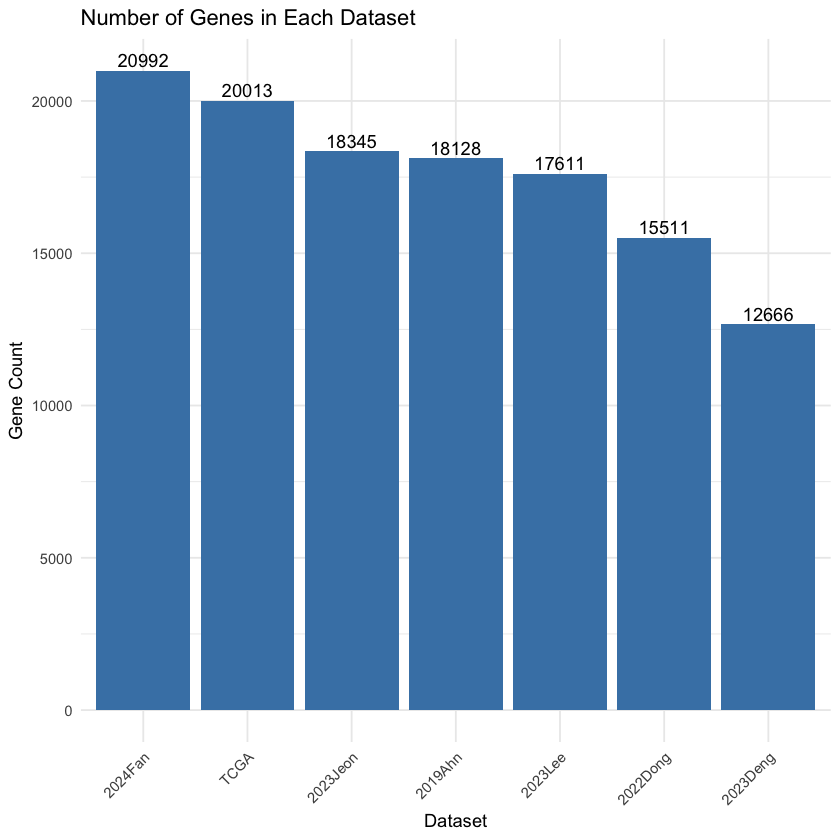

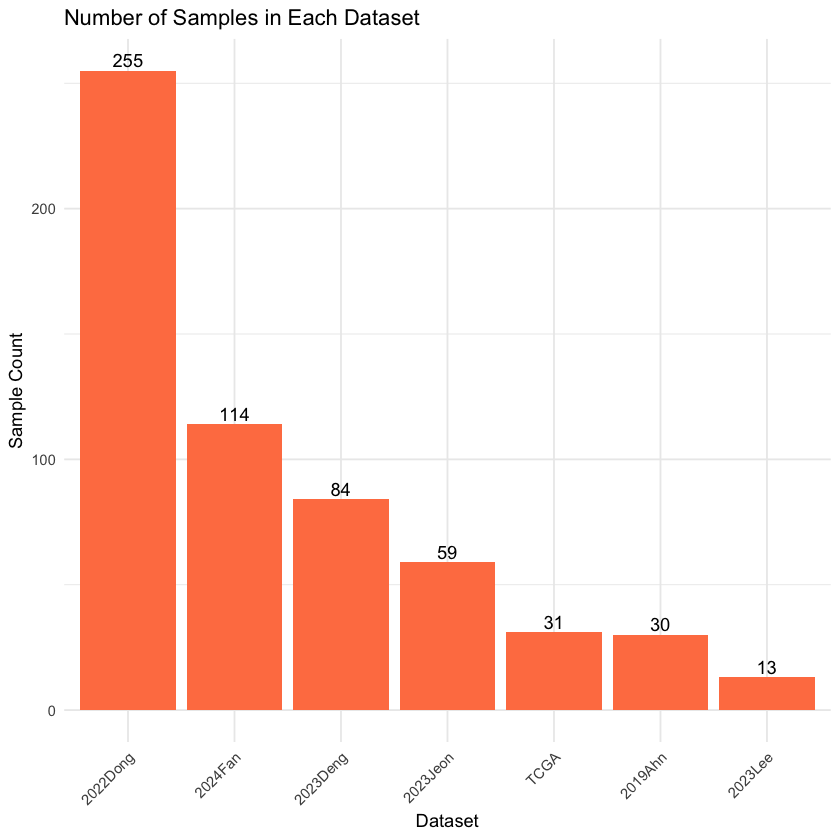

In [7]:
# 基因数量条形图
ggplot(dataset_analysis$stats, aes(x = reorder(Dataset, -Genes_Count), y = Genes_Count)) +
  geom_bar(stat = "identity", fill = "steelblue") +
  geom_text(aes(label = Genes_Count), vjust = -0.3) +
  theme_minimal() +
  labs(title = "Number of Genes in Each Dataset",
       x = "Dataset", y = "Gene Count") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

# 样本数量条形图
ggplot(dataset_analysis$stats, aes(x = reorder(Dataset, -Samples_Count), y = Samples_Count)) +
  geom_bar(stat = "identity", fill = "coral") +
  geom_text(aes(label = Samples_Count), vjust = -0.3) +
  theme_minimal() +
  labs(title = "Number of Samples in Each Dataset",
       x = "Dataset", y = "Sample Count") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

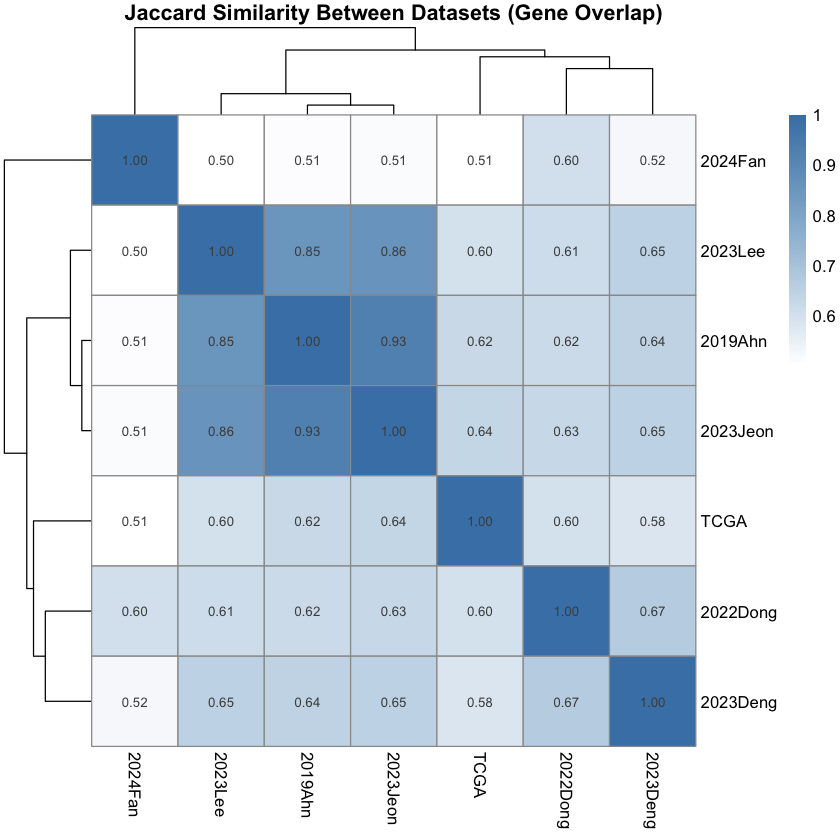

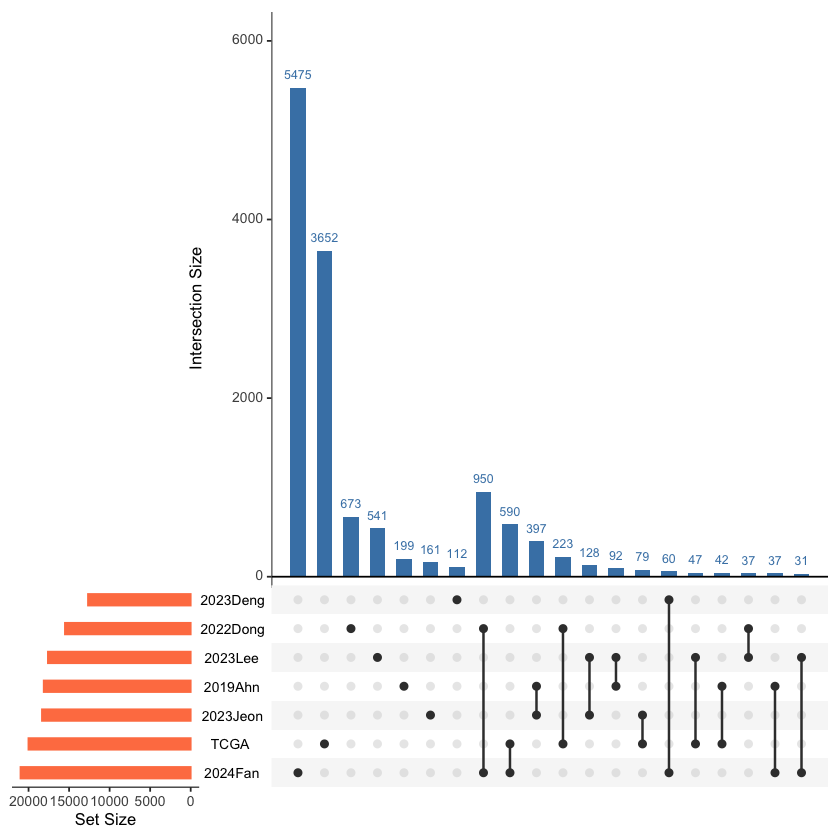

In [8]:
# 可视化基因重叠矩阵
library(pheatmap)

# 计算重叠系数 (Jaccard指数)
jaccard_matrix <- matrix(0, nrow = length(datasets), ncol = length(datasets))
rownames(jaccard_matrix) <- names(datasets)
colnames(jaccard_matrix) <- names(datasets)

for(i in 1:length(datasets)) {
  genes_i <- rownames(datasets[[i]])
  for(j in 1:length(datasets)) {
    genes_j <- rownames(datasets[[j]])
    intersection <- length(intersect(genes_i, genes_j))
    union <- length(union(genes_i, genes_j))
    jaccard_matrix[i, j] <- intersection / union
  }
}

# 绘制热图
pheatmap(jaccard_matrix,
         display_numbers = TRUE,
         number_format = "%.2f",
         main = "Jaccard Similarity Between Datasets (Gene Overlap)",
         color = colorRampPalette(c("white", "steelblue"))(100))

# 绘制UpSet图(基因集重叠)
library(UpSetR)

# 准备UpSet图数据
gene_presence <- data.frame(
  Gene = dataset_analysis$all_genes,
  stringsAsFactors = FALSE
)

for(name in names(datasets)) {
  gene_presence[[name]] <- as.integer(gene_presence$Gene %in% rownames(datasets[[name]]))
}

upset(gene_presence, sets = names(datasets), 
      main.bar.color = "steelblue",
      sets.bar.color = "coral",
      text.scale = 1.2,
      nintersects = 20)

In [9]:
# 分析数据集间相关性
analyze_dataset_correlations <- function(datasets) {
  # 找到所有数据集共有的基因
  common_genes <- Reduce(intersect, lapply(datasets, rownames))
  cat("所有数据集共有基因数:", length(common_genes), "\n")
  
  if(length(common_genes) == 0) {
    stop("数据集没有共同基因，无法计算相关性")
  }
  
  # 提取共同基因的表达数据
  common_expressions <- list()
  for(name in names(datasets)) {
    common_expressions[[name]] <- datasets[[name]][common_genes, ]
  }
  
  # 计算每个数据集的平均表达值(按基因)
  mean_expressions <- data.frame(Gene = common_genes)
  for(name in names(common_expressions)) {
    mean_expressions[[name]] <- rowMeans(common_expressions[[name]], na.rm = TRUE)
  }
  
  # 计算数据集间的相关性
  cor_matrix <- cor(mean_expressions[, -1], method = "spearman")
  
  return(list(
    common_genes = common_genes,
    mean_expressions = mean_expressions,
    correlation_matrix = cor_matrix
  ))
}

# 分析数据集相关性
correlation_analysis <- analyze_dataset_correlations(datasets)
print(correlation_analysis$correlation_matrix)

<U+6240><U+6709><U+6570><U+636E><U+96C6><U+5171><U+6709><U+57FA><U+56E0><U+6570>: 10531 
           2019Ahn  2022Dong  2023Deng  2023Jeon   2023Lee   2024Fan      TCGA
2019Ahn  1.0000000 0.5906758 0.5298407 0.9774119 0.8909242 0.6150332 0.8167574
2022Dong 0.5906758 1.0000000 0.5881196 0.6486312 0.6084739 0.6977431 0.6067387
2023Deng 0.5298407 0.5881196 1.0000000 0.5845950 0.5610024 0.8558517 0.6278176
2023Jeon 0.9774119 0.6486312 0.5845950 1.0000000 0.8794010 0.6529030 0.8416611
2023Lee  0.8909242 0.6084739 0.5610024 0.8794010 1.0000000 0.6429639 0.7539196
2024Fan  0.6150332 0.6977431 0.8558517 0.6529030 0.6429639 1.0000000 0.6261400
TCGA     0.8167574 0.6067387 0.6278176 0.8416611 0.7539196 0.6261400 1.0000000


Registered S3 method overwritten by 'GGally':
  method from   
  +.gg   ggplot2



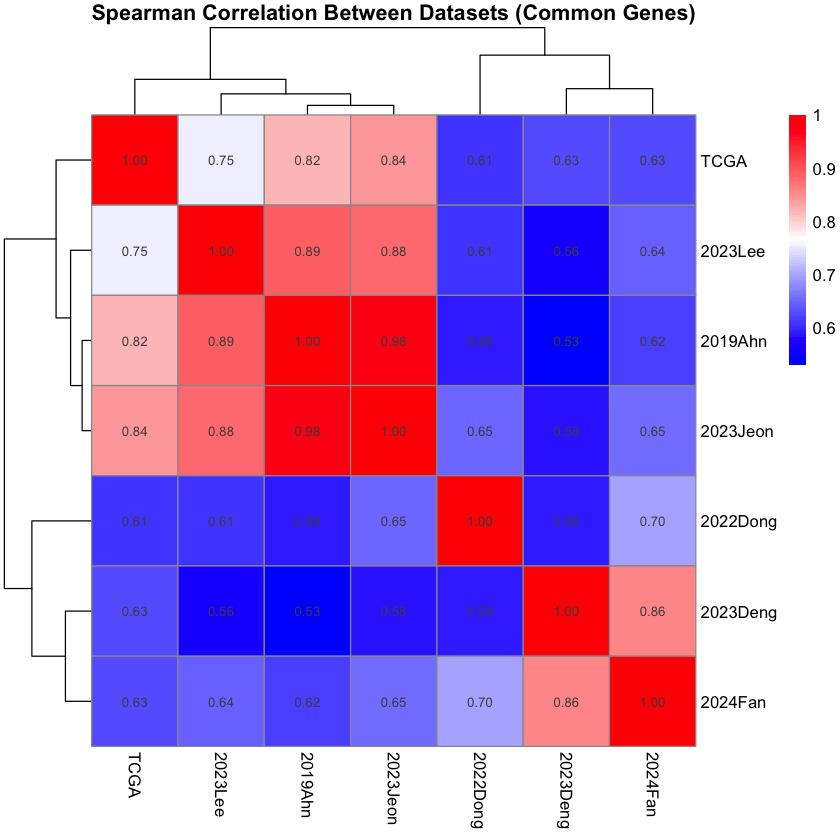

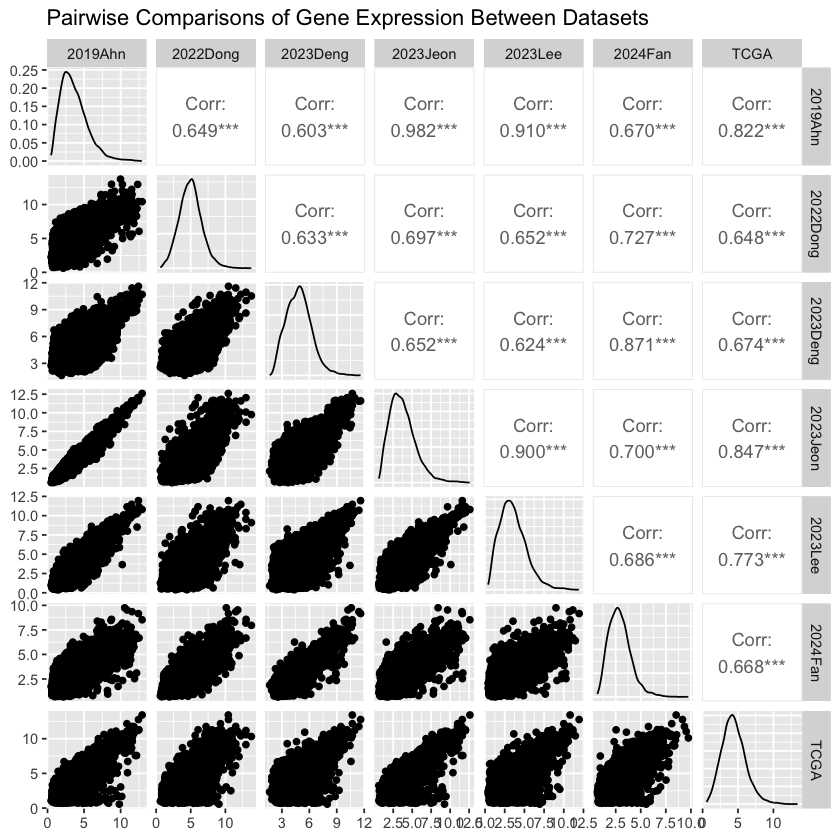

In [12]:
# 绘制相关性热图
pheatmap(correlation_analysis$correlation_matrix,
         display_numbers = TRUE,
         number_format = "%.2f",
         main = "Spearman Correlation Between Datasets (Common Genes)",
         color = colorRampPalette(c("blue", "white", "red"))(100))

# 散点图矩阵(成对比较)
library(GGally)

ggpairs(correlation_analysis$mean_expressions[, -1], 
        title = "Pairwise Comparisons of Gene Expression Between Datasets")

Performing PCA using 10531 complete genes


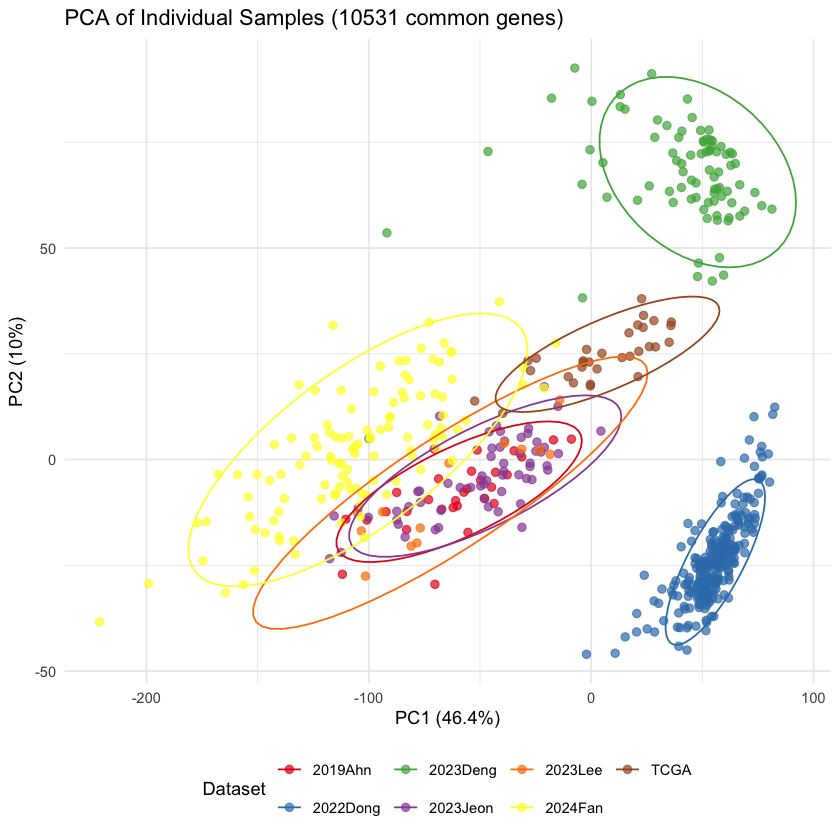

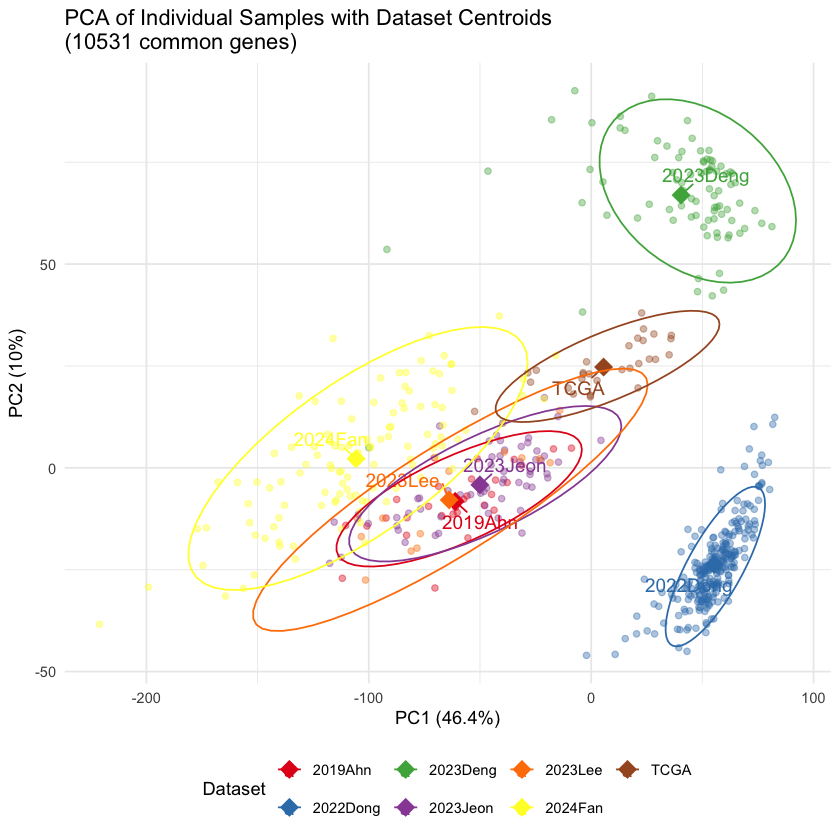

In [13]:
# Function to create a combined matrix of all samples
create_combined_sample_matrix <- function(datasets) {
  # Find common genes across all datasets
  common_genes <- Reduce(intersect, lapply(datasets, rownames))
  
  if(length(common_genes) < 10) {
    # Try using genes present in most datasets
    gene_counts <- table(unlist(lapply(datasets, rownames)))
    threshold <- ceiling(length(datasets) * 0.7)  # 70% of datasets
    frequent_genes <- names(gene_counts[gene_counts >= threshold])
    
    if(length(frequent_genes) > 10) {
      common_genes <- frequent_genes
      cat("Using", length(common_genes), "genes present in at least", threshold, "datasets\n")
    } else {
      stop("Not enough common genes for analysis")
    }
  }
  
  # Initialize the combined matrix list
  combined_matrices <- list()
  dataset_labels <- c()
  
  # Extract and combine data from each dataset
  for(name in names(datasets)) {
    dataset <- datasets[[name]]
    
    # Find genes in this dataset that are in common_genes
    available_genes <- intersect(common_genes, rownames(dataset))
    
    if(length(available_genes) > 0) {
      # Extract data for these genes
      dataset_matrix <- dataset[available_genes, ]
      
      # If some genes from common_genes are missing, add them with NA values
      if(length(available_genes) < length(common_genes)) {
        missing_genes <- setdiff(common_genes, available_genes)
        missing_matrix <- matrix(NA, nrow = length(missing_genes), ncol = ncol(dataset))
        rownames(missing_matrix) <- missing_genes
        colnames(missing_matrix) <- colnames(dataset)
        
        # Combine available and missing genes
        full_matrix <- rbind(dataset_matrix, missing_matrix)
        
        # Sort to match common_genes order
        full_matrix <- full_matrix[common_genes, ]
      } else {
        # All common genes are present, just ensure order
        full_matrix <- dataset_matrix[common_genes, ]
      }
      
      # Add to list
      combined_matrices[[name]] <- full_matrix
      
      # Create dataset labels for each sample
      dataset_labels <- c(dataset_labels, rep(name, ncol(full_matrix)))
    }
  }
  
  # Combine all matrices side by side
  all_samples <- do.call(cbind, combined_matrices)
  
  # Create metadata for plotting
  sample_info <- data.frame(
    SampleID = colnames(all_samples),
    Dataset = dataset_labels
  )
  
  return(list(
    expression_matrix = all_samples,
    sample_info = sample_info,
    common_genes = common_genes
  ))
}

# Perform PCA on all samples
perform_sample_pca <- function(combined_data) {
  # Get expression matrix and transpose it for PCA
  expr_matrix <- combined_data$expression_matrix
  sample_info <- combined_data$sample_info
  
  # Remove rows with any NA values
  complete_rows <- rowSums(is.na(expr_matrix)) == 0
  expr_matrix_complete <- expr_matrix[complete_rows, ]
  
  # Check if we have enough data
  if(nrow(expr_matrix_complete) < 10) {
    stop("Too few genes with complete data across all datasets")
  }
  
  cat("Performing PCA using", nrow(expr_matrix_complete), "complete genes\n")
  
  # Run PCA
  pca_result <- prcomp(t(expr_matrix_complete), scale. = TRUE)
  
  # Create dataframe for plotting
  pca_data <- as.data.frame(pca_result$x)
  pca_data$SampleID <- rownames(pca_data)
  
  # Add dataset information
  pca_data <- merge(pca_data, sample_info, by = "SampleID")
  
  # Calculate variance explained
  var_explained <- (pca_result$sdev^2) / sum(pca_result$sdev^2) * 100
  
  return(list(
    pca_result = pca_result,
    pca_data = pca_data,
    var_explained = var_explained,
    genes_used = nrow(expr_matrix_complete)
  ))
}

# Load required libraries
library(ggplot2)
library(ggrepel)

# Combine all datasets and perform PCA
combined_data <- create_combined_sample_matrix(datasets)
sample_pca <- perform_sample_pca(combined_data)

# Create PCA plot with individual samples
ggplot(sample_pca$pca_data, aes(x = PC1, y = PC2, color = Dataset)) +
  geom_point(alpha = 0.7, size = 2) +
  theme_minimal() +
  labs(title = paste("PCA of Individual Samples (", sample_pca$genes_used, " common genes)", sep=""),
       x = paste0("PC1 (", round(sample_pca$var_explained[1], 1), "%)"),
       y = paste0("PC2 (", round(sample_pca$var_explained[2], 1), "%)")) +
  theme(legend.position = "bottom") +
  # Add ellipses to show dataset clusters
  stat_ellipse(aes(group = Dataset), level = 0.95) +
  scale_color_brewer(palette = "Set1")

# If there are too many samples, create a cleaner plot with centroids
if(nrow(sample_pca$pca_data) > 100) {
  # Calculate centroids of each dataset
  centroids <- aggregate(cbind(PC1, PC2) ~ Dataset, data = sample_pca$pca_data, FUN = mean)
  
  # Add the centroids to the plot
  ggplot(sample_pca$pca_data, aes(x = PC1, y = PC2, color = Dataset)) +
    geom_point(alpha = 0.4, size = 1.5) +
    geom_point(data = centroids, size = 5, shape = 18) +
    geom_text_repel(data = centroids, aes(label = Dataset), size = 4, box.padding = 0.5) +
    theme_minimal() +
    labs(title = paste("PCA of Individual Samples with Dataset Centroids\n(", sample_pca$genes_used, " common genes)", sep=""),
         x = paste0("PC1 (", round(sample_pca$var_explained[1], 1), "%)"),
         y = paste0("PC2 (", round(sample_pca$var_explained[2], 1), "%)")) +
    theme(legend.position = "bottom") +
    stat_ellipse(aes(group = Dataset), level = 0.95) +
    scale_color_brewer(palette = "Set1")
}

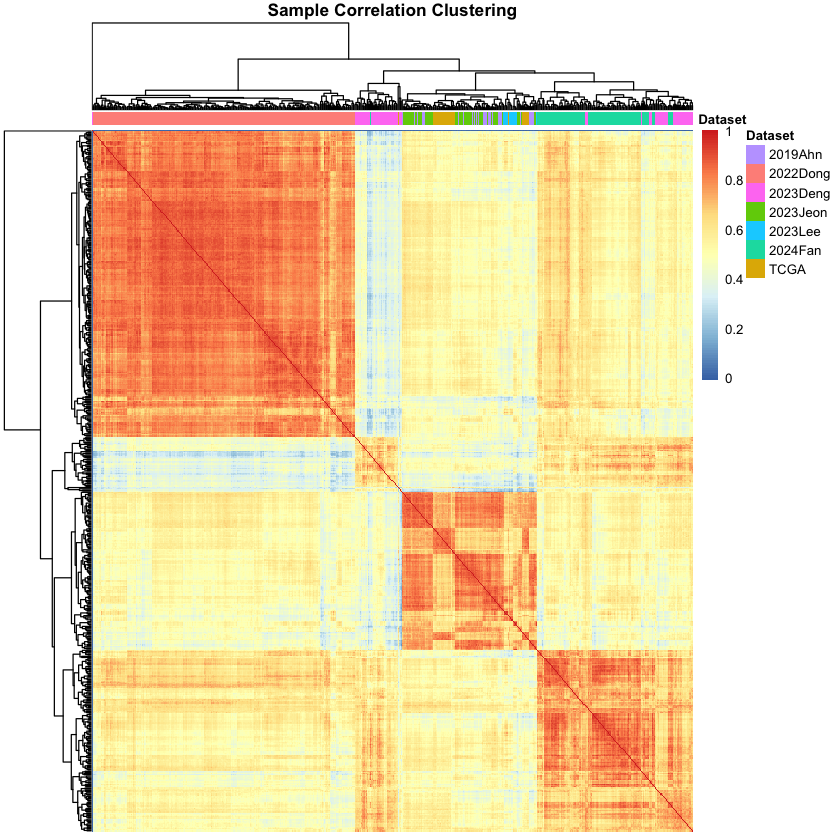

In [14]:
library(pheatmap)

# Compute correlation matrix between samples
expr_matrix_complete <- combined_data$expression_matrix[rowSums(is.na(combined_data$expression_matrix)) == 0,]
sample_cor <- cor(expr_matrix_complete, method = "spearman")

# Create annotation dataframe
sample_annot <- data.frame(Dataset = combined_data$sample_info$Dataset)
rownames(sample_annot) <- combined_data$sample_info$SampleID

# Plot heatmap with hierarchical clustering
pheatmap(sample_cor,
         annotation_col = sample_annot,
         show_colnames = FALSE,
         show_rownames = FALSE,
         main = "Sample Correlation Clustering",
         fontsize = 8)

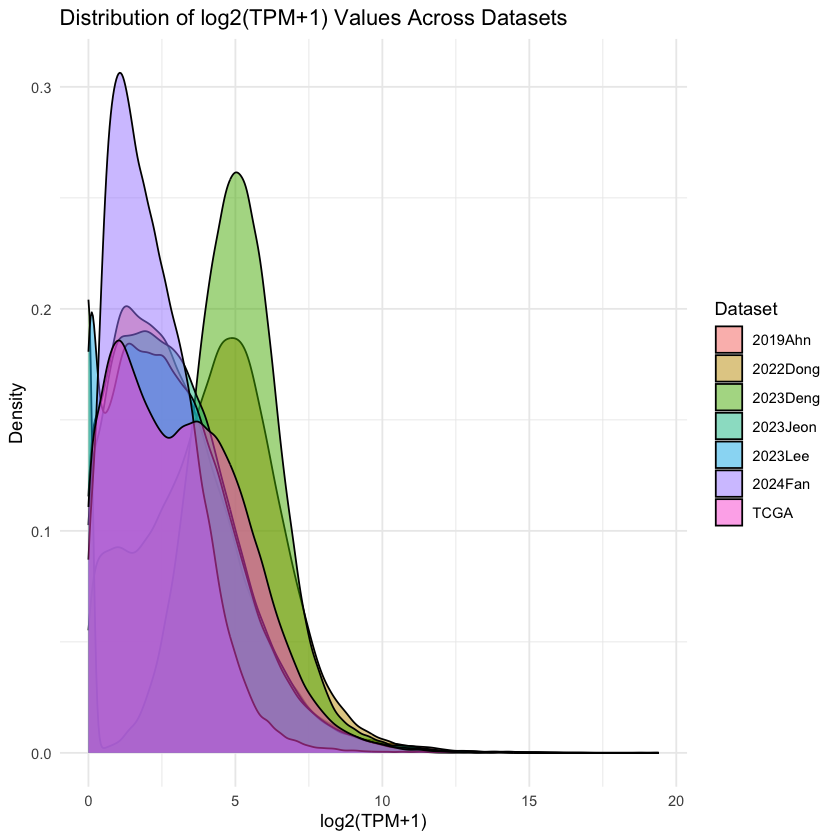

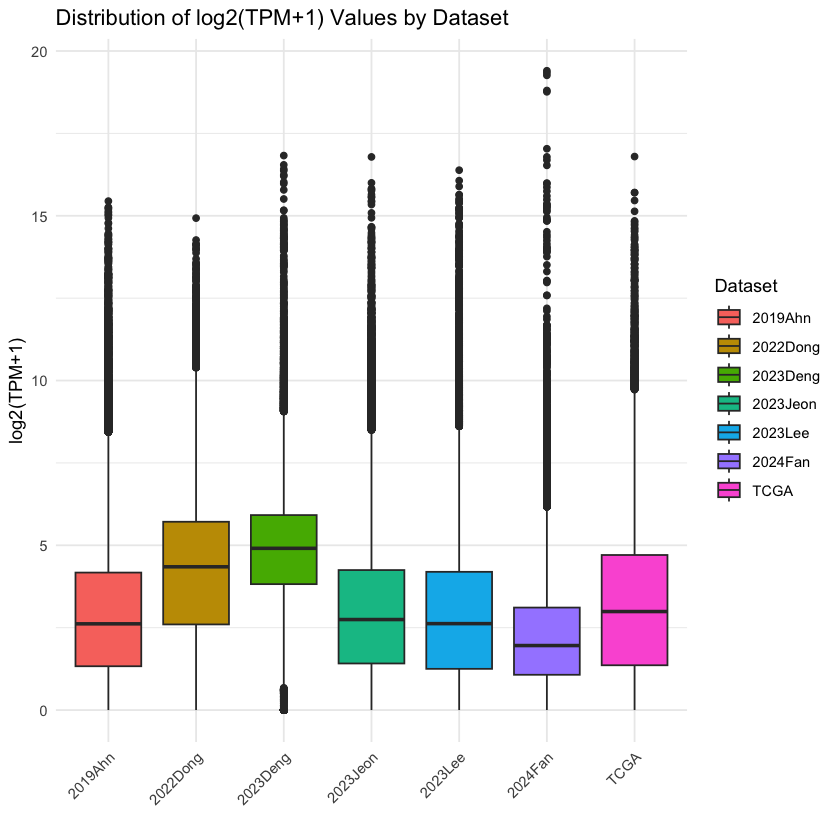

In [15]:
# 分析表达分布
analyze_expression_distributions <- function(datasets) {
  # 为每个数据集提取表达值和密度
  distribution_data <- data.frame()
  
  for(name in names(datasets)) {
    # 提取表达值
    expr_values <- as.vector(as.matrix(datasets[[name]]))
    
    # 随机抽样以减少计算量(如果数据太大)
    if(length(expr_values) > 100000) {
      set.seed(123)  # 设置随机种子以确保可重复性
      expr_values <- sample(expr_values, 100000)
    }
    
    # 添加到数据框
    temp_df <- data.frame(
      Dataset = name,
      Expression = expr_values
    )
    
    distribution_data <- rbind(distribution_data, temp_df)
  }
  
  return(distribution_data)
}

# 分析表达分布
distribution_data <- analyze_expression_distributions(datasets)

# 绘制表达分布图
# 密度图
ggplot(distribution_data, aes(x = Expression, fill = Dataset)) +
  geom_density(alpha = 0.5) +
  theme_minimal() +
  labs(title = "Distribution of log2(TPM+1) Values Across Datasets",
       x = "log2(TPM+1)", y = "Density")

# 箱线图
ggplot(distribution_data, aes(x = Dataset, y = Expression, fill = Dataset)) +
  geom_boxplot() +
  theme_minimal() +
  labs(title = "Distribution of log2(TPM+1) Values by Dataset",
       x = "", y = "log2(TPM+1)") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

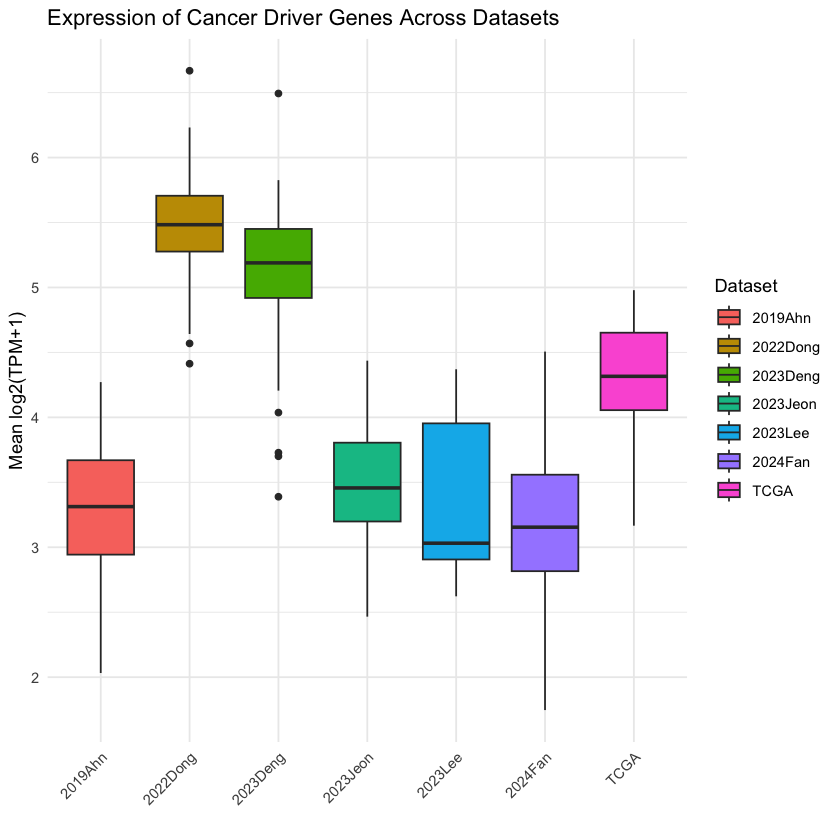

In [16]:
# 分析特定基因集在不同数据集中的表达
analyze_gene_set <- function(datasets, gene_set, gene_set_name = "Gene Set") {
  # 准备结果数据框
  result_data <- data.frame()
  
  for(name in names(datasets)) {
    # 找出数据集中存在的目标基因
    present_genes <- intersect(gene_set, rownames(datasets[[name]]))
    
    if(length(present_genes) > 0) {
      # 提取这些基因的表达值
      gene_expr <- datasets[[name]][present_genes, ]
      
      # 计算每个样本的这些基因的平均表达
      mean_expr <- colMeans(gene_expr, na.rm = TRUE)
      
      # 添加到结果数据框
      temp_df <- data.frame(
        Dataset = name,
        Sample = colnames(datasets[[name]]),
        Mean_Expression = mean_expr,
        Genes_Found = length(present_genes),
        Total_Genes = length(gene_set)
      )
      
      result_data <- rbind(result_data, temp_df)
    }
  }
  
  # 添加基因集名称
  result_data$Gene_Set <- gene_set_name
  
  return(result_data)
}

# 示例：分析一组感兴趣的基因
# 可以是您感兴趣的通路基因，如细胞周期、炎症相关等
interest_genes <- c("TP53", "EGFR", "KRAS", "PIK3CA", "PTEN", "RB1", "CDKN2A", "MYC")
gene_set_analysis <- analyze_gene_set(datasets, interest_genes, "Cancer Driver Genes")

# 绘制基因集表达箱线图
ggplot(gene_set_analysis, aes(x = Dataset, y = Mean_Expression, fill = Dataset)) +
  geom_boxplot() +
  theme_minimal() +
  labs(title = paste("Expression of", gene_set_analysis$Gene_Set[1], "Across Datasets"),
       x = "", y = "Mean log2(TPM+1)") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [18]:
sample_info <- readxl::read_excel("./sample_information.xlsx")
dim(sample_info)
head(sample_info)

[1] 1092   34

SampleID,Study,Platform,Sex,Age,Country,Race,iCCA classification,Subclass,Subclass-add,...,"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling,RNA
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
GSM653074,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653075,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653076,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653077,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653078,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA
GSM653079,2012Andersen,Microarray (Illumina),NA,NA,White,White,w/o,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NO,NO,NA


In [19]:
all(colnames(combined_data) %in% sample_info$SampleID)  # 应为 TRUE

[1] TRUE

### *Microarray*

In [43]:
load(file = "./0-Data/0-Data-rnaseq-microarray1.Rdata")
load(file = "./0-Data/0-Data-rnaseq-microarray2.Rdata")
ls()

[1] "dat_2012Andersen"      "dat_2013Sia"           "dat_2017Jusakual1"    
 [4] "dat_2017Jusakual2"     "expression_cols"       "folder_path"          
 [7] "index"                 "keep"                  "log2_dat"             
[10] "log2dat_2012Andersen"  "log2dat_2013Sia"       "log2dat_2017Jusakual1"
[13] "log2dat_2017Jusakual2" "log2dat_2020Job"       "log2dat_TIGER"        
[16] "matrix"                "matrix_nodup"          "matrix_ordered"       
[19] "rna_seq_files"         "sample_info"           "samples"

In [44]:
# Create a function to analyze each dataset
analyze_datasets <- function(datasets) {
  # Create results dataframe
  stats <- data.frame(
    Dataset = character(),
    Genes_Count = integer(),
    Samples_Count = integer(),
    Mean_Expression = numeric(),
    Median_Expression = numeric(),
    Non_Zero_Percent = numeric(),
    stringsAsFactors = FALSE
  )
  
  # Get the union of all genes
  all_genes <- unique(unlist(lapply(datasets, rownames)))
  cat("Total genes across all datasets:", length(all_genes), "\n")
  
  # Analyze each dataset
  for(name in names(datasets)) {
    cat("Processing dataset:", name, "\n")
    dataset <- datasets[[name]]
    
    # Check data type
    cat("  Data type:", class(dataset), "\n")
    
    # Convert to matrix to ensure correct calculations
    if(!is.matrix(dataset)) {
      dataset <- as.matrix(dataset)
    }
    
    gene_count <- nrow(dataset)
    sample_count <- ncol(dataset)
    
    # Safely calculate statistics
    mean_expr <- mean(dataset, na.rm = TRUE)
    
    # Convert matrix to vector, then calculate median
    flat_data <- as.vector(dataset)
    median_expr <- median(flat_data, na.rm = TRUE)
    
    # Calculate percentage of non-zero values
    non_zero <- sum(dataset > 0, na.rm = TRUE) / prod(dim(dataset)) * 100
    
    stats <- rbind(stats, data.frame(
      Dataset = name,
      Genes_Count = gene_count,
      Samples_Count = sample_count,
      Mean_Expression = mean_expr,
      Median_Expression = median_expr,
      Non_Zero_Percent = non_zero,
      stringsAsFactors = FALSE
    ))
    
    cat("  Analysis completed, gene count:", gene_count, "sample count:", sample_count, "\n")
  }
  
  # Calculate gene overlap between datasets
  overlap_matrix <- matrix(0, nrow = length(datasets), ncol = length(datasets))
  rownames(overlap_matrix) <- names(datasets)
  colnames(overlap_matrix) <- names(datasets)
  
  for(i in 1:length(datasets)) {
    genes_i <- rownames(datasets[[i]])
    for(j in 1:length(datasets)) {
      genes_j <- rownames(datasets[[j]])
      overlap_matrix[i, j] <- length(intersect(genes_i, genes_j))
    }
  }
  
  return(list(
    stats = stats,
    overlap_matrix = overlap_matrix,
    all_genes = all_genes
  ))
}

# Function to check and prepare datasets
prepare_datasets <- function(dataset_list) {
  for(name in names(dataset_list)) {
    cat("Preparing dataset:", name, "\n")
    
    # Get data
    current_data <- dataset_list[[name]]
    
    # Check data structure
    cat("  Original type:", class(current_data), "\n")
    
    # Ensure it's a matrix or dataframe
    if(is.list(current_data) && !is.data.frame(current_data)) {
      cat("  Warning: Dataset appears to be a list not a matrix, attempting conversion...\n")
      
      # Try to convert to matrix
      tryCatch({
        dataset_list[[name]] <- as.matrix(current_data)
        cat("  Successfully converted to matrix\n")
      }, error = function(e) {
        cat("  Conversion failed:", e$message, "\n")
        cat("  Skipping this dataset\n")
        dataset_list[[name]] <- NULL
      })
    } else if(is.data.frame(current_data)) {
      # If it's a dataframe, convert to matrix
      dataset_list[[name]] <- as.matrix(current_data)
      cat("  Dataframe converted to matrix\n")
    }
    
    # Check again
    if(!is.null(dataset_list[[name]])) {
      cat("  Dimensions:", dim(dataset_list[[name]]), "\n")
      
      # Check for NA values
      na_count <- sum(is.na(dataset_list[[name]]))
      if(na_count > 0) {
        cat("  Warning: Contains", na_count, "NA values\n")
      }
      
      # Check for non-numeric values
      if(!is.numeric(dataset_list[[name]])) {
        cat("  Warning: Contains non-numeric data\n")
      }
    }
  }
  
  # Return prepared datasets
  return(dataset_list)
}

In [45]:
# 创建数据集列表
datasets <- list(
  "2012Andersen" = log2dat_2012Andersen,
  "2013Sia" = log2dat_2013Sia,
  "2017Jusakual1" = log2dat_2017Jusakual1,
  "2017Jusakual2" = log2dat_2017Jusakual2,
  "2020Job" = log2dat_2020Job,
  "TIGER" = log2dat_TIGER
)

# 检查并准备数据集
prepared_datasets <- prepare_datasets(datasets)

# 分析数据集
dataset_analysis <- analyze_datasets(prepared_datasets)
print(dataset_analysis$stats)

Preparing dataset: 2012Andersen 
  Original type: matrix array 
  Dimensions: 18190 104 
Preparing dataset: 2013Sia 
  Original type: matrix array 
  Dimensions: 18402 149 
Preparing dataset: 2017Jusakual1 
  Original type: matrix array 
  Dimensions: 34660 34 
Preparing dataset: 2017Jusakual2 
  Original type: matrix array 
  Dimensions: 34648 49 
Preparing dataset: 2020Job 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 21641 78 
Preparing dataset: TIGER 
  Original type: data.frame 
  Dataframe converted to matrix
  Dimensions: 28526 92 
Total genes across all datasets: 48039 
Processing dataset: 2012Andersen 
  Data type: matrix array 
  Analysis completed, gene count: 18190 sample count: 104 
Processing dataset: 2013Sia 
  Data type: matrix array 
  Analysis completed, gene count: 18402 sample count: 149 
Processing dataset: 2017Jusakual1 
  Data type: matrix array 
  Analysis completed, gene count: 34660 sample count: 34 
Processing dataset: 2017Jusaku

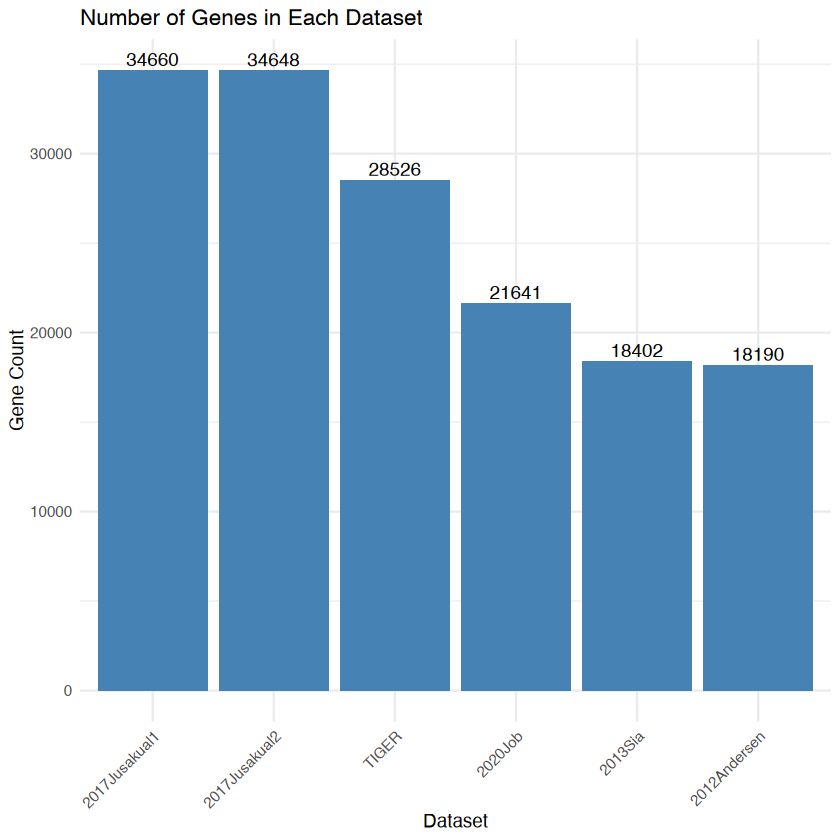

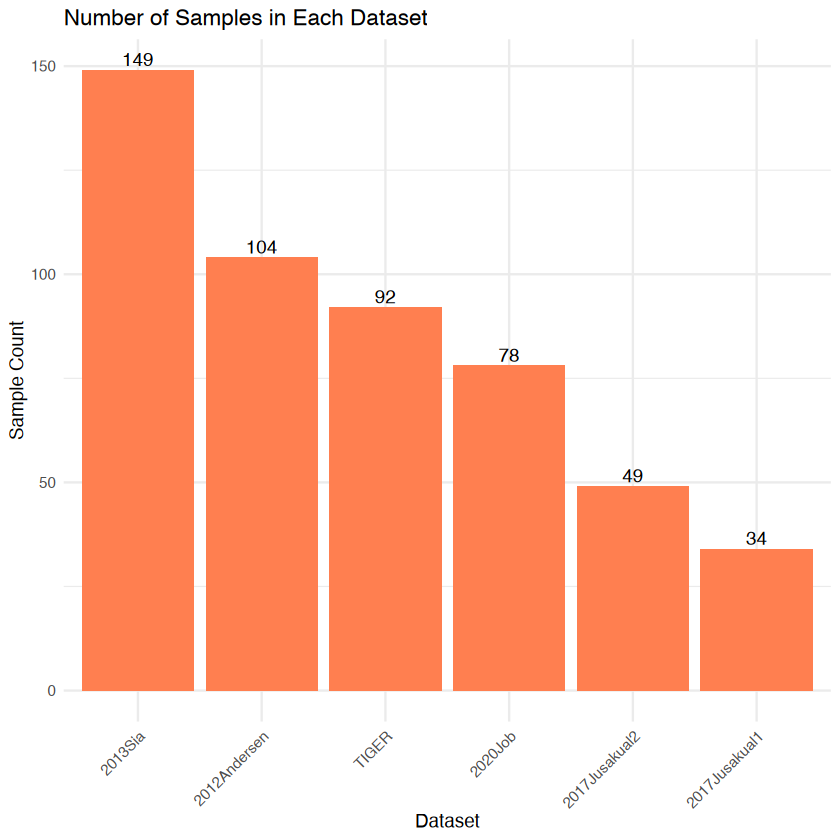

In [46]:
# 基因数量条形图
ggplot(dataset_analysis$stats, aes(x = reorder(Dataset, -Genes_Count), y = Genes_Count)) +
  geom_bar(stat = "identity", fill = "steelblue") +
  geom_text(aes(label = Genes_Count), vjust = -0.3) +
  theme_minimal() +
  labs(title = "Number of Genes in Each Dataset",
       x = "Dataset", y = "Gene Count") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

# 样本数量条形图
ggplot(dataset_analysis$stats, aes(x = reorder(Dataset, -Samples_Count), y = Samples_Count)) +
  geom_bar(stat = "identity", fill = "coral") +
  geom_text(aes(label = Samples_Count), vjust = -0.3) +
  theme_minimal() +
  labs(title = "Number of Samples in Each Dataset",
       x = "Dataset", y = "Sample Count") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

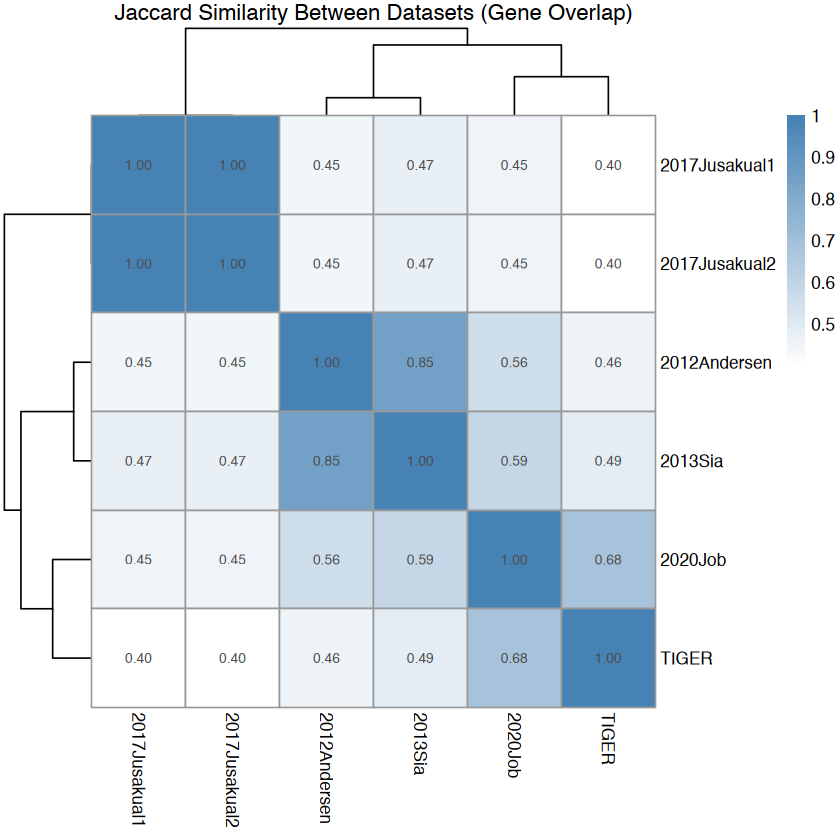

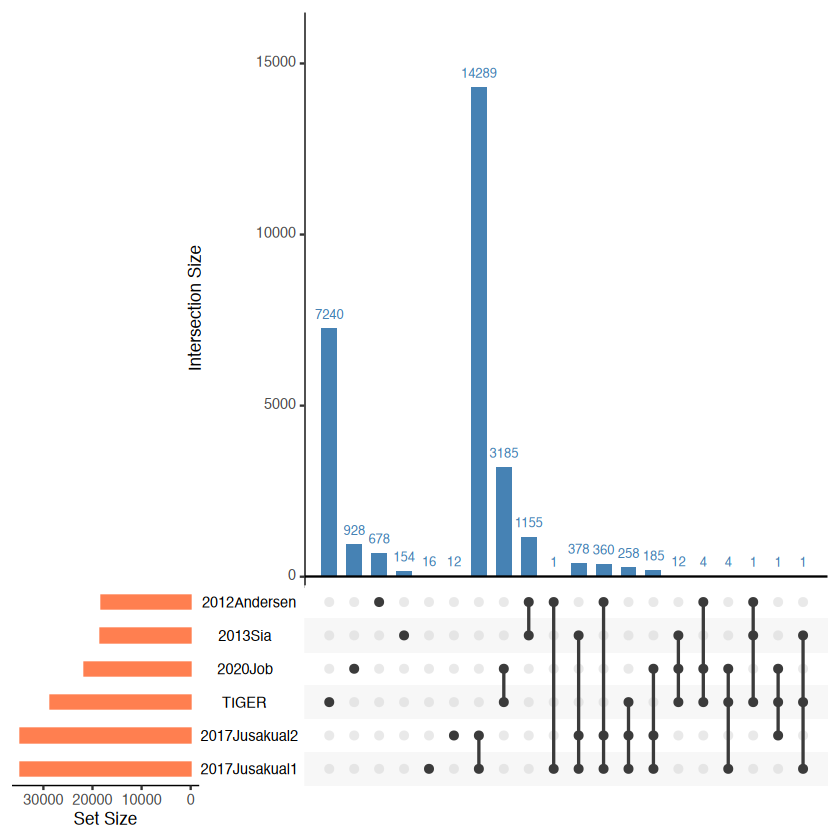

In [47]:
# 可视化基因重叠矩阵
library(pheatmap)

# 计算重叠系数 (Jaccard指数)
jaccard_matrix <- matrix(0, nrow = length(datasets), ncol = length(datasets))
rownames(jaccard_matrix) <- names(datasets)
colnames(jaccard_matrix) <- names(datasets)

for(i in 1:length(datasets)) {
  genes_i <- rownames(datasets[[i]])
  for(j in 1:length(datasets)) {
    genes_j <- rownames(datasets[[j]])
    intersection <- length(intersect(genes_i, genes_j))
    union <- length(union(genes_i, genes_j))
    jaccard_matrix[i, j] <- intersection / union
  }
}

# 绘制热图
pheatmap(jaccard_matrix,
         display_numbers = TRUE,
         number_format = "%.2f",
         main = "Jaccard Similarity Between Datasets (Gene Overlap)",
         color = colorRampPalette(c("white", "steelblue"))(100))

# 绘制UpSet图(基因集重叠)
library(UpSetR)

# 准备UpSet图数据
gene_presence <- data.frame(
  Gene = dataset_analysis$all_genes,
  stringsAsFactors = FALSE
)

for(name in names(datasets)) {
  gene_presence[[name]] <- as.integer(gene_presence$Gene %in% rownames(datasets[[name]]))
}

upset(gene_presence, sets = names(datasets), 
      main.bar.color = "steelblue",
      sets.bar.color = "coral",
      text.scale = 1.2,
      nintersects = 20)

In [48]:
# 分析数据集间相关性
analyze_dataset_correlations <- function(datasets) {
  # 找到所有数据集共有的基因
  common_genes <- Reduce(intersect, lapply(datasets, rownames))
  cat("所有数据集共有基因数:", length(common_genes), "\n")
  
  if(length(common_genes) == 0) {
    stop("数据集没有共同基因，无法计算相关性")
  }
  
  # 提取共同基因的表达数据
  common_expressions <- list()
  for(name in names(datasets)) {
    common_expressions[[name]] <- datasets[[name]][common_genes, ]
  }
  
  # 计算每个数据集的平均表达值(按基因)
  mean_expressions <- data.frame(Gene = common_genes)
  for(name in names(common_expressions)) {
    mean_expressions[[name]] <- rowMeans(common_expressions[[name]], na.rm = TRUE)
  }
  
  # 计算数据集间的相关性
  cor_matrix <- cor(mean_expressions[, -1], method = "spearman")
  
  return(list(
    common_genes = common_genes,
    mean_expressions = mean_expressions,
    correlation_matrix = cor_matrix
  ))
}

# 分析数据集相关性
correlation_analysis <- analyze_dataset_correlations(datasets)
print(correlation_analysis$correlation_matrix)

所有数据集共有基因数: 13818 
              2012Andersen   2013Sia 2017Jusakual1 2017Jusakual2   2020Job
2012Andersen     1.0000000 0.5670000     0.8942894     0.8938353 0.6899123
2013Sia          0.5670000 1.0000000     0.5988467     0.6058773 0.4777052
2017Jusakual1    0.8942894 0.5988467     1.0000000     0.9913791 0.7097021
2017Jusakual2    0.8938353 0.6058773     0.9913791     1.0000000 0.7042066
2020Job          0.6899123 0.4777052     0.7097021     0.7042066 1.0000000
TIGER            0.6654529 0.4796165     0.6795214     0.6739463 0.9112258
                  TIGER
2012Andersen  0.6654529
2013Sia       0.4796165
2017Jusakual1 0.6795214
2017Jusakual2 0.6739463
2020Job       0.9112258
TIGER         1.0000000


Registered S3 method overwritten by 'GGally':
  method from   
  +.gg   ggplot2



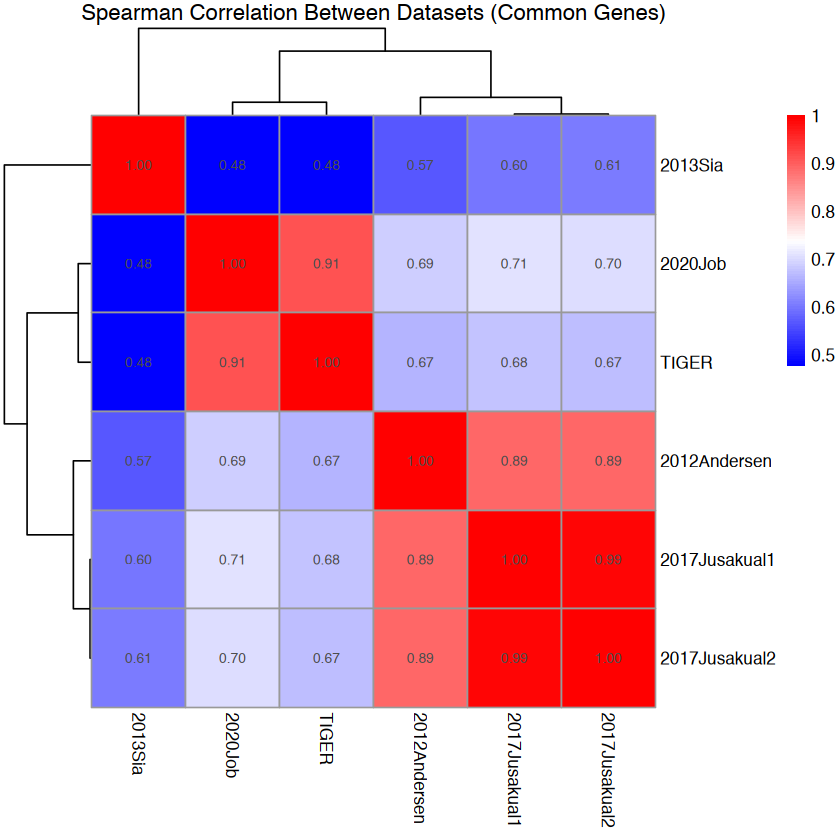

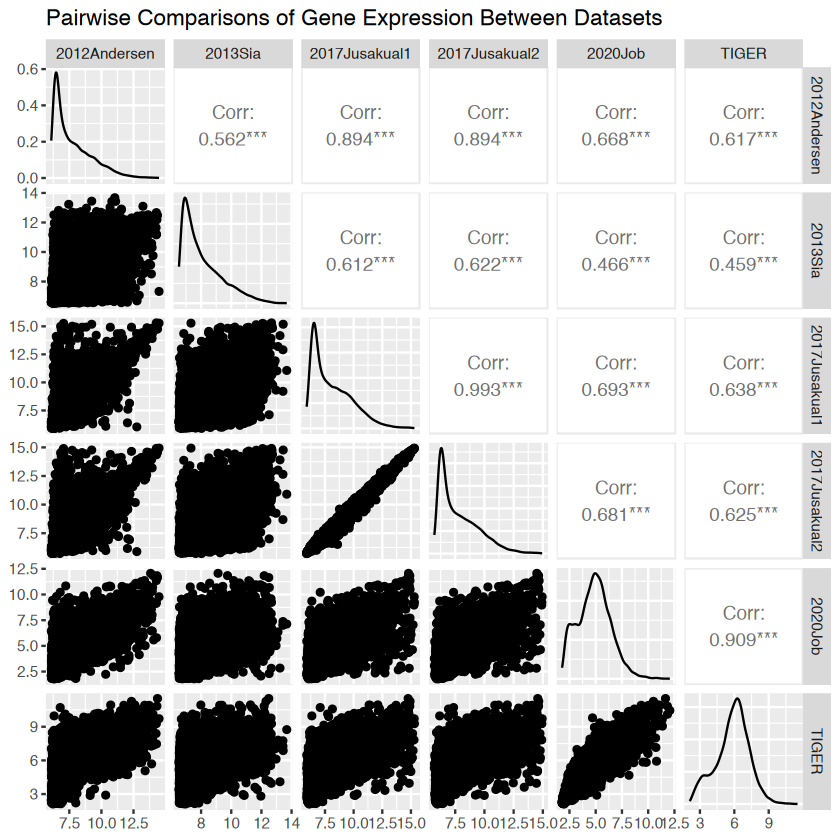

In [49]:
# 绘制相关性热图
pheatmap(correlation_analysis$correlation_matrix,
         display_numbers = TRUE,
         number_format = "%.2f",
         main = "Spearman Correlation Between Datasets (Common Genes)",
         color = colorRampPalette(c("blue", "white", "red"))(100))

# 散点图矩阵(成对比较)
library(GGally)

ggpairs(correlation_analysis$mean_expressions[, -1], 
        title = "Pairwise Comparisons of Gene Expression Between Datasets")

Performing PCA using 13818 complete genes


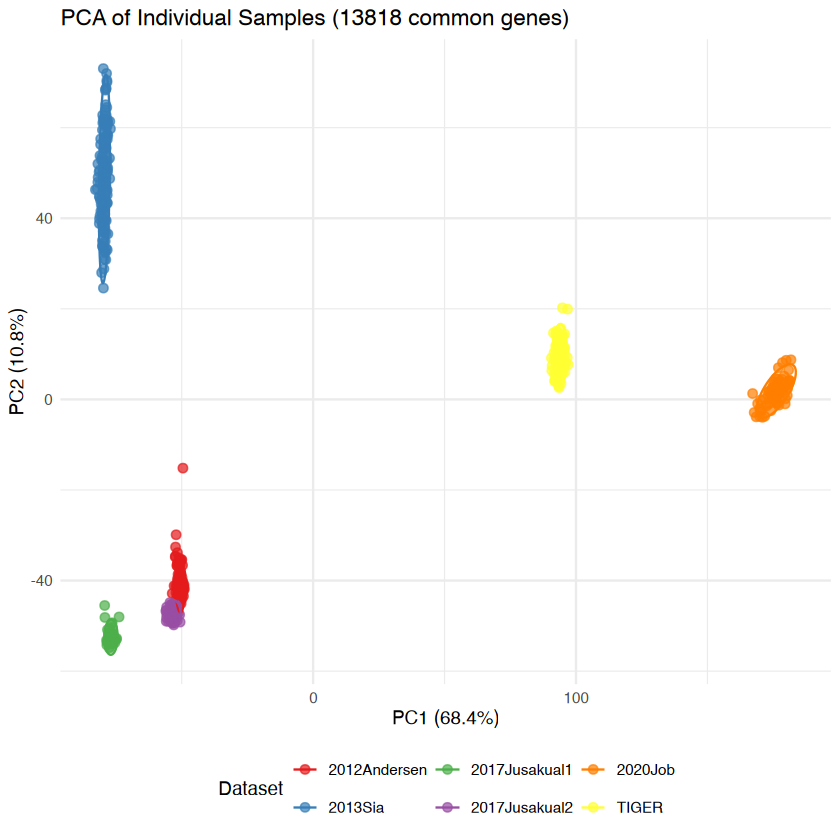

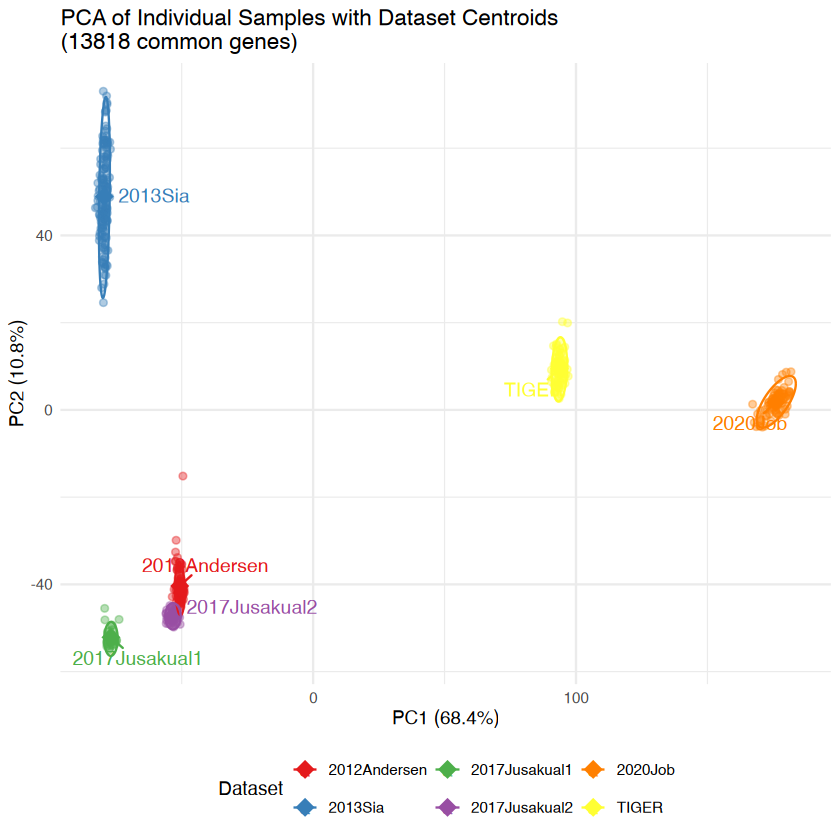

In [50]:
# Function to create a combined matrix of all samples
create_combined_sample_matrix <- function(datasets) {
  # Find common genes across all datasets
  common_genes <- Reduce(intersect, lapply(datasets, rownames))
  
  if(length(common_genes) < 10) {
    # Try using genes present in most datasets
    gene_counts <- table(unlist(lapply(datasets, rownames)))
    threshold <- ceiling(length(datasets) * 0.7)  # 70% of datasets
    frequent_genes <- names(gene_counts[gene_counts >= threshold])
    
    if(length(frequent_genes) > 10) {
      common_genes <- frequent_genes
      cat("Using", length(common_genes), "genes present in at least", threshold, "datasets\n")
    } else {
      stop("Not enough common genes for analysis")
    }
  }
  
  # Initialize the combined matrix list
  combined_matrices <- list()
  dataset_labels <- c()
  
  # Extract and combine data from each dataset
  for(name in names(datasets)) {
    dataset <- datasets[[name]]
    
    # Find genes in this dataset that are in common_genes
    available_genes <- intersect(common_genes, rownames(dataset))
    
    if(length(available_genes) > 0) {
      # Extract data for these genes
      dataset_matrix <- dataset[available_genes, ]
      
      # If some genes from common_genes are missing, add them with NA values
      if(length(available_genes) < length(common_genes)) {
        missing_genes <- setdiff(common_genes, available_genes)
        missing_matrix <- matrix(NA, nrow = length(missing_genes), ncol = ncol(dataset))
        rownames(missing_matrix) <- missing_genes
        colnames(missing_matrix) <- colnames(dataset)
        
        # Combine available and missing genes
        full_matrix <- rbind(dataset_matrix, missing_matrix)
        
        # Sort to match common_genes order
        full_matrix <- full_matrix[common_genes, ]
      } else {
        # All common genes are present, just ensure order
        full_matrix <- dataset_matrix[common_genes, ]
      }
      
      # Add to list
      combined_matrices[[name]] <- full_matrix
      
      # Create dataset labels for each sample
      dataset_labels <- c(dataset_labels, rep(name, ncol(full_matrix)))
    }
  }
  
  # Combine all matrices side by side
  all_samples <- do.call(cbind, combined_matrices)
  
  # Create metadata for plotting
  sample_info <- data.frame(
    SampleID = colnames(all_samples),
    Dataset = dataset_labels
  )
  
  return(list(
    expression_matrix = all_samples,
    sample_info = sample_info,
    common_genes = common_genes
  ))
}

# Perform PCA on all samples
perform_sample_pca <- function(combined_data) {
  # Get expression matrix and transpose it for PCA
  expr_matrix <- combined_data$expression_matrix
  sample_info <- combined_data$sample_info
  
  # Remove rows with any NA values
  complete_rows <- rowSums(is.na(expr_matrix)) == 0
  expr_matrix_complete <- expr_matrix[complete_rows, ]
  
  # Check if we have enough data
  if(nrow(expr_matrix_complete) < 10) {
    stop("Too few genes with complete data across all datasets")
  }
  
  cat("Performing PCA using", nrow(expr_matrix_complete), "complete genes\n")
  
  # Run PCA
  pca_result <- prcomp(t(expr_matrix_complete), scale. = TRUE)
  
  # Create dataframe for plotting
  pca_data <- as.data.frame(pca_result$x)
  pca_data$SampleID <- rownames(pca_data)
  
  # Add dataset information
  pca_data <- merge(pca_data, sample_info, by = "SampleID")
  
  # Calculate variance explained
  var_explained <- (pca_result$sdev^2) / sum(pca_result$sdev^2) * 100
  
  return(list(
    pca_result = pca_result,
    pca_data = pca_data,
    var_explained = var_explained,
    genes_used = nrow(expr_matrix_complete)
  ))
}

# Load required libraries
library(ggplot2)
library(ggrepel)

# Combine all datasets and perform PCA
combined_data <- create_combined_sample_matrix(datasets)
sample_pca <- perform_sample_pca(combined_data)

# Create PCA plot with individual samples
ggplot(sample_pca$pca_data, aes(x = PC1, y = PC2, color = Dataset)) +
  geom_point(alpha = 0.7, size = 2) +
  theme_minimal() +
  labs(title = paste("PCA of Individual Samples (", sample_pca$genes_used, " common genes)", sep=""),
       x = paste0("PC1 (", round(sample_pca$var_explained[1], 1), "%)"),
       y = paste0("PC2 (", round(sample_pca$var_explained[2], 1), "%)")) +
  theme(legend.position = "bottom") +
  # Add ellipses to show dataset clusters
  stat_ellipse(aes(group = Dataset), level = 0.95) +
  scale_color_brewer(palette = "Set1")

# If there are too many samples, create a cleaner plot with centroids
if(nrow(sample_pca$pca_data) > 100) {
  # Calculate centroids of each dataset
  centroids <- aggregate(cbind(PC1, PC2) ~ Dataset, data = sample_pca$pca_data, FUN = mean)
  
  # Add the centroids to the plot
  ggplot(sample_pca$pca_data, aes(x = PC1, y = PC2, color = Dataset)) +
    geom_point(alpha = 0.4, size = 1.5) +
    geom_point(data = centroids, size = 5, shape = 18) +
    geom_text_repel(data = centroids, aes(label = Dataset), size = 4, box.padding = 0.5) +
    theme_minimal() +
    labs(title = paste("PCA of Individual Samples with Dataset Centroids\n(", sample_pca$genes_used, " common genes)", sep=""),
         x = paste0("PC1 (", round(sample_pca$var_explained[1], 1), "%)"),
         y = paste0("PC2 (", round(sample_pca$var_explained[2], 1), "%)")) +
    theme(legend.position = "bottom") +
    stat_ellipse(aes(group = Dataset), level = 0.95) +
    scale_color_brewer(palette = "Set1")
}

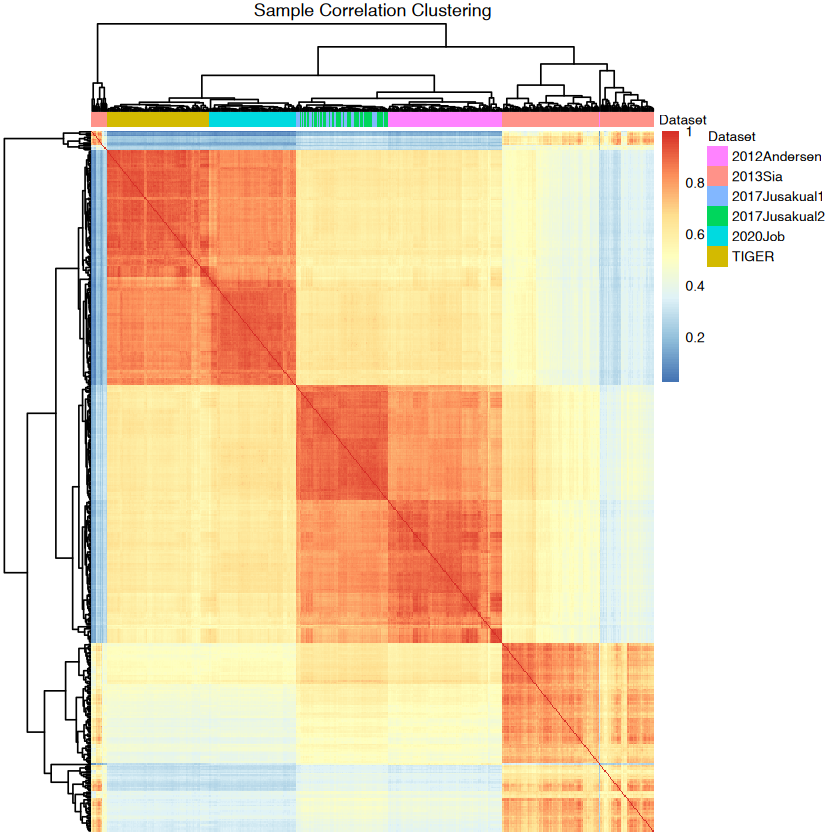

In [51]:
library(pheatmap)

# Compute correlation matrix between samples
expr_matrix_complete <- combined_data$expression_matrix[rowSums(is.na(combined_data$expression_matrix)) == 0,]
sample_cor <- cor(expr_matrix_complete, method = "spearman")

# Create annotation dataframe
sample_annot <- data.frame(Dataset = combined_data$sample_info$Dataset)
rownames(sample_annot) <- combined_data$sample_info$SampleID

# Plot heatmap with hierarchical clustering
pheatmap(sample_cor,
         annotation_col = sample_annot,
         show_colnames = FALSE,
         show_rownames = FALSE,
         main = "Sample Correlation Clustering",
         fontsize = 8)

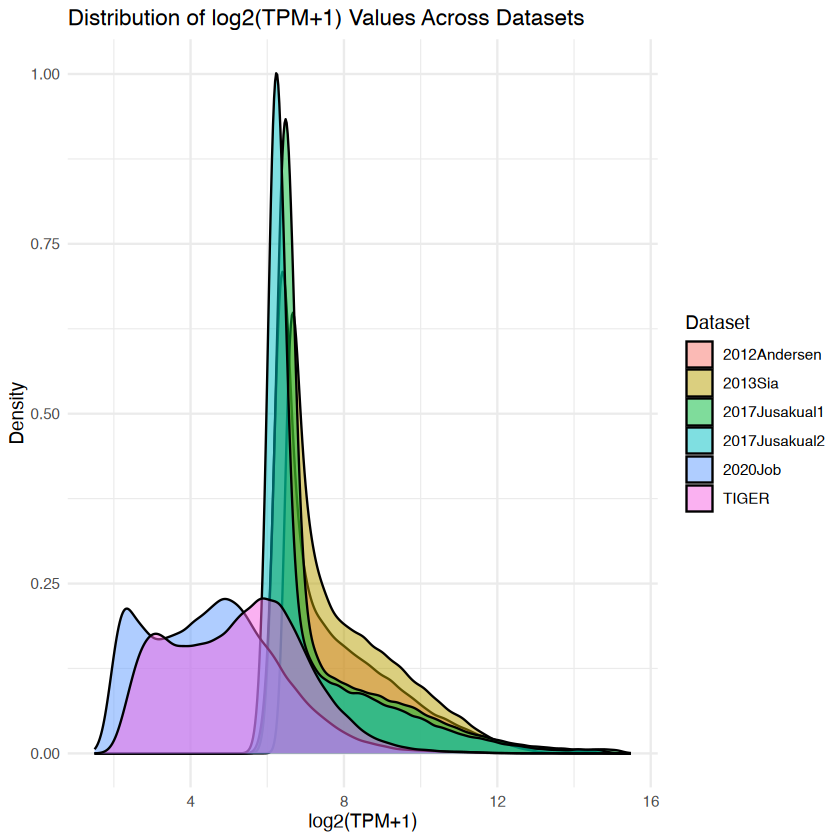

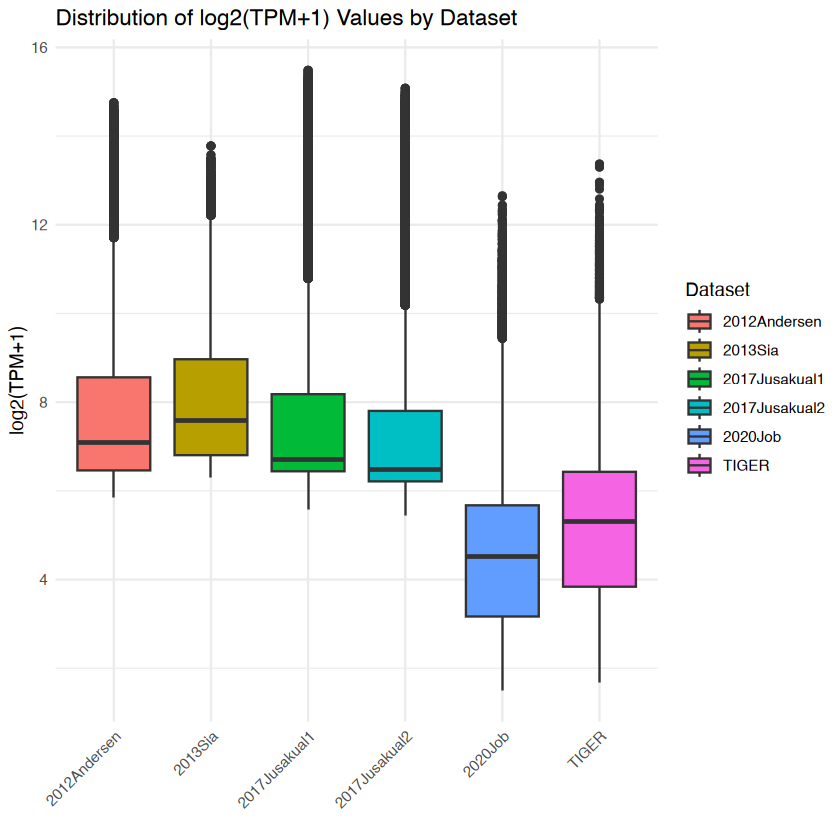

In [52]:
# 分析表达分布
analyze_expression_distributions <- function(datasets) {
  # 为每个数据集提取表达值和密度
  distribution_data <- data.frame()
  
  for(name in names(datasets)) {
    # 提取表达值
    expr_values <- as.vector(as.matrix(datasets[[name]]))
    
    # 随机抽样以减少计算量(如果数据太大)
    if(length(expr_values) > 100000) {
      set.seed(123)  # 设置随机种子以确保可重复性
      expr_values <- sample(expr_values, 100000)
    }
    
    # 添加到数据框
    temp_df <- data.frame(
      Dataset = name,
      Expression = expr_values
    )
    
    distribution_data <- rbind(distribution_data, temp_df)
  }
  
  return(distribution_data)
}

# 分析表达分布
distribution_data <- analyze_expression_distributions(datasets)

# 绘制表达分布图
# 密度图
ggplot(distribution_data, aes(x = Expression, fill = Dataset)) +
  geom_density(alpha = 0.5) +
  theme_minimal() +
  labs(title = "Distribution of log2(TPM+1) Values Across Datasets",
       x = "log2(TPM+1)", y = "Density")

# 箱线图
ggplot(distribution_data, aes(x = Dataset, y = Expression, fill = Dataset)) +
  geom_boxplot() +
  theme_minimal() +
  labs(title = "Distribution of log2(TPM+1) Values by Dataset",
       x = "", y = "log2(TPM+1)") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

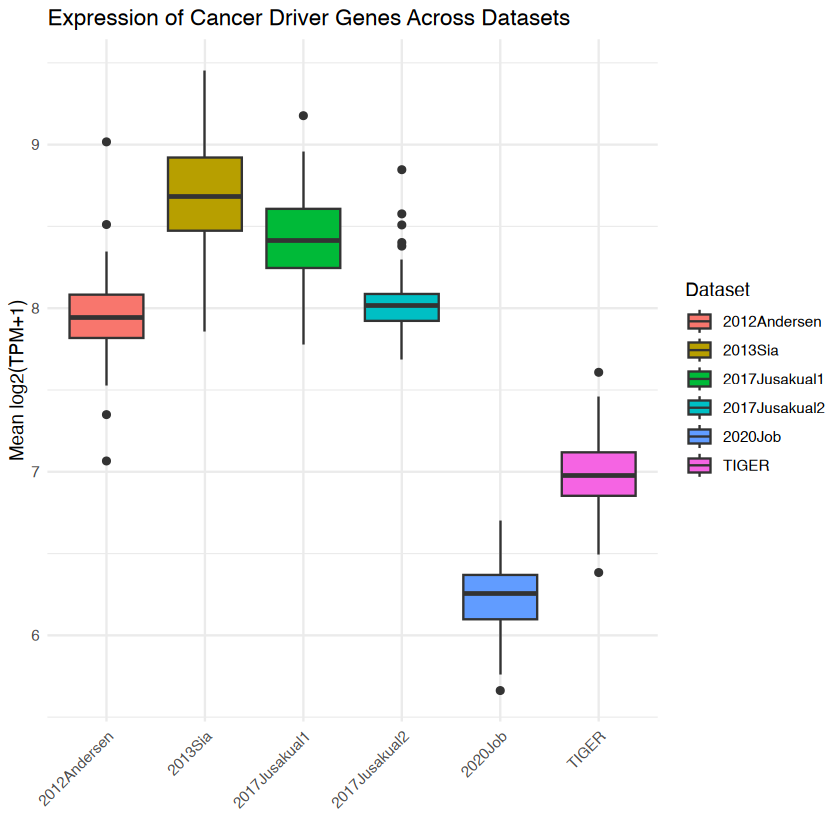

In [53]:
# 分析特定基因集在不同数据集中的表达
analyze_gene_set <- function(datasets, gene_set, gene_set_name = "Gene Set") {
  # 准备结果数据框
  result_data <- data.frame()
  
  for(name in names(datasets)) {
    # 找出数据集中存在的目标基因
    present_genes <- intersect(gene_set, rownames(datasets[[name]]))
    
    if(length(present_genes) > 0) {
      # 提取这些基因的表达值
      gene_expr <- datasets[[name]][present_genes, ]
      
      # 计算每个样本的这些基因的平均表达
      mean_expr <- colMeans(gene_expr, na.rm = TRUE)
      
      # 添加到结果数据框
      temp_df <- data.frame(
        Dataset = name,
        Sample = colnames(datasets[[name]]),
        Mean_Expression = mean_expr,
        Genes_Found = length(present_genes),
        Total_Genes = length(gene_set)
      )
      
      result_data <- rbind(result_data, temp_df)
    }
  }
  
  # 添加基因集名称
  result_data$Gene_Set <- gene_set_name
  
  return(result_data)
}

# 示例：分析一组感兴趣的基因
# 可以是您感兴趣的通路基因，如细胞周期、炎症相关等
interest_genes <- c("TP53", "EGFR", "KRAS", "PIK3CA", "PTEN", "RB1", "CDKN2A", "MYC")
gene_set_analysis <- analyze_gene_set(datasets, interest_genes, "Cancer Driver Genes")

# 绘制基因集表达箱线图
ggplot(gene_set_analysis, aes(x = Dataset, y = Mean_Expression, fill = Dataset)) +
  geom_boxplot() +
  theme_minimal() +
  labs(title = paste("Expression of", gene_set_analysis$Gene_Set[1], "Across Datasets"),
       x = "", y = "Mean log2(TPM+1)") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [54]:
# 找出共同基因
common_genes <- Reduce(intersect, lapply(datasets, rownames))
cat(sprintf("Common genes: %d\n", length(common_genes)))

Common genes: 13818


In [55]:
# 提取共同基因表达数据并合并
combined_expr <- NULL
batch_labels <- c()
sample_info <- data.frame(
  Sample = character(),
  Dataset = character(),
  stringsAsFactors = FALSE
)

for (name in names(datasets)) {
  current_data <- datasets[[name]][common_genes, ]
  
  # 记录样本信息
  current_samples <- data.frame(
    Sample = colnames(current_data),
    Dataset = rep(name, ncol(current_data)),
    stringsAsFactors = FALSE
  )
  sample_info <- rbind(sample_info, current_samples)
  
  # 合并表达矩阵
  if (is.null(combined_expr)) {
    combined_expr <- current_data
  } else {
    combined_expr <- cbind(combined_expr, current_data)
  }
  
  # 记录批次信息
  batch_labels <- c(batch_labels, rep(name, ncol(current_data)))
}

# 确保行列名正确
rownames(combined_expr) <- common_genes
colnames(combined_expr) <- sample_info$Sample

In [56]:
dim(combined_expr)
head(combined_expr)

[1] 13818   506

,GSM653074,GSM653075,GSM653076,GSM653077,GSM653078,GSM653079,GSM653080,GSM653081,GSM653082,GSM653083,⋯,GSM1979651,GSM1979653,GSM1979655,GSM1979657,GSM1979659,GSM1979661,GSM1979663,GSM1979665,GSM1979667,GSM1979669
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TMSB4X,14.58849,14.37804,14.43585,14.55060,14.46258,14.75194,14.68324,14.68324,14.55060,14.68324,⋯,9.57430,9.85534,10.48780,10.10700,9.43092,9.42252,9.73100,9.95538,10.21690,9.44588
FTL,14.55060,14.48784,14.68324,14.63357,14.58849,14.55060,14.41796,14.58849,14.75194,14.63357,⋯,11.60040,11.69480,11.99720,11.05600,11.26690,11.61110,11.63690,11.69060,11.99960,11.18470
RPS16,14.31688,13.89592,14.31688,14.46258,14.01909,14.33634,14.43585,14.48784,14.01909,14.51549,⋯,10.39520,10.65450,10.51940,10.24160,10.70040,10.46250,10.95170,11.19180,10.43080,10.73820
RPS19,14.23992,13.62670,13.94120,14.39558,13.86704,14.25680,14.39558,14.41796,14.08054,14.29672,⋯,9.18571,9.52257,9.47889,8.87100,9.59415,9.75508,9.81604,10.43400,9.91940,9.34880
RPL6,14.15315,13.72447,13.97430,14.68324,13.79662,14.41796,14.23992,14.55060,14.13651,14.33634,⋯,7.35265,7.45116,7.21891,7.26775,7.47170,7.40288,7.51500,7.88209,7.62906,7.09613
RPS29,14.17171,14.17171,14.08054,14.48784,13.85173,14.20439,14.35912,14.63357,14.04842,14.39558,⋯,8.26047,8.31149,8.60483,8.02157,8.82492,8.39303,8.26092,8.63168,8.15748,7.88098


In [57]:
# 检查合并后的数据维度
cat(sprintf("Merged dataset: %dGene x %dSample\n", nrow(combined_expr), ncol(combined_expr)))

Merged dataset: 13818Gene x 506Sample


In [58]:
save(combined_expr, file = "./combined_expr_before_correction_microarray.rds")

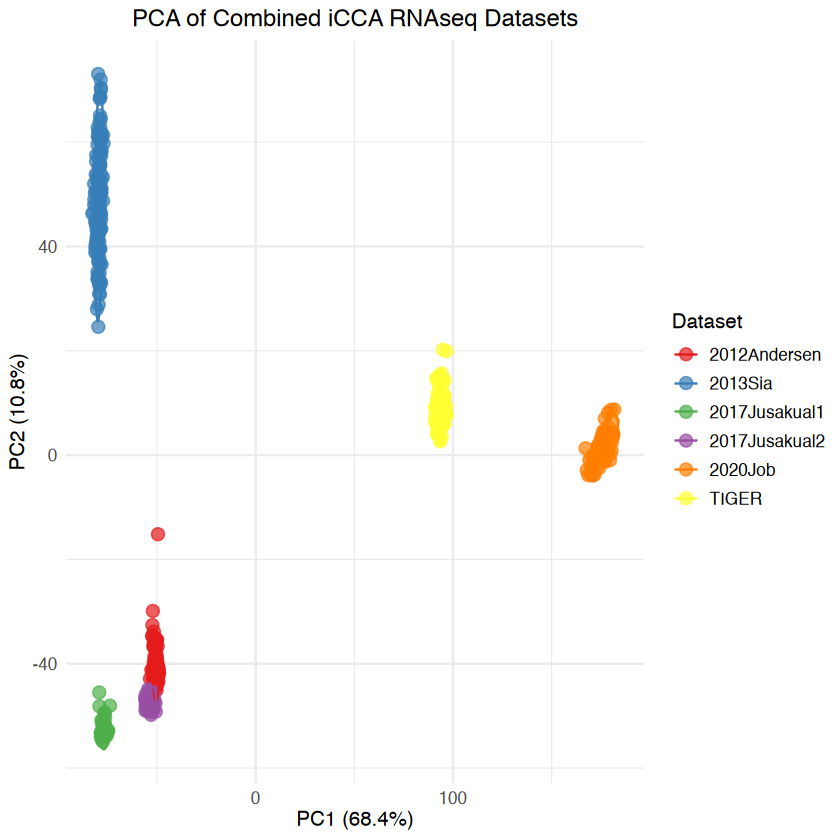

In [59]:
# PCA分析可视化批次效应
pca_res <- prcomp(t(combined_expr), scale = TRUE, center = TRUE)
var_explained <- (pca_res$sdev^2) / sum(pca_res$sdev^2) * 100

# 提取前两个主成分用于绘图
pca_data <- as.data.frame(pca_res$x[, 1:10])
pca_data$Dataset <- factor(batch_labels)

# 绘制PCA图
p1 <- ggplot(pca_data, aes(x = PC1, y = PC2, color = Dataset)) +
  geom_point(size = 3, alpha = 0.7) +
  stat_ellipse(aes(group = Dataset), level = 0.95) +
  labs(
    title = "PCA of Combined iCCA RNAseq Datasets",
    x = sprintf("PC1 (%.1f%%)", var_explained[1]),
    y = sprintf("PC2 (%.1f%%)", var_explained[2])
  ) +
  theme_minimal() +
  theme(
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
    legend.title = element_text(size = 12),
    legend.text = element_text(size = 10),
    axis.title = element_text(size = 12),
    axis.text = element_text(size = 10)
  ) +
  scale_color_brewer(palette = "Set1")
p1
# 保存PCA图
ggsave("PCA_before_correction_microarray.pdf", p1, width = 10, height = 8)

In [60]:
# 定量评估批次效应 - 检查主成分与批次的相关性
pc_batch_correlation <- function(pca_result, batch_factor, n_pcs = 10) {
  n_pcs <- min(n_pcs, ncol(pca_result$x))
  pcs <- pca_result$x[, 1:n_pcs]
  result <- data.frame(PC = character(), R_squared = numeric(), P_value = numeric())
  
  for (i in 1:ncol(pcs)) {
    pc_name <- colnames(pcs)[i]
    # ANOVA分析PC与批次的关系
    fit <- aov(pcs[, i] ~ factor(batch_factor))
    r_squared <- summary(fit)[[1]]["Sum Sq"][1, ] / sum(summary(fit)[[1]]["Sum Sq"])
    p_value <- summary(fit)[[1]]["Pr(>F)"][1, ]
    
    result <- rbind(result, data.frame(
      PC = pc_name,
      R_squared = r_squared,
      P_value = p_value,
      stringsAsFactors = FALSE
    ))
  }
  
  return(result)
}

# 计算PCs与批次的相关性
pc_batch_corr <- pc_batch_correlation(pca_res, batch_labels)
print(pc_batch_corr)

     PC  R_squared       P_value
1   PC1 0.99969500  0.000000e+00
2   PC2 0.97513065  0.000000e+00
3   PC3 0.95557078  0.000000e+00
4   PC4 0.86120566 9.387316e-212
5   PC5 0.07720797  1.301991e-07
6   PC6 0.07725305  1.287255e-07
7   PC7 0.01970010  7.585731e-02
8   PC8 0.01027441  3.944001e-01
9   PC9 0.02563804  2.314526e-02
10 PC10 0.08267914  3.246362e-08


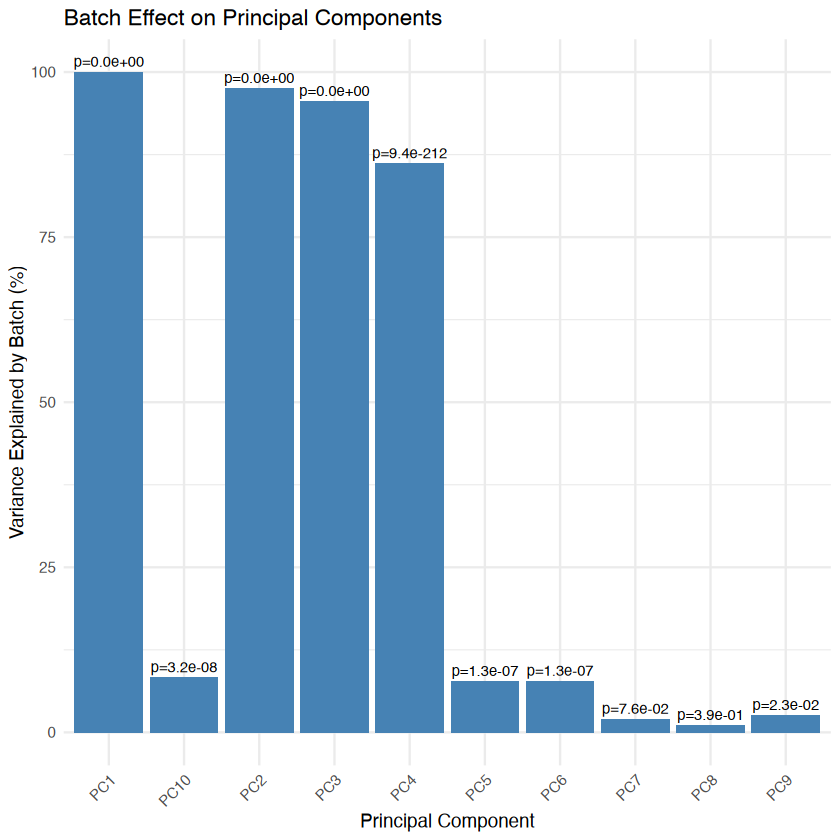

In [61]:
# 绘制主成分与批次相关性条形图
p2 <- ggplot(pc_batch_corr, aes(x = PC, y = R_squared * 100)) +
  geom_bar(stat = "identity", fill = "steelblue") +
  geom_text(aes(label = sprintf("p=%.1e", P_value)), vjust = -0.5, size = 3) +
  theme_minimal() +
  labs(
    title = "Batch Effect on Principal Components",
    x = "Principal Component",
    y = "Variance Explained by Batch (%)"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
p2
# 保存批次效应评估图
ggsave("PC_batch_correlation_microarray.pdf", p2, width = 10, height = 6)

In [62]:
# 基于PC批次相关性结果判断是否需要批次校正
# 如果PC1/PC2与批次有显著相关性(R^2>0.3, p<0.05)，则需要校正
significant_batch_effect <- (
  (pc_batch_corr$R_squared[1] > 0.3 & pc_batch_corr$P_value[1] < 0.05) |
  (pc_batch_corr$R_squared[2] > 0.3 & pc_batch_corr$P_value[2] < 0.05)
)

cat(sprintf("Batch effect evaluation: Main PC and batch correlation R^2(PC1)=%.2f, p=%.1e\n", 
            pc_batch_corr$R_squared[1], pc_batch_corr$P_value[1]))
cat(sprintf("Batch effect is significant (R^2>0.3 & p<0.05): %s\n", 
            ifelse(significant_batch_effect, "Yes - Correction recommended", "No - Correction optional")))

Batch effect evaluation: Main PC and batch correlation R^2(PC1)=1.00, p=0.0e+00
Batch effect is significant (R^2>0.3 & p<0.05): Yes - Correction recommended


In [63]:
# Ensure the limma library is loaded
if (!requireNamespace("limma", quietly = TRUE)) {
  if (!requireNamespace("BiocManager", quietly = TRUE)) {
    install.packages("BiocManager")
  }
  BiocManager::install("limma")
}
library(limma)

cat("Performing batch correction using limma::removeBatchEffect...\n")

# 'combined_expr' is your log-transformed TPM data (genes as rows, samples as columns)
# 'batch_labels' is your vector indicating the batch for each sample

# Ensure batch_labels is a factor if it's not already
# (though removeBatchEffect can handle a character vector for the batch argument)
batch_factor <- factor(batch_labels)

# Apply limma::removeBatchEffect
# For log-TPM data, and when not specifying other covariates to protect,
# this is a common approach.
# removeBatchEffect expects log-transformed data.
corrected_expr_limma <- removeBatchEffect(
  x = combined_expr,
  batch = batch_factor
  # You can optionally add a design matrix if you have covariates to preserve,
  # e.g., design = model.matrix(~ some_other_covariate, data = sample_info_df)
  # If no other covariates, it defaults to preserving the overall mean.
)

cat("Batch correction with limma completed.\n")

Performing batch correction using limma::removeBatchEffect...
Batch correction with limma completed.


In [64]:
save(corrected_expr_limma, file ="./combined_expr_after_correction_microarray.rds")

In [65]:
# --- Validate correction effect ---
cat("Performing PCA on limma-corrected data to validate correction effect...\n")
pca_corrected <- prcomp(t(corrected_expr_limma), scale. = TRUE, center = TRUE)
var_explained_corrected <- (pca_corrected$sdev^2) / sum(pca_corrected$sdev^2) * 100

pca_data_corrected <- as.data.frame(pca_corrected$x[, 1:10]) # Using first 10 PCs
pca_data_corrected$Dataset <- factor(batch_labels) # Use the original batch_labels for coloring

Performing PCA on limma-corrected data to validate correction effect...


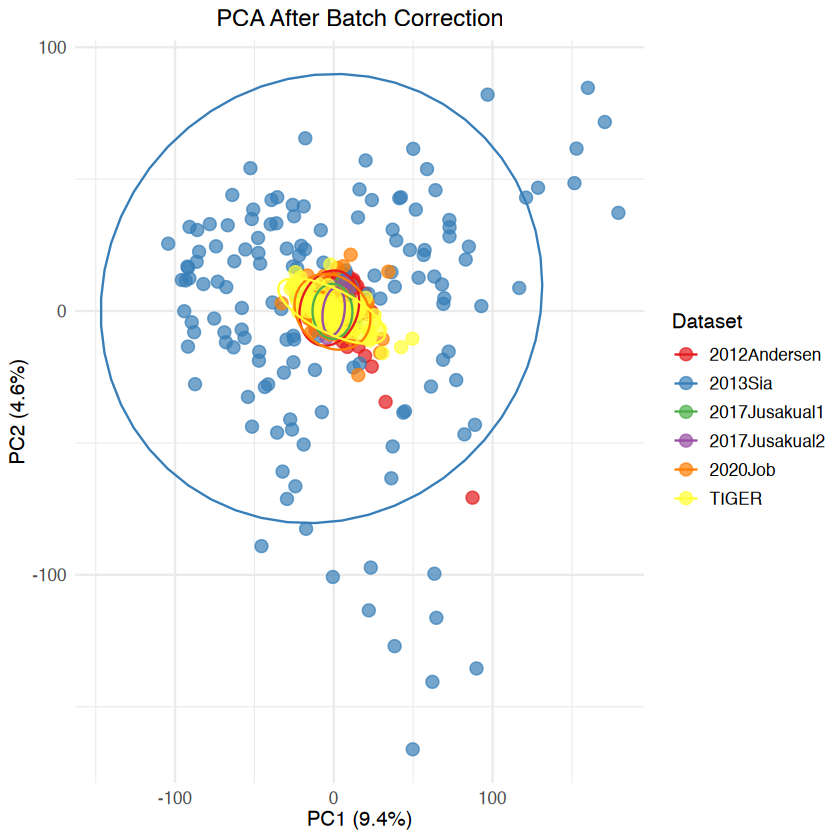

In [66]:
# 绘制校正后的PCA图
p3 <- ggplot(pca_data_corrected, aes(x = PC1, y = PC2, color = Dataset)) +
  geom_point(size = 3, alpha = 0.7) +
  stat_ellipse(aes(group = Dataset), level = 0.95) +
  labs(
    title = "PCA After Batch Correction",
    x = sprintf("PC1 (%.1f%%)", var_explained_corrected[1]),
    y = sprintf("PC2 (%.1f%%)", var_explained_corrected[2])
  ) +
  theme_minimal() +
  theme(
    legend.position = "right",
    plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
    legend.title = element_text(size = 12),
    legend.text = element_text(size = 10),
    axis.title = element_text(size = 12),
    axis.text = element_text(size = 10)
  ) +
  scale_color_brewer(palette = "Set1")
p3
# 保存校正后PCA图
ggsave("PCA_after_correction_microarray.pdf", p3, width = 10, height = 8)

Quantitatively evaluating batch effect on limma-corrected data...
     PC    R_squared P_value
1   PC1 7.457599e-28       1
2   PC2 2.013130e-27       1
3   PC3 1.764765e-29       1
4   PC4 9.236743e-30       1
5   PC5 2.989587e-28       1
6   PC6 2.728191e-28       1
7   PC7 1.896491e-27       1
8   PC8 1.221857e-27       1
9   PC9 3.928261e-28       1
10 PC10 3.529288e-28       1
Batch effect evaluation AFTER LIMMA: Main PC and batch correlation R^2(PC1)=0.00, p=1.0e+00
Batch effect is still significant (R^2>0.3 & p<0.05) after limma: No


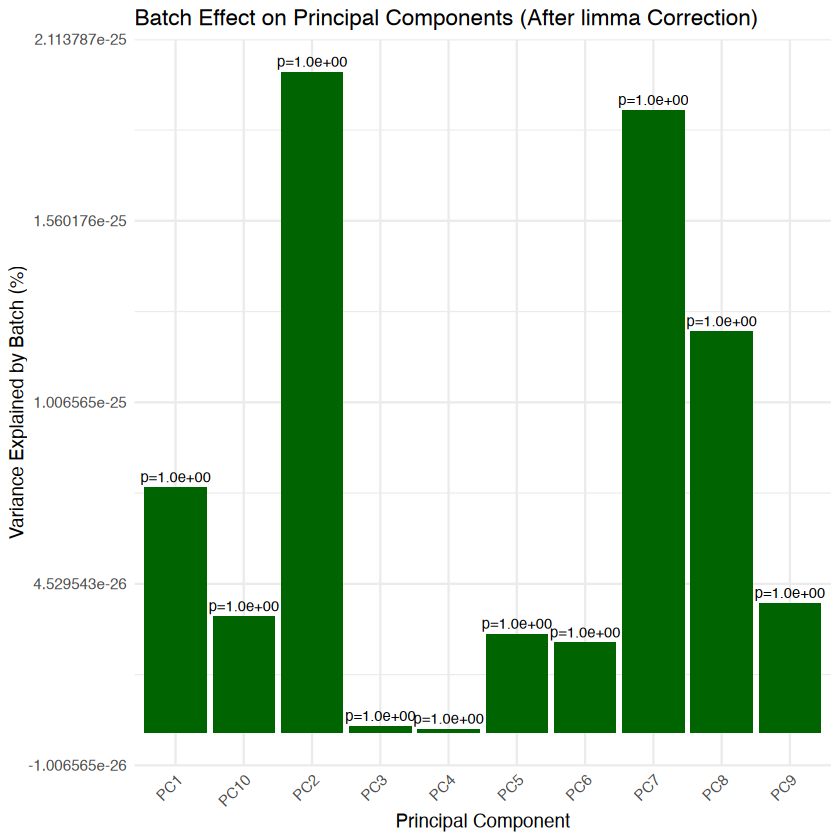

In [67]:
# Define fig_dir if not already defined (replace with your actual figure directory)
# fig_dir <- "path/to/your/figures"
# ggsave(file.path(fig_dir, "PCA_after_limma_correction.pdf"), p_corrected, width = 10, height = 8)

# --- Quantitatively re-evaluate batch effect on corrected data ---
cat("Quantitatively evaluating batch effect on limma-corrected data...\n")
pc_batch_corr_corrected <- pc_batch_correlation(pca_corrected, batch_labels) # Using your existing function
print(pc_batch_corr_corrected)

# Plot the R-squared values for the corrected data
p_corr_corrected_plot <- ggplot(pc_batch_corr_corrected, aes(x = PC, y = R_squared * 100)) +
  geom_bar(stat = "identity", fill = "darkgreen") + # Changed color for distinction
  geom_text(aes(label = sprintf("p=%.1e", P_value)), vjust = -0.5, size = 3) +
  theme_minimal() +
  labs(
    title = "Batch Effect on Principal Components (After limma Correction)",
    x = "Principal Component",
    y = "Variance Explained by Batch (%)"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

print(p_corr_corrected_plot)
ggsave("PC_batch_correlation_after_limma_microarray.pdf", p_corr_corrected_plot, width = 10, height = 6)

# --- Re-evaluate if correction was sufficient ---
significant_batch_effect_after_limma <- (
  (pc_batch_corr_corrected$R_squared[1] > 0.3 & pc_batch_corr_corrected$P_value[1] < 0.05) |
  (pc_batch_corr_corrected$R_squared[2] > 0.3 & pc_batch_corr_corrected$P_value[2] < 0.05)
)

cat(sprintf("Batch effect evaluation AFTER LIMMA: Main PC and batch correlation R^2(PC1)=%.2f, p=%.1e\n",
            pc_batch_corr_corrected$R_squared[1], pc_batch_corr_corrected$P_value[1]))
cat(sprintf("Batch effect is still significant (R^2>0.3 & p<0.05) after limma: %s\n",
            ifelse(significant_batch_effect_after_limma, "Yes", "No")))

In [68]:
all(colnames(combined_data) %in% sample_info$SampleID)  # 应为 TRUE

[1] TRUE